# 03 — Análisis exploratorio de datos (EDA) de AFG2

**Autor:** Jason Sepúlveda S.
**Proyecto:** Evaluación experimental de la extracción automática y la representación
persistente de decisiones organizacionales frente a Recuperación Aumentada (RAG)
**Depende de:** [`00-jss-corpus-y-auditoria.ipynb`](00-jss-corpus-y-auditoria.ipynb) ·
[`01-jss-viabilidad-e3.ipynb`](01-jss-viabilidad-e3.ipynb) ·
[`02-jss-transcripciones.ipynb`](02-jss-transcripciones.ipynb)

---

## Qué hace este notebook

Es el análisis exploratorio de datos (EDA, del inglés *exploratory data analysis*) del curso AFG2.
Un EDA examina los datos **antes de modelar**, con tres propósitos: entender qué contienen,
detectar lo que podría invalidar un análisis posterior y decidir con evidencia cómo prepararlos.
Aquí se aplica a las **14 series AMI** de la muestra de OE1 y recorre, en este orden:

1. El plan: objetivos, preguntas orientadoras e hipótesis exploratorias (§0).
2. De dónde vienen los datos y cómo se muestrearon (§1).
3. Su calidad: diccionario, reglas de consistencia, duplicados, faltantes y atípicos (§2, §3, §5).
4. Su forma: análisis univariado, bivariado, de correlaciones, multivariado y temporal (§4, §6–§9).
5. Las preguntas concretas del proyecto que los datos pueden contestar hoy (§10).
6. La síntesis: qué cambia para el modelado y qué queda por repetir (§11–§12).

## Qué NO hace este notebook

- **No evalúa ningún modelo.** Al momento de este análisis (2026-09) no se había corrido OpenKOS
  ni ningún modelo de lenguaje; este notebook describe la materia prima, no el resultado del
  experimento (los notebooks 05 a 07 registran lo que vino después).
- **No lee ni muestra texto.** Solo aparecen identificadores, conteos y estadísticas agregadas.
  El [ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md) prohíbe mirar el
  contenido de las series de evaluación, y este análisis recorre las 14 series; por eso se
  limita a lo estructural (§12 incluye una verificación automática de esta regla).
- **No es el conjunto de referencia.** Las decisiones que se cuentan son las frases del
  resumen abstractivo de AMI, no las etiquetas humanas de OE1 (decisión D3).

## La regla de este proyecto, también aquí

Ninguna cifra se calcula en una celda. Cada número viene de una función con test del paquete
`afg` (`afg.eda`, `afg.audit`); el notebook importa, llama, grafica e interpreta
([`CONTRIBUTING.md` §7.1](../CONTRIBUTING.md)). Las interpretaciones se escribieron **después**
de ejecutar y citan las cifras que produjo cada celda.

In [1]:
import platform
from dataclasses import asdict
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Rectangle

from afg import audit, eda
from afg.eda.figures import apply_style
from afg.eda.tables import TOKENS_PER_WORD
from afg.eda.tables import format_thousands as es
from afg.shared.config import load_corpus_config
from afg.shared.paths import AMI_DIR, PROJECT_ROOT, TRANSCRIPTS_DIR

SEED = 0
np.random.seed(SEED)


pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 70)
sns.set_theme(style="whitegrid", palette="colorblind")
apply_style()

# Guard: the corpus and the frozen transcripts are gitignored.
if not AMI_DIR.exists() or not any(AMI_DIR.glob("abstractive/*.xml")):
    raise SystemExit(
        f"El corpus AMI no esta en {AMI_DIR}.\nDescargalo primero con:  uv run afg corpus download"
    )
if not TRANSCRIPTS_DIR.exists() or not any(TRANSCRIPTS_DIR.glob("*.jsonl")):
    raise SystemExit(
        f"Las transcripciones congeladas no estan en {TRANSCRIPTS_DIR}.\n"
        "Generalas primero con:  uv run afg corpus transcripts"
    )

CFG = load_corpus_config()["oe1"]
SERIES, DEV, EVAL = CFG["series"], CFG["development_series"], CFG["evaluation_series"]

# Colour-blind-safe palette (seaborn "colorblind"); one colour per site, role and position.
PAL = sns.color_palette("colorblind")
SITE_COLOR = dict(zip(["ES", "IS", "TS"], PAL[:3], strict=False))
ROLE_COLOR = dict(zip(["PM", "ID", "ME", "UI"], PAL[:4], strict=False))
POS_COLOR = dict(zip(["a", "b", "c", "d"], sns.color_palette("viridis", 4), strict=False))

LABEL = {
    "duration_seconds": "Duración (s)",
    "n_turns": "Turnos",
    "n_words": "Palabras",
    "n_dialogue_acts": "Actos de diálogo",
    "n_decisions": "Decisiones",
    "n_anchored_decisions": "Decisiones con evidencia",
    "approx_tokens": "Tokens estimados",
    "context_ratio": "Tokens / ventana",
    "n_tokens": "Tokens de contenido",
    "n_chars": "Caracteres",
    "n_evidence_acts": "Actos de evidencia",
    "talk_share": "Proporción de habla",
    "n_decision_acts": "Actos de decisión",
    "overlap": "Coeficiente de solapamiento",
    "shared_tokens": "Tokens compartidos",
    "shorter_tokens": "Tokens de la decisión más corta",
    "meeting_distance": "Distancia (reuniones)",
}

# One call reads the corpus and builds the five analysis levels.
TABLES = eda.load_eda_tables()
SERIES_T, MEETING, SPEAKER = TABLES.series, TABLES.meeting, TABLES.speaker_meeting
DECISION, PAIR, TURNS = TABLES.decision, TABLES.pair, TABLES.turns
EVIDENCE, ACT_IDS = TABLES.evidence, TABLES.act_ids
LEVELS = {
    "serie": SERIES_T,
    "reunión": MEETING,
    "hablante-reunión": SPEAKER,
    "decisión": DECISION,
    "par": PAIR,
}

print(f"Corpus en {AMI_DIR.relative_to(PROJECT_ROOT)}")
print(f"Series: {len(SERIES)} (desarrollo {len(DEV)} / evaluación {len(EVAL)})")
print({nivel: len(tabla) for nivel, tabla in LEVELS.items()})

Corpus en data/raw/ami
Series: 14 (desarrollo 3 / evaluación 11)
{'serie': 14, 'reunión': 56, 'hablante-reunión': 224, 'decisión': 343, 'par': 3071}


---

# 0. Plan del EDA

## 0.1 Para qué sirve este EDA

El proyecto compara tres formas de responder preguntas sobre decisiones que cambian a lo largo de
una serie de reuniones (C1, C2 y C3; ver el documento de objetivos). Antes de gastar horas de
anotación humana y de cómputo en esas comparaciones, hay que saber si los datos de entrada
son lo que se supone. Los objetivos del EDA son cuatro:

1. **Caracterizar** cada nivel de análisis (serie, reunión, hablante-reunión, decisión, par).
2. **Detectar** problemas de calidad que contaminarían el modelado: duplicados, faltantes y
   valores atípicos.
3. **Identificar** relaciones, confusores y estructura que condicionen el diseño del experimento.
4. **Traducir** lo hallado en decisiones concretas: limpieza, estratificación del banco de
   preguntas, tamaño de los fragmentos de C1 y ventana de contexto de C2.

## 0.2 Preguntas orientadoras

| | Pregunta | Se responde en |
|---|---|---|
| **P1** | ¿Caben las reuniones completas en la ventana de contexto del modelo (12.288 tokens)? | §4, §10.1 |
| **P2** | ¿La tasa de pares que deja pasar el filtro de bloqueo depende de la longitud de las frases de decisión? | §10.3 |
| **P3** | ¿Hay diferencias por sitio de grabación (ES, IS, TS) en volumen, estructura o calidad? | §3, §6, §7 |
| **P4** | ¿Cambia la actividad de decisión a lo largo de la serie, de la reunión a a la d? | §9 |
| **P5** | ¿Qué datos faltan y por qué faltan? ¿Es seguro no imputarlos? | §3 |
| **P6** | ¿A qué distancia, en reuniones, quedan los pares candidatos? ¿Se pierde algo con la distancia? | §10.2 |
| **P7** | ¿Quién respalda las decisiones y esa autoría depende del sitio o simplemente de cuánto habla cada rol? | §6, §7, §10.5 |
| **P8** | ¿Hay estructura multivariada (grupos, componentes) que justifique estratos de muestreo adicionales? | §8 |
| **P9** | ¿Qué tan sensible es el filtro de bloqueo a su punto de operación? | §10.4 |

## 0.3 Hipótesis exploratorias

Son conjeturas verificables con estos datos, **distintas de las hipótesis H1–H4 del proyecto**,
que solo pueden contrastarse con el experimento (OE2 a OE4). Cada una indica a cuál se vincula.

| | Hipótesis exploratoria | Vínculo con el proyecto |
|---|---|---|
| **HE1** | Casi todas las reuniones caben en la ventana de contexto, pero las más largas con poco margen. | Condiciona C2 (extracción por reunión) y el tamaño de fragmento de C1; sostiene la comparación H1 |
| **HE2** | La proporción de pares que pasa solo el coeficiente de solapamiento es mayor entre frases cortas. | Explica por qué el filtro exige además dos tokens compartidos (D9); afecta el volumen de E3 (H1) |
| **HE3** | Los sitios difieren en volumen de habla pero no en la estructura de las decisiones. | Justifica balancear por sitio y no por lengua (D7, D8) |
| **HE4** | La actividad de decisión crece de la reunión a a la d. | Más decisiones tardías, más relaciones posibles entre reuniones (H1, H2) |
| **HE5** | Los faltantes son estructurales (metadatos del archivo), no azarosos, y no tocan las etiquetas de referencia. | Respalda no imputar (D3) |
| **HE6** | Las reuniones forman un continuo de tamaño, sin grupos nítidos. | Si fuera cierta, bastan sitio y posición como estratos |

H3 (la dirección de las relaciones como modo de falla) y H4 (respuestas confiadas pero
desactualizadas) **no son contrastables con un EDA**: requieren la salida de los sistemas.
Se deja constancia para no sugerir que esta exploración las respalda.

## 0.4 Mapa de etapas, guía del curso y secciones

Las ocho etapas del curso y los puntos de la guía de EDA se cubren así:

| Etapa del curso | Punto de la guía | Sección |
|---|---|---|
| 1. Problema y objetivos | Plan y buenas prácticas | §0 |
| 2. Proveniencia y muestreo | Revisión general | §1 |
| 3. Calidad de datos | Revisión general y diccionario · valores faltantes · valores atípicos | §2, §3, §5 |
| 4. Análisis univariado | Univariado y visualización | §4 |
| 5. Análisis bivariado | Bivariado, dependencias y correlaciones | §6, §7 |
| 6. Análisis multivariado | Multivariado, dependencias en el tiempo | §8, §9 |
| 7. Análisis dirigido por preguntas | Preguntas orientadoras | §10 |
| 8. Síntesis | Conclusiones y checklist del preinforme | §11 |
| Transversal | Buenas prácticas: ética y reproducibilidad | §12 |

La visualización no es una sección aparte: cada gráfico responde a una pregunta de su sección,
usa una paleta apta para daltonismo y rotula sus ejes en español.

---

# 1. Proveniencia y muestreo

## 1.1 De dónde vienen los datos

Los datos son el **AMI Meeting Corpus** (Carletta et al., 2006), publicado con licencia
CC BY 4.0. Lo que importa para el análisis es cómo se generó cada capa; el detalle está en los
notebooks [00](00-jss-corpus-y-auditoria.ipynb) (capas y auditoría) y
[02](02-jss-transcripciones.ipynb) (transcripciones congeladas), y no se repite aquí.

- **Escenario y habla actuada.** Los participantes representan roles asignados (jefe de proyecto
  `PM`, diseñador industrial `ID`, diseñador de interfaz `UI` y especialista en marketing `ME`) en
  el diseño de un control remoto. Las decisiones son reales como actos conversacionales; sus
  consecuencias organizacionales son simuladas (notebook 00, §3.1).
- **Transcripción.** Hecha a mano por AMI, reunión por reunión.
- **Decisiones.** No salen de la transcripción: son las frases de la sección `DECISIONS` del
  **resumen abstractivo**, escrito por anotadores de AMI. Por eso una
  decisión es una frase de resumen, no un fragmento de diálogo.
- **Evidencia.** La capa `summlink` enlaza cada frase del resumen con los actos de diálogo que
  la respaldan. Una decisión sin enlaces no tiene evidencia ("sin anclaje").
- **Pares.** Se generan aquí: todo par de decisiones de reuniones distintas de una misma serie,
  con el filtro de bloqueo de OE1 marcando los candidatos (coeficiente de solapamiento de al
  menos 0,30 y al menos dos tokens compartidos).

## 1.2 Los niveles de análisis

In [2]:
levels = pd.DataFrame(
    [
        ("Serie", "una serie AMI de cuatro reuniones (a, b, c, d)", len(SERIES_T)),
        ("Reunión", "una reunión", len(MEETING)),
        ("Hablante-reunión", "un hablante en una reunión", len(SPEAKER)),
        ("Decisión", "una frase de la sección DECISIONS del resumen abstractivo", len(DECISION)),
        ("Par", "un par de decisiones de reuniones distintas de la misma serie", len(PAIR)),
        (
            "Turno (auxiliar)",
            "un turno de habla; solo alimenta las variables de reunión y hablante",
            len(TURNS),
        ),
    ],
    columns=["nivel", "unidad de observación", "n"],
)
display(levels)
print(f"Pares candidatos tras el filtro: {int(PAIR['is_candidate'].sum())} de {es(len(PAIR))}")

,nivel,unidad de observación,n
0,Serie,"una serie AMI de cuatro reuniones (a, b, c, d)",14
1,Reunión,una reunión,56
2,Hablante-reunión,un hablante en una reunión,224
3,Decisión,una frase de la sección DECISIONS del resumen abstractivo,343
4,Par,un par de decisiones de reuniones distintas de la misma serie,3071
5,Turno (auxiliar),un turno de habla; solo alimenta las variables de reunión y hablante,25857


Pares candidatos tras el filtro: 92 de 3.071


Son cinco tablas de análisis más una auxiliar: el turno, que no se analiza como unidad pero
alimenta las variables de reunión y de hablante.

## 1.3 Muestra de 14 series frente a las series elegibles

La muestra no es aleatoria: es una **elección con criterios registrados antes de anotar**
([ADR 0004](../docs/decisions/0004-adr-oe1-series-selection.md)): `summlink` en las cuatro reuniones,
las seis series con segmentación de decisiones (DDS) incluidas, balance por sitio de grabación
y, dentro de cada sitio, preferencia por volumen de decisiones.

In [3]:
elig = audit.series_eligibility().assign(in_sample=lambda d: d["series_id"].isin(SERIES))
print(f"Series con las 4 reuniones en la capa abstractiva: {len(elig)}")
print(f"  con summlink en las 4:   {int(elig['summlink_on_4_of_4'].sum())}")
print(f"  con capa DDS:            {int(elig['has_dds'].sum())}")
print(f"  en la muestra de OE1:    {int(elig['in_sample'].sum())}")
print(f"Decisiones en las series elegibles: {int(elig['decision_count'].sum())}")
in_sample_decisions = int(elig.loc[elig["in_sample"], "decision_count"].sum())
print(f"Decisiones en la muestra:           {in_sample_decisions}")
display(eda.describe_categorical(elig, ["in_sample", "summlink_on_4_of_4", "has_dds"]))
display(eda.describe_numeric(elig, ["decision_count"]))
display(elig.loc[~elig["summlink_on_4_of_4"]])

Series con las 4 reuniones en la capa abstractiva: 33
  con summlink en las 4:   32
  con capa DDS:            6
  en la muestra de OE1:    14
Decisiones en las series elegibles: 649
Decisiones en la muestra:           343


,variable,category,count,share
0,in_sample,False,19,0.575758
1,in_sample,True,14,0.424242
2,summlink_on_4_of_4,True,32,0.969697
3,summlink_on_4_of_4,False,1,0.030303
4,has_dds,False,27,0.818182
5,has_dds,True,6,0.181818


,variable,transform,n,mean,median,mode,variance,std,min,q1,q3,iqr,max,skewness,excess_kurtosis,cv
0,decision_count,none,33,19.666667,20.0,20.0,41.541667,6.445283,7.0,15.0,24.0,9.0,33.0,0.154256,-0.549414,0.327726


,series_id,summlink_on_4_of_4,has_dds,decision_count,in_sample
32,TS3012,False,False,26,False


## 1.4 Balance por sitio y partición desarrollo / evaluación

El sitio de grabación es la variable que se balancea, porque la lengua materna está anidada
en el sitio (decisiones D7 y D8). Las series de desarrollo (ES2015, IS1004, TS3009) sirven para
ajustar los tres parámetros del proyecto; las de evaluación, para reportar
([ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md)).

In [4]:
display(eda.contingency_table(SERIES_T, "site", "split", margins=True))
display(eda.describe_categorical(MEETING, ["site"]))
display(eda.describe_categorical(DECISION, ["site"]))
display(
    SERIES_T[
        [
            "series_id",
            "site",
            "split",
            "n_meetings",
            "n_decisions",
            "n_cross_meeting_pairs",
            "n_candidates",
            "candidate_rate",
        ]
    ]
)

for split in ("development", "evaluation"):
    part = SERIES_T[SERIES_T["split"] == split]
    n_dec, n_par = int(part["n_decisions"].sum()), int(part["n_cross_meeting_pairs"].sum())
    n_cand = int(part["n_candidates"].sum())
    print(
        f"{split:<12} series={len(part):>2}  decisiones={n_dec:>3}  "
        f"pares={n_par:>4}  candidatos={n_cand:>2}"
    )

split,development,evaluation,All
site,,,
ES,1,4,5
IS,1,4,5
TS,1,3,4
All,3,11,14


,variable,category,count,share
0,site,ES,20,0.357143
1,site,IS,20,0.357143
2,site,TS,16,0.285714


,variable,category,count,share
0,site,ES,137,0.399417
1,site,TS,107,0.311953
2,site,IS,99,0.288630


,series_id,site,split,n_meetings,n_decisions,n_cross_meeting_pairs,n_candidates,candidate_rate
0,ES2002,ES,evaluation,4,28,283,9,0.031802
1,ES2008,ES,evaluation,4,33,404,14,0.034653
2,ES2014,ES,evaluation,4,23,174,14,0.080460
3,ES2015,ES,development,4,29,311,3,0.009646
4,ES2016,ES,evaluation,4,24,185,4,0.021622
5,IS1003,IS,evaluation,4,25,227,8,0.035242
6,IS1004,IS,development,4,24,188,4,0.021277
7,IS1006,IS,evaluation,4,17,102,1,0.009804
8,IS1008,IS,evaluation,4,13,60,8,0.133333
9,IS1009,IS,evaluation,4,20,139,1,0.007194


development  series= 3  decisiones= 77  pares= 688  candidatos=11
evaluation   series=11  decisiones=266  pares=2383  candidatos=81


**Lectura.**

- **La muestra es el 42,4 % de las series elegibles, pero concentra más decisiones.** De las 33 series con las cuatro reuniones en la capa abstractiva (32 con `summlink` completo; TS3012 queda fuera), 14 entran en la muestra. Las 33 suman 649 decisiones y la muestra 343 (52,9 %): la regla "dentro de cada sitio, preferir volumen de decisiones" funcionó. Las seis series con capa DDS están todas incluidas.
- **El balance es por series, no por decisiones.** Hay 5 series de ES, 5 de IS y 4 de TS (20, 20 y 16 reuniones). Las decisiones se reparten 137 (ES, 39,9 %), 99 (IS, 28,9 %) y 107 (TS, 31,2 %): ES aporta más material por serie. Es la forma de balance que el diseño permitía, y se tiene presente al comparar sitios.
- **La partición respeta una serie de desarrollo por sitio.** Desarrollo: 3 series, 77 decisiones, 688 pares y 11 candidatos. Evaluación: 11 series, 266 decisiones, 2.383 pares y 81 candidatos. Los 92 candidatos totales salen de 3.071 pares.
- **La tasa de candidatos varía mucho entre series:** de 0,7 % (IS1009) a 13,3 % (IS1008). Un resultado agregado puede estar dominado por pocas series; se retoma en §10.5 y §11.3.

Como la muestra se eligió con criterios y no al azar, sus resultados describen estas 14 series y no se extrapolan a todo AMI; además, el dominio es único y el habla es actuada (notebook 00, §3.1).

---

# 2. Revisión general y diccionario de datos

## 2.1 Dimensiones de cada nivel

Primero se verifica lo más básico: cuántas filas y columnas tiene cada tabla y cuántas celdas
vacías.

In [5]:
dims = pd.DataFrame(
    [
        {
            "nivel": nombre,
            "filas": len(tabla),
            "columnas": tabla.shape[1],
            "celdas faltantes": int(tabla.isna().sum().sum()),
        }
        for nombre, tabla in LEVELS.items()
    ]
)
display(dims)

,nivel,filas,columnas,celdas faltantes
0,serie,14,14,0
1,reunión,56,20,32
2,hablante-reunión,224,12,64
3,decisión,343,17,26
4,par,3071,14,0


## 2.2 Diccionario de datos

Cada variable se documenta con su **tipo** (numérica, categórica, temporal, textual o
identificador), su **unidad** y su **dominio válido**. El diccionario sale de un único
registro de variables en el paquete (`afg.eda.dictionary`), y un test impide agregar una
columna sin documentarla. Las columnas sin descripción quedarían en blanco, no inventadas.

In [6]:
DICT_COLUMNS = ["variable", "description", "kind", "unit", "valid_domain", "n_missing", "n_unique"]
for nombre, tabla in LEVELS.items():
    diccionario = eda.table_dictionary(tabla)
    print(
        f"\n=== Nivel {nombre}: {len(diccionario)} variables; "
        f"{int((diccionario['description'] == '').sum())} sin descripción ==="
    )
    display(diccionario[DICT_COLUMNS])


=== Nivel serie: 14 variables; 0 sin descripción ===


,variable,description,kind,unit,valid_domain,n_missing,n_unique
0,series_id,Identificador de la serie AMI (cuatro reuniones a-d),identifier,,,0,14
1,site,Sitio de grabación,categorical,,"ES, IS, TS",0,3
2,split,Partición congelada de las series (ADR 0005),categorical,,"development, evaluation",0,2
3,n_meetings,Reuniones de la serie,numeric,reuniones,4,0,1
4,n_decisions,Decisiones (oraciones DECISIONS del resumen abstractivo),numeric,decisiones,>= 0,0,10
5,n_cross_meeting_pairs,Pares de decisiones de reuniones distintas de la serie,numeric,pares,>= 0,0,14
6,n_candidates,Pares candidatos con el punto de operación por defecto del bloqueador,numeric,pares,>= 0,0,9
7,candidate_rate,Candidatos entre pares posibles,numeric,proporción,"[0, 1]",0,14
8,anchoring_rate,Proporción de decisiones con al menos un acto de diálogo de evidencia,numeric,proporción,"[0, 1]",0,13
9,median_decision_tokens,Mediana de tokens de contenido por decisión,numeric,tokens,>= 0,0,8



=== Nivel reunión: 20 variables; 0 sin descripción ===


,variable,description,kind,unit,valid_domain,n_missing,n_unique
0,meeting_id,Identificador de la reunión: serie más letra de posición,identifier,,,0,56
1,series_id,Identificador de la serie AMI (cuatro reuniones a-d),identifier,,,0,14
2,site,Sitio de grabación,categorical,,"ES, IS, TS",0,3
3,split,Partición congelada de las series (ADR 0005),categorical,,"development, evaluation",0,2
4,position,Letra de la reunión dentro de la serie,categorical,,"a, b, c, d",0,4
5,position_index,Orden cronológico de la reunión en la serie,numeric,,1-4,0,4
6,recording_date,Fecha de grabación según meetings.xml,temporal,,,0,13
7,start,Inicio real de la reunión (fecha y hora); vacío si meetings.xml no...,temporal,,,32,24
8,duration_seconds,Duración de la reunión según meetings.xml,numeric,s,> 0,0,54
9,n_speakers,Hablantes que intervinieron,numeric,personas,0-5,0,1



=== Nivel hablante-reunión: 12 variables; 0 sin descripción ===


,variable,description,kind,unit,valid_domain,n_missing,n_unique
0,meeting_id,Identificador de la reunión: serie más letra de posición,identifier,,,0,56
1,speaker,Letra del hablante en los archivos NXT,categorical,,A-E,0,4
2,role,Rol de escenario del hablante,categorical,,"PM, ID, ME, UI",0,4
3,participant_id,Identificador público (seudónimo) del participante en AMI,identifier,,,0,56
4,native_language,Lengua nativa declarada (vacía si se desconoce),categorical,,,64,11
5,native_status,Nativo o no nativo de inglés derivado de la lengua nativa,categorical,,"native, non_native, unknown",0,3
6,n_turns,Turnos de habla,numeric,turnos,>= 0,0,140
7,n_words,Palabras habladas (separadas por espacio),numeric,palabras,>= 0,0,217
8,n_chars,"Caracteres (hablados o de la oración, según el nivel)",numeric,caracteres,>= 0,0,224
9,talk_seconds,Segundos de habla del hablante,numeric,s,>= 0,0,224



=== Nivel decisión: 17 variables; 0 sin descripción ===


,variable,description,kind,unit,valid_domain,n_missing,n_unique
0,decision_id,Identificador de la decisión: reunión más número de orden,identifier,,,0,343
1,sentence_id,Identificador de la oración abstractiva de origen en AMI,identifier,,,0,343
2,series_id,Identificador de la serie AMI (cuatro reuniones a-d),identifier,,,0,14
3,meeting_id,Identificador de la reunión: serie más letra de posición,identifier,,,0,56
4,position,Letra de la reunión dentro de la serie,categorical,,"a, b, c, d",0,4
5,position_index,Orden cronológico de la reunión en la serie,numeric,,1-4,0,4
6,site,Sitio de grabación,categorical,,"ES, IS, TS",0,3
7,split,Partición congelada de las series (ADR 0005),categorical,,"development, evaluation",0,2
8,n_tokens,Tokens de contenido de la decisión (tokenización del bloqueador),numeric,tokens,>= 0,0,20
9,n_chars,"Caracteres (hablados o de la oración, según el nivel)",numeric,caracteres,>= 0,0,111



=== Nivel par: 14 variables; 0 sin descripción ===


,variable,description,kind,unit,valid_domain,n_missing,n_unique
0,pair_id,Identificador del par de decisiones dentro de la serie,identifier,,,0,3071
1,series_id,Identificador de la serie AMI (cuatro reuniones a-d),identifier,,,0,14
2,site,Sitio de grabación,categorical,,"ES, IS, TS",0,3
3,split,Partición congelada de las series (ADR 0005),categorical,,"development, evaluation",0,2
4,earlier_decision_id,Decisión de la reunión anterior,identifier,,,0,247
5,later_decision_id,Decisión de la reunión posterior,identifier,,,0,292
6,earlier_meeting_id,Reunión de la decisión anterior,identifier,,,0,42
7,later_meeting_id,Reunión de la decisión posterior,identifier,,,0,42
8,meeting_distance,Reuniones que separan al par,numeric,reuniones,"{1, 2, 3}",0,3
9,n_tokens_earlier,Tokens de contenido de la decisión anterior,numeric,tokens,>= 0,0,18


**Lectura.**

- Los cinco niveles quedan documentados con **77 variables** (14 en serie, 20 en reunión, 12 en hablante-reunión, 17 en decisión y 14 en par); ninguna quedó sin descripción.
- **Ninguna variable es de tipo texto.** Solo hay identificadores, categorías, números y fechas. Es deliberado: el paquete no devuelve contenido (ADR 0005), de modo que cualquier tabla puede mostrarse sin exponer el material de evaluación.
- Las celdas vacías están en solo tres variables: `start` (32 en reunión), `native_language` (64 en hablante-reunión) y `evidence_role` (26 en decisión). Los niveles de serie y de par están completos. Se analizan en §3.
- Los dominios válidos permiten verificar automáticamente rangos y categorías; por ejemplo, `n_speakers` va de 0 a 5 y en la práctica vale siempre 4 (un único valor distinto en las 56 reuniones).

## 2.3 Reglas de negocio y consistencia de llaves

Se aplican 17 verificaciones que un conjunto de datos de este tipo debe cumplir: cuatro
reuniones por serie y posiciones a–d, llaves únicas, roles válidos y un hablante por rol,
orden cronológico, existencia de las decisiones y de los actos de evidencia referenciados,
pares siempre del pasado al futuro y cantidad de pares igual a la esperada, y ausencia de
frases duplicadas. Las dos últimas se discuten en §2.4.

In [7]:
checks = eda.consistency_checks(
    MEETING, SPEAKER, DECISION, PAIR, evidence=EVIDENCE, act_ids=ACT_IDS
)
display(checks[["check", "description", "passed", "n_violations", "detail"]])
print(f"{int(checks['passed'].sum())} de {len(checks)} reglas se cumplen")

,check,description,passed,n_violations,detail
0,meetings_per_series,Cada serie tiene exactamente 4 reuniones,True,0,sin violaciones
1,positions_abcd,"Las posiciones de cada serie son a, b, c, d y su índice es creciente",True,0,sin violaciones
2,chronological_order,El inicio real crece de a a d en las series que registran la hora ...,True,0,6 de 14 series con hora de inicio completa; sin violaciones entre ...
3,date_order,La fecha de grabación no retrocede de a a d (la hora puede faltar),True,0,sin violaciones
4,valid_roles,"Todo hablante tiene un rol dentro de {PM, ID, ME, UI}",True,0,sin violaciones
5,one_speaker_per_role,Ningún rol se repite dentro de una reunión,True,0,sin violaciones
6,unique_speaker_rows,"Cada par (reunión, hablante) aparece una sola vez",True,0,sin violaciones
7,unique_meeting_ids,Los identificadores de reunión son únicos,True,0,sin violaciones
8,decision_meeting_exists,Toda decisión pertenece a una reunión existente,True,0,sin violaciones
9,unique_decision_ids,Los identificadores de decisión son únicos,True,0,sin violaciones


15 de 17 reglas se cumplen


## 2.4 Los dos controles que fallan: frases duplicadas

Una **duplicada exacta** es una frase idéntica a otra de la misma serie (tras pasar a minúsculas
y colapsar espacios). Una **casi duplicada** tiene el mismo conjunto de tokens de contenido.
Solo se muestran identificadores (ADR 0005).

In [8]:
dups = (
    DECISION.loc[
        DECISION["near_duplicate"],
        ["decision_id", "series_id", "meeting_id", "position", "exact_duplicate"],
    ]
    .sort_values("decision_id")
    .reset_index(drop=True)
)
display(dups)
print(
    f"Exactas: {int(DECISION['exact_duplicate'].sum())}  ·  casi duplicadas (incluye exactas): "
    f"{int(DECISION['near_duplicate'].sum())}"
)

# Pairs whose token sets are nested or equal (overlap coefficient = 1.0) and what the filter did.
display(
    PAIR.loc[
        PAIR["overlap"] == 1.0,
        [
            "pair_id",
            "earlier_decision_id",
            "later_decision_id",
            "meeting_distance",
            "n_tokens_earlier",
            "n_tokens_later",
            "shared_tokens",
            "is_candidate",
        ],
    ].reset_index(drop=True)
)

,decision_id,series_id,meeting_id,position,exact_duplicate
0,ES2015c.d06,ES2015,ES2015c,c,False
1,ES2015d.d04,ES2015,ES2015d,d,False
2,TS3003b.d06,TS3003,TS3003b,b,True
3,TS3003c.d01,TS3003,TS3003c,c,True
4,TS3005c.d04,TS3005,TS3005c,c,True
5,TS3005c.d05,TS3005,TS3005c,c,False
6,TS3005d.d04,TS3005,TS3005d,d,True
7,TS3005d.d05,TS3005,TS3005d,d,False


Exactas: 4  ·  casi duplicadas (incluye exactas): 8


,pair_id,earlier_decision_id,later_decision_id,meeting_distance,n_tokens_earlier,n_tokens_later,shared_tokens,is_candidate
0,ES2002.p212,ES2002c.d07,ES2002d.d05,1,3,4,3,True
1,ES2002.p213,ES2002c.d08,ES2002d.d01,1,3,4,3,True
2,ES2015.p256,ES2015c.d06,ES2015d.d04,1,2,2,2,True
3,ES2016.p165,ES2016c.d03,ES2016d.d03,1,12,4,4,True
4,TS3003.p151,TS3003b.d06,TS3003c.d02,1,3,7,3,True
5,TS3003.p152,TS3003b.d06,TS3003c.d01,1,3,3,3,True
6,TS3005.p224,TS3005c.d04,TS3005d.d04,1,3,3,3,True
7,TS3005.p225,TS3005c.d05,TS3005d.d05,1,3,3,3,True


**Resultado: 15 de las 17 reglas se cumplen.** Todas las reglas de llaves, orden, roles, existencia de decisiones y de actos de evidencia, y conteo de pares pasan sin violaciones. Las dos que fallan son las de oraciones duplicadas:

- **4 duplicadas exactas:** TS3003b.d06 con TS3003c.d01, y TS3005c.d04 con TS3005d.d04.
- **8 casi duplicadas** (incluyen las anteriores): se suman ES2015c.d06 con ES2015d.d04, y TS3005c.d05 con TS3005d.d05.

**Clasificación: fenómeno real, no error de captura.** En los cuatro casos las dos copias están en **reuniones consecutivas de la misma serie** (b con c, o c con d) y nunca dentro de una misma reunión. Ese patrón es el que produce una decisión **reafirmada** en la reunión siguiente; un error de captura (una fila repetida, una colisión de identificadores) produciría copias dentro de la misma reunión. Lo respalda la tabla de pares: los 8 pares con coeficiente de solapamiento 1,0 son todos de distancia 1 y los 8 superan el filtro de bloqueo. Cuatro de ellos son los pares casi duplicados (ES2015.p256, TS3003.p152, TS3005.p224 y TS3005.p225); los otros cuatro (ES2002.p212, ES2002.p213, ES2016.p165 y TS3003.p151) son frases cuyos tokens están contenidos en los de la otra.

**Por qué importa.** Las relaciones de tipo "reafirma" son justamente parte de lo que el estrato E3 pregunta. Eliminar estos duplicados borraría casos legítimos; conservarlos sin marca podría inflar la cuenta de decisiones distintas.

**Qué se hace.** Nada se elimina. Las dos marcas (`exact_duplicate`, `near_duplicate`) viajan en la tabla de decisiones, y el caso queda registrado en la bitácora de §5.6 y §11.2. Un límite de esta clasificación: se basa en la estructura (reuniones consecutivas), no en leer las frases; el contenido solo puede inspeccionarse en las series de desarrollo, y de los cuatro pares solo ES2015c.d06 con ES2015d.d04 lo es. Los demás se confirmarán, o no, durante la adjudicación.

---

# 3. Valores faltantes

Un valor faltante es información: qué falta, dónde y por qué determina si un análisis es válido.
Se distinguen tres mecanismos (Rubin, 1976):

- **MCAR** (*missing completely at random*): la probabilidad de faltar no depende de nada. Es
  el caso más benigno y el más raro.
- **MAR** (*missing at random*): la probabilidad de faltar depende de otras variables
  **observadas** (por ejemplo, del sitio).
- **MNAR** (*missing not at random*): depende del propio valor faltante o de algo no observado.
  No puede demostrarse con los datos; solo argumentarse.

## 3.1 Qué falta y cuánto

Se cuentan las celdas vacías por variable y por registro, y se dibuja la matriz de faltantes
(una columna por variable; un trazo naranja es una celda vacía).

In [9]:
SPEAKER_CTX = SPEAKER.merge(MEETING[["meeting_id", "site", "position_index"]], on="meeting_id")

summ = pd.concat(
    {n: eda.missingness_summary(t) for n, t in LEVELS.items()}, names=["nivel"]
).reset_index(level=0)
display(summ[summ["n_missing"] > 0])

for nombre in ("reunión", "hablante-reunión", "decisión"):
    registros = eda.record_missingness(LEVELS[nombre])
    print(f"\nNivel {nombre}: celdas vacías por registro")
    display(eda.describe_categorical(registros, ["n_missing"]))

,nivel,variable,n_present,n_missing,share_missing
7,reunión,start,24,32,0.571429
4,hablante-reunión,native_language,160,64,0.285714
14,decisión,evidence_role,317,26,0.075802



Nivel reunión: celdas vacías por registro


,variable,category,count,share
0,n_missing,1,32,0.571429
1,n_missing,0,24,0.428571



Nivel hablante-reunión: celdas vacías por registro


,variable,category,count,share
0,n_missing,0,160,0.714286
1,n_missing,1,64,0.285714



Nivel decisión: celdas vacías por registro


,variable,category,count,share
0,n_missing,0,317,0.924198
1,n_missing,1,26,0.075802


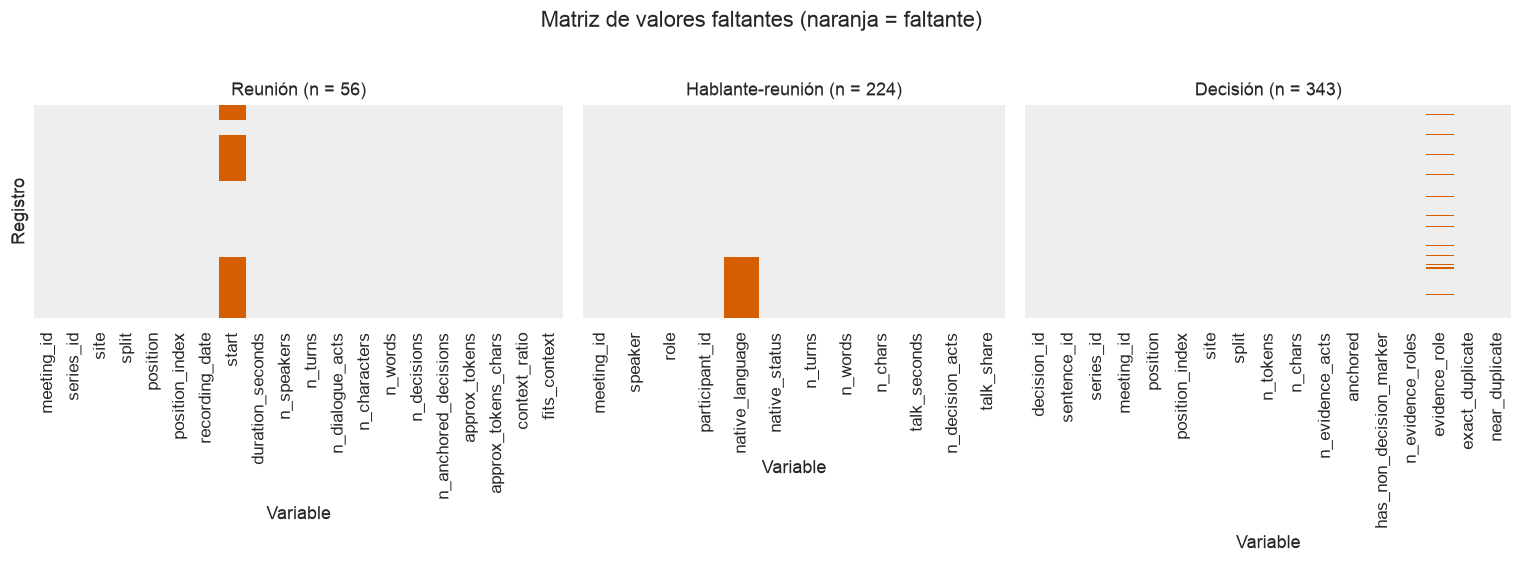

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5), gridspec_kw={"width_ratios": [1.25, 1, 1.15]})
for ax, nombre in zip(axes, ("reunión", "hablante-reunión", "decisión"), strict=False):
    miss = eda.missingness_matrix(LEVELS[nombre])
    sns.heatmap(miss.astype(int), cmap=["#EEEEEE", PAL[3]], cbar=False, yticklabels=False, ax=ax)
    ax.set_title(f"{nombre.capitalize()} (n = {len(miss)})")
    ax.set_xlabel("Variable")
    ax.grid(False)
axes[0].set_ylabel("Registro")
fig.suptitle("Matriz de valores faltantes (naranja = faltante)", y=1.02)
plt.tight_layout()
plt.show()

**Lectura.** Solo **tres variables de las 77** tienen celdas vacías:

| Variable | Nivel | Faltantes | Proporción |
|---|---|---|---|
| `start` (hora de inicio) | reunión | 32 de 56 | 57,1 % |
| `native_language` | hablante-reunión | 64 de 224 | 28,6 % |
| `evidence_role` (decisiones sin evidencia) | decisión | 26 de 343 | 7,6 % |

Ningún registro tiene más de una celda vacía (los valores de `n_missing` son 0 y 1). La matriz muestra dos patrones distintos: **bloques contiguos** para `start` y `native_language` (los registros están ordenados por serie, así que faltan por series completas) y **trazos aislados** para `evidence_role` (decisiones individuales repartidas en todo el nivel). Esa diferencia de forma anticipa la de mecanismo que se prueba en §3.3.

## 3.2 Los cuatro casos reales

Los faltantes del proyecto no están solo en las celdas vacías de las tablas: también hay
**capas ausentes** y **hechos desconocidos**. Se examinan cuatro.

1. La hora de inicio (`startTime`) de la reunión.
2. La lengua nativa del hablante.
3. La capa de segmentación de decisiones (DDS).
4. Las decisiones sin actos de evidencia.

In [11]:
print("1. Hora de inicio ausente, por sitio (True = ausente)")
display(
    eda.contingency_table(
        MEETING.assign(start_missing=MEETING["start"].isna()), "site", "start_missing", margins=True
    )
)

print("\n2. Condición de lengua nativa, por sitio (hablante-reunión)")
display(eda.contingency_table(SPEAKER_CTX, "site", "native_status", margins=True))

print("\n3. Cobertura de capas de anotación sobre las 14 series")
cov = audit.layer_coverage()
display(cov[["layer", "file_count", "oe1_series_complete_count", "oe1_series_incomplete"]])

print("\n4. Decisiones sin evidencia, por sitio y por posición de la reunión")
sin_evidencia = DECISION.assign(no_evidence=~DECISION["anchored"])
display(eda.contingency_table(sin_evidencia, "site", "anchored", margins=True))
display(
    eda.rate_by_bin(
        sin_evidencia, "position_index", "no_evidence", [0, 1, 2, 3, 4], labels=["a", "b", "c", "d"]
    ).rename(columns={"bin": "posición", "n_true": "sin evidencia"})
)
display(
    SERIES_T.sort_values("anchoring_rate")[
        ["series_id", "site", "n_decisions", "anchoring_rate"]
    ].head(5)
)

1. Hora de inicio ausente, por sitio (True = ausente)


start_missing,False,True,All
site,,,
ES,4,16,20
IS,20,0,20
TS,0,16,16
All,24,32,56



2. Condición de lengua nativa, por sitio (hablante-reunión)


native_status,native,non_native,unknown,All
site,,,,
ES,76,4,0,80
IS,20,60,0,80
TS,0,0,64,64
All,96,64,64,224



3. Cobertura de capas de anotación sobre las 14 series


,layer,file_count,oe1_series_complete_count,oe1_series_incomplete
0,abstractive_summary,142,14,
1,extractive_summary_links,137,14,
2,decision_discussion_segmentation,47,6,"ES2002,ES2008,ES2014,IS1003,IS1009,TS3003,TS3009,TS3011"
3,dialogue_acts,556,14,
4,words,687,14,
5,segments,687,14,



4. Decisiones sin evidencia, por sitio y por posición de la reunión


anchored,False,True,All
site,,,
ES,7,130,137
IS,7,92,99
TS,12,95,107
All,26,317,343


,posición,n,sin evidencia,rate
0,a,51,0,0.000000
1,b,107,5,0.046729
2,c,89,10,0.112360
3,d,96,11,0.114583


,series_id,site,n_decisions,anchoring_rate
10,TS3003,TS,31,0.774194
6,IS1004,IS,24,0.833333
2,ES2014,ES,23,0.869565
13,TS3011,TS,23,0.913043
0,ES2002,ES,28,0.928571


## 3.3 ¿Qué mecanismo hay detrás?

Para cada faltante se contrasta si el indicador "falta" se asocia con variables observadas
(`missingness_mechanism`): prueba U de Mann-Whitney con correlación biserial por rangos para las
numéricas, y chi-cuadrado (o Fisher en 2×2 pequeño) con V de Cramér para las categóricas. Que
una asociación exista **descarta MCAR**; que no exista no lo prueba. Con muchas covariables hay
muchas pruebas, así que `associated` es un tamizaje, no una conclusión corregida.

In [12]:
tests = {
    "hora de inicio ausente (reunión)": eda.missingness_mechanism(
        MEETING["start"].isna(),
        MEETING[["site", "position_index", "duration_seconds", "n_words", "n_decisions", "split"]],
    ),
    "decisión sin evidencia (decisión)": eda.missingness_mechanism(
        ~DECISION["anchored"],
        DECISION[
            [
                "site",
                "position_index",
                "n_tokens",
                "split",
                "has_non_decision_marker",
                "exact_duplicate",
            ]
        ],
    ),
    "lengua nativa desconocida (hablante-reunión)": eda.missingness_mechanism(
        SPEAKER_CTX["native_language"].isna(),
        SPEAKER_CTX[["site", "role", "position_index", "n_words", "talk_share"]],
    ),
}
for nombre, tabla in tests.items():
    print(f"\n>>> {nombre}")
    display(tabla)


>>> hora de inicio ausente (reunión)


,covariate,test,statistic,p_value,effect_name,effect_size,n,associated
0,site,chi2,42.933333,4.754941e-10,cramers_v,0.875595,56,True
1,position_index,mann_whitney,384.000000,1.000000e+00,rank_biserial,0.000000,56,False
2,duration_seconds,mann_whitney,563.500000,3.039225e-03,rank_biserial,0.467448,56,True
3,n_words,mann_whitney,498.000000,6.021988e-02,rank_biserial,0.296875,56,False
4,n_decisions,mann_whitney,458.500000,2.174435e-01,rank_biserial,0.194010,56,False
5,split,chi2,0.565657,4.519901e-01,cramers_v,0.100504,56,False



>>> decisión sin evidencia (decisión)


,covariate,test,statistic,p_value,effect_name,effect_size,n,associated
0,site,chi2,3.248303,0.197079,cramers_v,0.097315,343,False
1,position_index,mann_whitney,5454.500000,0.004395,rank_biserial,0.323587,343,True
2,n_tokens,mann_whitney,4145.500000,0.960205,rank_biserial,0.005945,343,False
3,split,chi2,0.006372,0.936377,cramers_v,0.004310,343,False
4,has_non_decision_marker,fisher,NaN,1.000000,cramers_v,0.005418,343,False
5,exact_duplicate,fisher,NaN,1.000000,cramers_v,0.031109,343,False



>>> lengua nativa desconocida (hablante-reunión)


,covariate,test,statistic,p_value,effect_name,effect_size,n,associated
0,site,chi2,224.0,2.285694e-49,cramers_v,1.000000,224,True
1,role,chi2,0.0,1.000000e+00,cramers_v,0.000000,224,False
2,position_index,mann_whitney,5120.0,1.000000e+00,rank_biserial,0.000000,224,False
3,n_words,mann_whitney,5932.0,6.402721e-02,rank_biserial,0.158594,224,False
4,talk_share,mann_whitney,4932.0,6.687179e-01,rank_biserial,-0.036719,224,False


**Lectura.**

1. **Hora de inicio (32 de 56): depende del sitio. No es MCAR.** Las 20 reuniones de IS tienen hora, ninguna de las 16 de TS la tiene y ES la pierde en 16 de 20. Asociación con el sitio: V de Cramér 0,876 (p = 5e-10). También se asocia con la duración (U de Mann-Whitney p = 0,003, correlación biserial 0,47), pero esa relación es compatible con que ES y TS tengan reuniones más largas (§6.3), por lo que no puede separarse del sitio. Sin asociación con la posición (p = 1,0), las palabras (p = 0,060), las decisiones (p = 0,217) ni la partición (p = 0,45). **Mecanismo: MAR respecto del sitio**; en la práctica es una laguna estructural del archivo `meetings.xml`.
2. **Lengua nativa desconocida (64 de 224): determinista por sitio.** Faltan los 64 hablantes-reunión de TS y ninguno de ES o IS (V = 1,0). No se asocia con el rol (p = 1,0), la posición (p = 1,0), las palabras (p = 0,064) ni la proporción de habla (p = 0,67). **Mecanismo: estructural** (el archivo de participantes no incluye a TS). Es el hallazgo de la decisión D7: la lengua no puede estudiarse como eje independiente.
3. **Capa DDS ausente o incompleta (8 de las 14 series).** Solo ES2015, ES2016, IS1004, IS1006, IS1008 y TS3005 la tienen completa. Es una decisión de cobertura de AMI, no un faltante aleatorio, y por eso DDS se usa solo como subconjunto de validación (D2).
4. **Decisión sin evidencia (26 de 343): no es MCAR, y la señal depende de la posición.** No se asocia con el sitio (V = 0,097, p = 0,197), la longitud de la frase (p = 0,96), la partición (p = 0,94), la marca de "no decisión" (p = 1,0) ni el duplicado (p = 1,0). **Sí se asocia con la posición de la reunión** (p = 0,004, biserial 0,32): faltan 0 de 51 en la reunión a, 5 de 107 en la b (4,7 %), 10 de 89 en la c (11,2 %) y 11 de 96 en la d (11,5 %). Por series, TS3003 es la de menor anclaje (77,4 %), seguida de IS1004 (83,3 %). **Mecanismo: MAR respecto de la posición** como mínimo.

**La discusión MNAR (argumentada, no demostrable).** Una pregunta que los datos no pueden contestar es si la evidencia falta *por una razón ligada a lo que falta*. Hay motivo para sospecharlo: el único error de origen conocido (el botón turbo, notebook 00 §3.4) es una decisión cuya evidencia es cero. Si las frases del resumen sin acto de diálogo asociado son sobre todo afirmaciones que nadie pudo enlazar a lo dicho, entonces la ausencia depende de una propiedad no observada (si la frase está respaldada por el diálogo), que es la definición de MNAR. Con un solo caso verificado esto es una **hipótesis**, no un resultado: no se sabe qué fracción de las 26 es error y qué fracción es una síntesis legítima sin acto único. Se resolverá al adjudicar. Por eso la evidencia nula se trata como señal de revisión y no como un dato corriente.

**Balance sobre HE5.** Se sostiene en lo esencial: los tres faltantes de tabla son estructurales o dependen de variables observadas (ninguno es MCAR) y ninguno toca las etiquetas de referencia. La excepción, la evidencia nula, es la que merece atención.

## 3.4 Por qué no se imputa

Imputar es reemplazar un faltante por un valor estimado. Aquí **no se imputa nada**, por tres
razones:

1. **Las etiquetas de referencia las pone un humano** (decisión D3). Estimar una etiqueta con un
   modelo introduciría exactamente el error que C3 debe estar libre de tener.
2. **Imputar la evidencia fabricaría proveniencia.** Una decisión "sin actos de evidencia" es una
   afirmación del resumen que ningún anotador de AMI pudo enlazar a una frase dicha; asignarle
   evidencia estimada la presentaría como respaldada cuando no lo está.
3. **Los demás faltantes son metadatos que ningún análisis de este proyecto usa como variable
   de resultado** (hora de inicio) o que solo se reportan como limitación (lengua nativa, D7).

Lo que sí se hace es **conservar el faltante como categoría**: `describe_categorical` lo muestra
como `<missing>` y las pruebas de grupo lo excluyen de forma explícita.

---

# 4. Análisis univariado

Cada variable se mira por separado: ubicación (media, mediana, moda), dispersión (varianza,
desviación estándar, rango intercuartílico, IQR; coeficiente de variación, CV = desviación /
media) y forma (asimetría y curtosis). La **asimetría** mide hacia qué lado se alarga la cola
(0 = simétrica, positiva = cola derecha). La **curtosis en exceso** mide el peso de las colas
respecto de la normal (0 = como la normal).

## 4.1 Reuniones (n = 56)

In [13]:
MEETING_VARS = [
    "duration_seconds",
    "n_turns",
    "n_dialogue_acts",
    "n_words",
    "n_decisions",
    "n_anchored_decisions",
    "approx_tokens",
    "context_ratio",
]
display(eda.describe_numeric(MEETING, MEETING_VARS).round(3))
print("Forma tras log(1 + x), para juzgar si la escala logarítmica mejora la simetría:")
display(
    eda.describe_numeric(
        MEETING, ["duration_seconds", "n_turns", "n_words", "n_decisions"], log=True
    )[["variable", "transform", "skewness", "excess_kurtosis"]].round(3)
)

,variable,transform,n,mean,median,mode,variance,std,min,q1,q3,iqr,max,skewness,excess_kurtosis,cv
0,duration_seconds,none,56,1917.385,2072.000,2101.000,300728.947,548.388,791.000,1508.161,2310.75,802.589,2911.000,-0.491,-0.645,0.286
1,n_turns,none,56,461.732,448.500,243.000,46180.636,214.897,96.000,290.000,563.50,273.500,1194.000,0.742,0.956,0.465
2,n_dialogue_acts,none,56,821.786,848.500,1230.000,132258.753,363.674,198.000,541.000,1020.50,479.500,2179.000,0.828,2.044,0.443
3,n_words,none,56,5010.179,4997.500,1491.000,3526553.604,1877.912,1491.000,3702.750,6335.75,2633.000,9112.000,-0.105,-0.749,0.375
4,n_decisions,none,56,6.125,6.000,6.000,9.857,3.140,1.000,3.000,8.00,5.000,15.000,0.399,-0.156,0.513
5,n_anchored_decisions,none,56,5.661,6.000,2.000,8.374,2.894,1.000,3.000,7.25,4.250,14.000,0.482,0.037,0.511
6,approx_tokens,none,56,6513.661,6497.500,1939.000,5959441.610,2441.197,1939.000,4813.750,8236.50,3422.750,11846.000,-0.105,-0.748,0.375
7,context_ratio,none,56,0.530,0.529,0.158,0.039,0.199,0.158,0.392,0.67,0.279,0.964,-0.105,-0.748,0.375


Forma tras log(1 + x), para juzgar si la escala logarítmica mejora la simetría:


,variable,transform,skewness,excess_kurtosis
0,duration_seconds,log1p,-1.031,0.210
1,n_turns,log1p,-0.534,0.077
2,n_words,log1p,-0.872,0.001
3,n_decisions,log1p,-0.539,-0.447


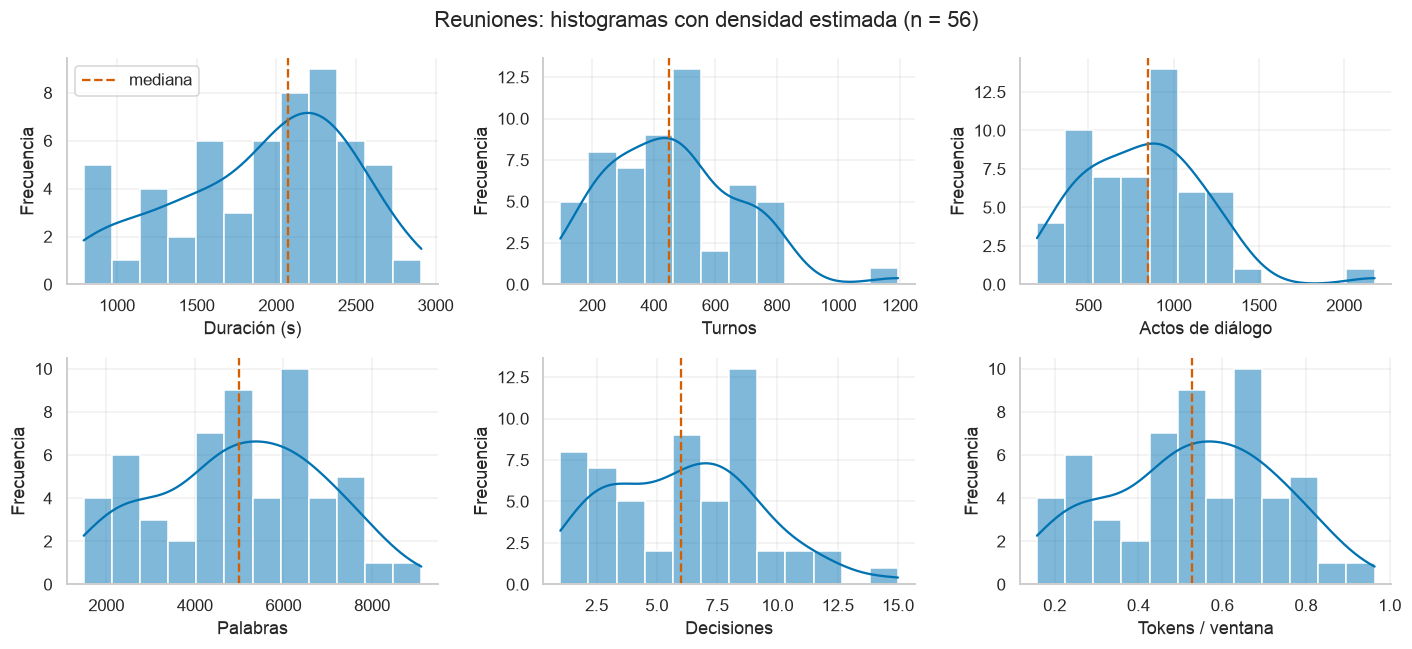

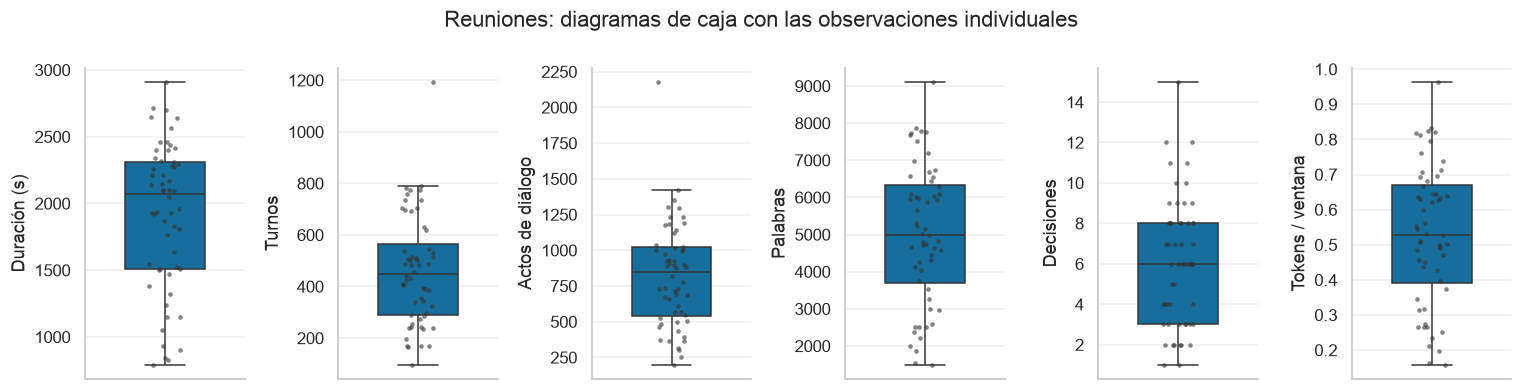

In [14]:
PLOT_VARS = [
    "duration_seconds",
    "n_turns",
    "n_dialogue_acts",
    "n_words",
    "n_decisions",
    "context_ratio",
]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, col in zip(axes.flat, PLOT_VARS, strict=False):
    sns.histplot(MEETING[col], kde=True, bins=12, color=PAL[0], edgecolor="white", ax=ax)
    ax.axvline(MEETING[col].median(), color=PAL[3], ls="--", lw=1.5, label="mediana")
    ax.set_xlabel(LABEL[col])
    ax.set_ylabel("Frecuencia")
axes[0, 0].legend()
fig.suptitle("Reuniones: histogramas con densidad estimada (n = 56)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 6, figsize=(14, 3.6))
for ax, col in zip(axes, PLOT_VARS, strict=False):
    sns.boxplot(y=MEETING[col], color=PAL[0], width=0.5, fliersize=0, ax=ax)
    sns.stripplot(y=MEETING[col], color="0.2", size=3, alpha=0.6, ax=ax)
    ax.set_ylabel(LABEL[col])
fig.suptitle("Reuniones: diagramas de caja con las observaciones individuales")
plt.tight_layout()
plt.show()

**Lectura (reuniones, n = 56).**

- **Duración:** media 1.917 s (unos 32 minutos), mediana 2.072 s, rango de 791 a 2.911 s, CV 0,29. La asimetría es **negativa** (−0,49): la cola larga está a la izquierda, formada por las reuniones cortas. El histograma muestra una cola izquierda de reuniones cortas (alrededor de 800 a 1.200 s).
- **Turnos:** media 461,7, mediana 448,5, rango de 96 a 1.194, asimetría 0,74 y curtosis 0,96. La cola derecha es una sola reunión (TS3005d, 1.194 turnos).
- **Palabras:** media 5.010, mediana 4.998, desviación 1.878; casi simétrica (−0,10) y más plana que la normal (curtosis −0,75). Los tokens estimados y la razón con la ventana son la misma variable reescalada (por eso comparten asimetría y curtosis).
- **Decisiones por reunión:** media 6,13, mediana y moda 6, rango de 1 a 15. Es la variable con mayor dispersión relativa (CV 0,51): reuniones de tamaño parecido registran números muy distintos de decisiones. Con evidencia: media 5,66.

**Qué implica.** Las variables de tamaño (duración, turnos, palabras, actos) comparten forma y se leerán como una sola dimensión en §7 y §8. Ninguna es tan asimétrica como para exigir transformación; no se usa escala logarítmica en el nivel de reunión (con log(1 + x) la asimetría de las palabras pasa de −0,10 a −0,87 y la de la duración de −0,49 a −1,03, es decir, empeora; en los turnos la asimetría pasa de 0,74 a −0,53, un cambio de signo sin ganancia clara).

## 4.2 Decisiones (n = 343)

El conteo de actos de evidencia y la longitud de las frases son **conteos con cola derecha**. Para
ellos se explora además la escala logarítmica (`log1p`, es decir log(1 + x), definida en cero).

,variable,transform,n,mean,median,mode,variance,std,min,q1,q3,iqr,max,skewness,excess_kurtosis,cv
0,n_tokens,none,343,6.134,5.0,3.0,14.935,3.865,1.0,3.0,8.0,5.0,25.0,1.759,3.774,0.630
1,n_chars,none,343,66.443,52.0,46.0,1717.031,41.437,16.0,39.0,79.0,40.0,290.0,2.022,5.051,0.624
2,n_evidence_acts,none,343,1.997,2.0,1.0,2.956,1.719,0.0,1.0,2.0,1.0,17.0,3.032,17.982,0.861


Misma tabla tras log(1 + x):


,variable,transform,n,mean,median,mode,variance,std,min,q1,q3,iqr,max,skewness,excess_kurtosis,cv
0,n_tokens,log1p,343,1.848,1.792,1.386,0.219,0.468,0.693,1.386,2.197,0.811,3.258,0.538,-0.210,0.253
1,n_chars,log1p,343,4.070,3.970,3.850,0.257,0.507,2.833,3.689,4.382,0.693,5.673,0.651,-0.028,0.125
2,n_evidence_acts,log1p,343,0.977,1.099,0.693,0.229,0.478,0.000,0.693,1.099,0.405,2.890,0.287,0.754,0.490


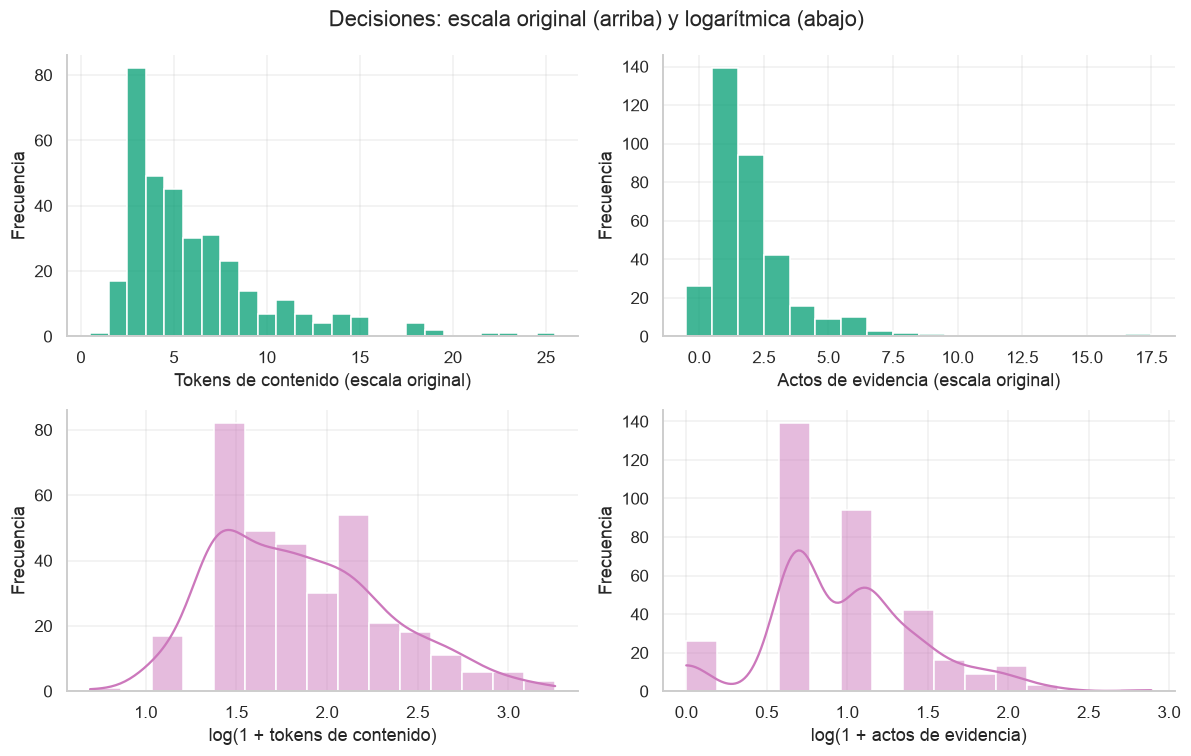

In [15]:
DEC_VARS = ["n_tokens", "n_chars", "n_evidence_acts"]
display(eda.describe_numeric(DECISION, DEC_VARS).round(3))
print("Misma tabla tras log(1 + x):")
display(eda.describe_numeric(DECISION, DEC_VARS, log=True).round(3))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col_idx, col in enumerate(["n_tokens", "n_evidence_acts"]):
    sns.histplot(DECISION[col], discrete=True, color=PAL[2], edgecolor="white", ax=axes[0, col_idx])
    axes[0, col_idx].set_xlabel(LABEL[col] + " (escala original)")
    sns.histplot(
        np.log1p(DECISION[col]),
        kde=True,
        bins=15,
        color=PAL[4],
        edgecolor="white",
        ax=axes[1, col_idx],
    )
    axes[1, col_idx].set_xlabel("log(1 + " + LABEL[col].lower() + ")")
for ax in axes.flat:
    ax.set_ylabel("Frecuencia")
fig.suptitle("Decisiones: escala original (arriba) y logarítmica (abajo)")
plt.tight_layout()
plt.show()

**Lectura (decisiones, n = 343).**

- **Longitud:** media 6,13 tokens de contenido, mediana 5, moda 3, rango de 1 a 25. Asimetría 1,76 y curtosis 3,77: muchas frases cortas y una cola de frases largas. Son **frases telegráficas**: la mitad tiene 5 tokens o menos.
- **Actos de evidencia:** media 2,0, mediana 2, moda 1, máximo 17. Asimetría 3,03 y curtosis 17,98, la más extrema de todas las variables: casi todas las decisiones tienen 1 o 2 actos y unas pocas tienen decenas. Hay 26 decisiones con 0 actos (§3).
- **Escala logarítmica.** Con log(1 + x) la asimetría baja de 1,76 a 0,54 en la longitud, de 2,02 a 0,65 en los caracteres y de 3,03 a 0,29 en los actos, y la curtosis de los actos pasa de 17,98 a 0,75. La escala logarítmica **sí** conviene para estos conteos con cola derecha; el histograma de actos sigue mostrando la barra aislada del cero, que es un efecto de la discretización y de los 26 casos sin evidencia.

**Qué implica.** Para pruebas que suponen simetría (Pearson, IQR de Tukey) estas variables requieren cuidado; por eso §7 compara tres coeficientes y §5 advierte sobre el criterio IQR.

## 4.3 Pares (n = 3.071) y hablante-reunión (n = 224)

Pares


,variable,transform,n,mean,median,mode,variance,std,min,q1,q3,iqr,max,skewness,excess_kurtosis,cv
0,overlap,none,3071,0.122,0.0,0.0,0.029,0.172,0.0,0.0,0.25,0.25,1.0,1.246,1.295,1.403
1,shared_tokens,none,3071,0.454,0.0,0.0,0.410,0.640,0.0,0.0,1.00,1.00,6.0,1.708,5.425,1.409
2,n_tokens_earlier,none,3071,5.799,5.0,3.0,12.688,3.562,1.0,3.0,7.00,4.00,23.0,1.849,3.919,0.614
3,n_tokens_later,none,3071,5.880,4.0,3.0,13.971,3.738,1.0,3.0,8.00,5.00,25.0,1.775,4.068,0.636
4,meeting_distance,none,3071,1.567,1.0,1.0,0.468,0.684,1.0,1.0,2.00,1.00,3.0,0.800,-0.546,0.437


Hablante-reunión


,variable,transform,n,mean,median,mode,variance,std,min,q1,q3,iqr,max,skewness,excess_kurtosis,cv
0,n_turns,none,224,115.433,105.500,63.000,4196.363,64.779,8.000,67.000,155.00,88.000,394.000,0.892,1.124,0.561
1,n_words,none,224,1252.545,1178.000,249.000,455772.581,675.109,60.000,735.250,1783.75,1048.500,2989.000,0.322,-0.704,0.539
2,talk_seconds,none,224,474.697,450.815,26.588,59649.017,244.231,26.588,283.162,643.86,360.699,1256.975,0.279,-0.524,0.515
3,talk_share,none,224,0.250,0.242,0.023,0.013,0.113,0.023,0.166,0.31,0.144,0.794,0.949,2.131,0.452
4,n_decision_acts,none,224,3.058,2.000,0.000,11.328,3.366,0.000,0.000,5.00,5.000,18.000,1.512,2.867,1.101


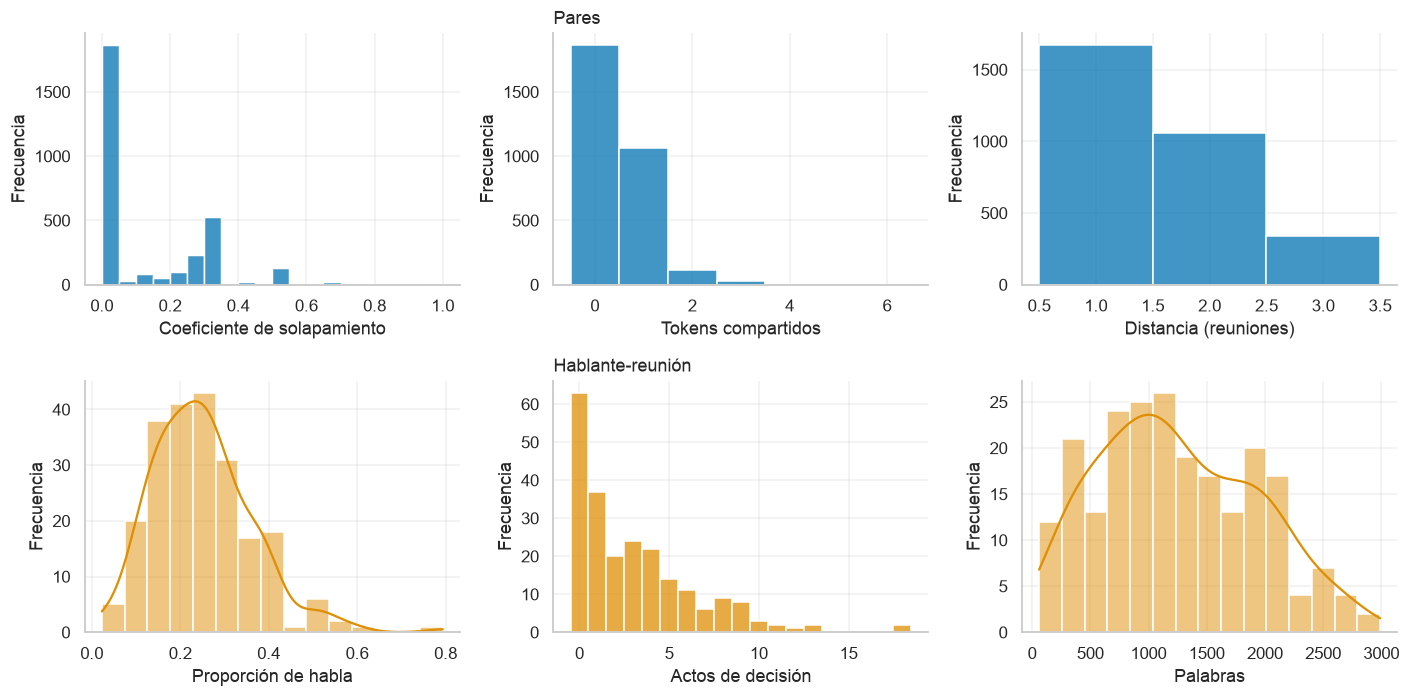

In [16]:
PAIR_VARS = ["overlap", "shared_tokens", "n_tokens_earlier", "n_tokens_later", "meeting_distance"]
SPK_VARS = ["n_turns", "n_words", "talk_seconds", "talk_share", "n_decision_acts"]
print("Pares")
display(eda.describe_numeric(PAIR, PAIR_VARS).round(3))
print("Hablante-reunión")
display(eda.describe_numeric(SPEAKER, SPK_VARS).round(3))

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
sns.histplot(PAIR["overlap"], bins=20, color=PAL[0], edgecolor="white", ax=axes[0, 0])
axes[0, 0].set_xlabel(LABEL["overlap"])
sns.histplot(PAIR["shared_tokens"], discrete=True, color=PAL[0], edgecolor="white", ax=axes[0, 1])
axes[0, 1].set_xlabel(LABEL["shared_tokens"])
sns.histplot(
    PAIR["meeting_distance"], discrete=True, color=PAL[0], edgecolor="white", ax=axes[0, 2]
)
axes[0, 2].set_xlabel(LABEL["meeting_distance"])
sns.histplot(
    SPEAKER["talk_share"], bins=15, kde=True, color=PAL[1], edgecolor="white", ax=axes[1, 0]
)
axes[1, 0].set_xlabel(LABEL["talk_share"])
sns.histplot(
    SPEAKER["n_decision_acts"], discrete=True, color=PAL[1], edgecolor="white", ax=axes[1, 1]
)
axes[1, 1].set_xlabel(LABEL["n_decision_acts"])
sns.histplot(SPEAKER["n_words"], bins=15, kde=True, color=PAL[1], edgecolor="white", ax=axes[1, 2])
axes[1, 2].set_xlabel(LABEL["n_words"])
for ax in axes.flat:
    ax.set_ylabel("Frecuencia")
axes[0, 1].set_title("Pares", loc="left")
axes[1, 1].set_title("Hablante-reunión", loc="left")
plt.tight_layout()
plt.show()

**Lectura.**

- **Pares (n = 3.071).** El coeficiente de solapamiento tiene mediana 0 y tercer cuartil 0,25: **al menos la mitad de los pares no comparte ningún token** y menos de la cuarta parte llega al umbral de 0,30. Media 0,122, máximo 1,0, asimetría 1,25. Los tokens compartidos van de 0 a 6 (media 0,45, asimetría 1,71, curtosis 5,43). La moda de la longitud de las decisiones del par es 3 tokens en ambos lados, un dato que reaparece en §10.3. La distancia media es 1,57 reuniones (§10.2 detalla su reparto).
- **Hablante-reunión (n = 224).** Palabras: media 1.253, mediana 1.178, desviación 675. La proporción de habla tiene media exactamente 0,25 (cuatro hablantes por reunión), mediana 0,242, y llega a 0,794. **Los actos de decisión están muy desigualmente repartidos:** media 3,06, mediana 2, moda 0, máximo 18, CV 1,10 (el mayor de todas las variables de hablante). Muchos hablantes no aportan ningún acto a las decisiones de su reunión y unos pocos aportan 18.

**Qué implica.** La concentración de la autoría de decisiones en pocas personas motiva P7: ¿es un efecto del rol o del volumen de habla? Se responde en §7.4 y §10.5.

## 4.4 Variables categóricas

Barras de frecuencia para sitio, rol, rol que respalda la decisión, condición de lengua,
marca de candidato y marca de "no decisión" (una pista léxica de que la frase no es una decisión
real, cuya precisión no se ha medido).

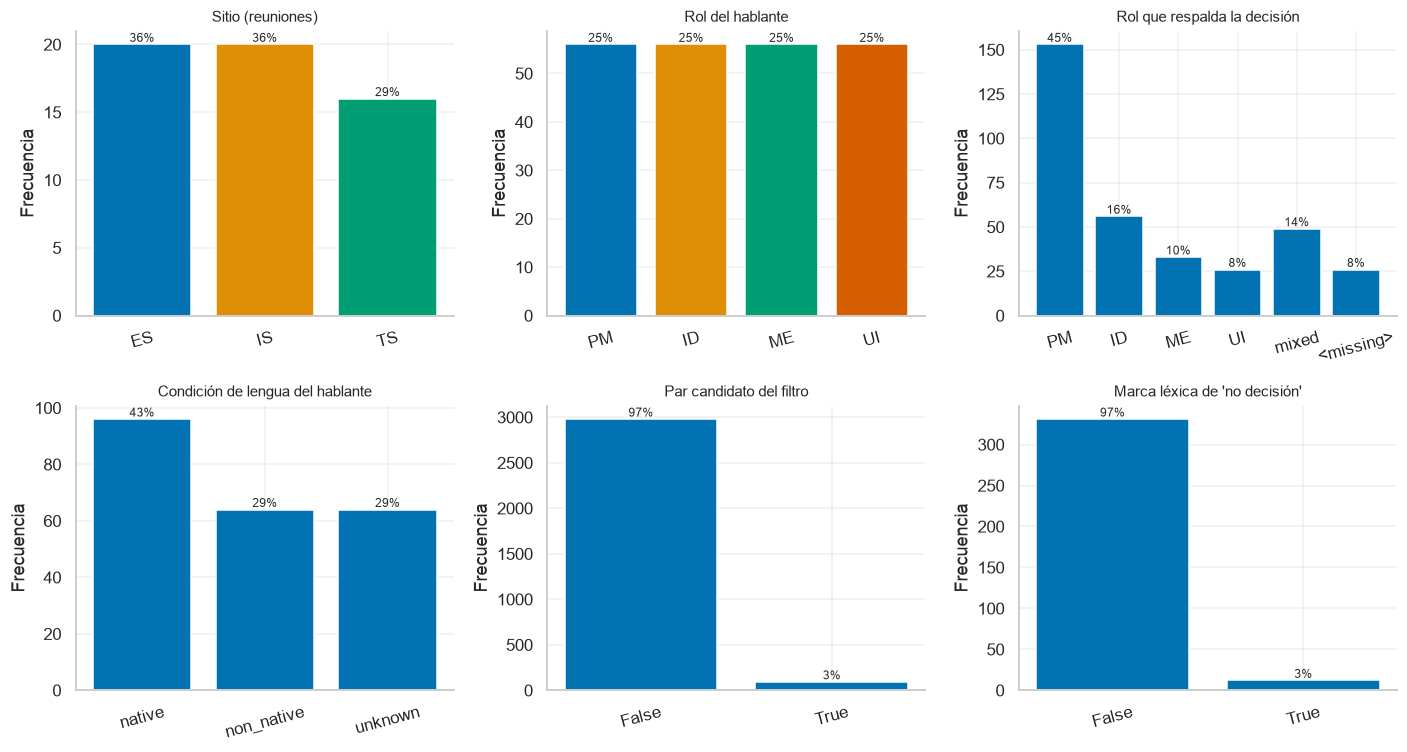

In [17]:
def bar_counts(ax, df, var, title, order=None, colors=None):
    """Bar chart of the counts that describe_categorical returns for one variable."""
    freq = eda.describe_categorical(df, [var]).set_index("category")
    if order is not None:
        freq = freq.reindex(order)
    bars = ax.bar(freq.index.astype(str), freq["count"], color=colors or PAL[0])
    for bar, share in zip(bars, freq["share"], strict=False):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{share:.0%}",
            ha="center",
            va="bottom",
            fontsize=8,
        )
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("Frecuencia")
    ax.tick_params(axis="x", labelrotation=15)


fig, axes = plt.subplots(2, 3, figsize=(13, 7))
bar_counts(
    axes[0, 0],
    MEETING,
    "site",
    "Sitio (reuniones)",
    ["ES", "IS", "TS"],
    [SITE_COLOR[s] for s in ["ES", "IS", "TS"]],
)
bar_counts(
    axes[0, 1],
    SPEAKER,
    "role",
    "Rol del hablante",
    ["PM", "ID", "ME", "UI"],
    [ROLE_COLOR[r] for r in ["PM", "ID", "ME", "UI"]],
)
bar_counts(
    axes[0, 2],
    DECISION,
    "evidence_role",
    "Rol que respalda la decisión",
    ["PM", "ID", "ME", "UI", "mixed", "<missing>"],
)
bar_counts(
    axes[1, 0],
    SPEAKER,
    "native_status",
    "Condición de lengua del hablante",
    ["native", "non_native", "unknown"],
)
bar_counts(axes[1, 1], PAIR, "is_candidate", "Par candidato del filtro", [False, True])
bar_counts(
    axes[1, 2], DECISION, "has_non_decision_marker", "Marca léxica de 'no decisión'", [False, True]
)
plt.tight_layout()
plt.show()

**Lectura.**

- **Sitio:** 20 reuniones de ES (35,7 %), 20 de IS (35,7 %) y 16 de TS (28,6 %). **Rol:** 56 hablantes de cada uno de los cuatro roles, exactamente 25 % cada uno (el diseño del escenario lo garantiza).
- **Rol que respalda la decisión:** PM 153 decisiones (44,6 %), ID 56 (16,3 %), mixto 49 (14,3 %), ME 33 (9,6 %), UI 26 (7,6 %) y sin evidencia 26 (7,6 %). Con roles balanceados, el PM tiene casi el doble de lo que correspondería a un reparto parejo.
- **Lengua del hablante:** nativo 96 (42,9 %), no nativo 64 (28,6 %) y desconocido 64 (28,6 %); el 28,6 % de desconocidos es el bloque completo de TS.
- **Par candidato:** 92 de 3.071 (3,0 %). **Marca léxica de "no decisión":** 12 de 343 (3,5 %); es un indicio cuya precisión no se midió, así que no se usa para excluir decisiones.

---

# 5. Valores atípicos

Un valor atípico (*outlier*) es una observación que se aleja del resto. No es sinónimo de error:
puede ser un **error de captura** (hay que corregirlo o excluirlo) o un **fenómeno real**
(hay que conservarlo y entenderlo). Esa distinción es un juicio que se registra, no algo que un
método decida. Se usan cuatro métodos:

| Método | Tipo | Regla |
|---|---|---|
| **Z-score** | univariado | \|z\| > 3 (desviaciones estándar respecto de la media) |
| **IQR** (Tukey) | univariado | fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR] |
| **LOF** (*Local Outlier Factor*) | multivariado | el 5 % de filas más aisladas respecto de sus vecinos |
| **MCD** (*Minimum Covariance Determinant*) | multivariado | distancia de Mahalanobis robusta sobre el cuantil 0,975 de χ² |

Los dos multivariados operan sobre variables estandarizadas (media 0, desviación 1).

## 5.1 Univariados por variable y nivel

In [18]:
UNI = {
    "reunión": (
        MEETING,
        [
            "duration_seconds",
            "n_turns",
            "n_dialogue_acts",
            "n_words",
            "n_decisions",
            "n_anchored_decisions",
        ],
    ),
    "decisión": (DECISION, ["n_tokens", "n_chars", "n_evidence_acts"]),
    "par": (PAIR, ["overlap", "shared_tokens", "n_tokens_earlier", "n_tokens_later"]),
    "hablante-reunión": (SPEAKER, ["n_turns", "n_words", "talk_seconds", "n_decision_acts"]),
}
rows = []
for nivel, (tabla, cols) in UNI.items():
    z, iqr = eda.zscore_outliers(tabla, cols), eda.iqr_outliers(tabla, cols)
    for col in cols:
        rows.append(
            {
                "nivel": nivel,
                "variable": col,
                "n": len(tabla),
                "Z (|z| > 3)": int(z[col].sum()),
                "IQR (1,5)": int(iqr[col].sum()),
            }
        )
display(pd.DataFrame(rows))

,nivel,variable,n,Z (|z| > 3),"IQR (1,5)"
0,reunión,duration_seconds,56,0,0
1,reunión,n_turns,56,1,1
2,reunión,n_dialogue_acts,56,1,1
3,reunión,n_words,56,0,0
4,reunión,n_decisions,56,0,0
5,reunión,n_anchored_decisions,56,0,1
6,decisión,n_tokens,343,9,9
7,decisión,n_chars,343,8,23
8,decisión,n_evidence_acts,343,4,42
9,par,overlap,3071,30,30


## 5.2 Multivariados en reuniones: LOF y MCD

Las reuniones se describen por cuatro variables de tamaño: duración, palabras, turnos y decisiones.
Se excluyen los actos de diálogo, los caracteres y las decisiones con evidencia porque son
casi redundantes con las anteriores (su colinealidad se mide en §7.3) y distorsionan la distancia
de Mahalanobis. Para no ocultar esa decisión, se compara cuántas filas marca cada método con tres
conjuntos de variables.

In [19]:
OUT_VARS = ["duration_seconds", "n_words", "n_turns", "n_decisions"]
ALT_SETS = {
    "6 variables (con redundantes)": [
        "duration_seconds",
        "n_words",
        "n_turns",
        "n_dialogue_acts",
        "n_decisions",
        "n_anchored_decisions",
    ],
    "4 variables (adoptado)": OUT_VARS,
    "3 variables (sin duración)": ["n_words", "n_turns", "n_decisions"],
}
sensibilidad = pd.DataFrame(
    {
        nombre: eda.outlier_summary(MEETING, cols)[
            ["z_flag", "iqr_flag", "lof_flag", "mcd_flag"]
        ].sum()
        for nombre, cols in ALT_SETS.items()
    }
).T.astype(int)
sensibilidad.columns = ["Z", "IQR", "LOF", "MCD"]
display(sensibilidad)

,Z,IQR,LOF,MCD
6 variables (con redundantes),1,2,3,16
4 variables (adoptado),1,1,3,13
3 variables (sin duración),1,1,3,5


Reuniones marcadas por al menos un método: 15 de 56


,meeting_id,duration_seconds,n_words,n_turns,n_decisions,z_flag,iqr_flag,lof_flag,mcd_flag,n_methods,lof_score,mahalanobis_sq
47,TS3005d,2718.000,9112,1194,6,True,True,True,True,4,-1.77,93.03
42,TS3003c,2566.840,4589,385,6,False,False,False,True,1,-0.96,58.76
17,ES2016b,2412.000,4981,354,12,False,False,False,True,1,-1.13,50.17
51,TS3009d,2101.000,6739,773,3,False,False,False,True,1,-1.11,39.04
43,TS3003d,2645.000,5310,705,8,False,False,False,True,1,-1.02,30.79
31,IS1006d,1830.000,4806,734,2,False,False,False,True,1,-1.15,29.85
18,ES2016c,2308.000,4758,297,3,False,False,False,True,1,-1.00,27.11
41,TS3003b,2210.305,4836,404,11,False,False,False,True,1,-1.02,24.00
23,IS1003d,2093.000,6020,784,7,False,False,False,True,1,-1.02,19.03
15,ES2015d,1931.000,5650,706,7,False,False,False,True,1,-0.99,15.68


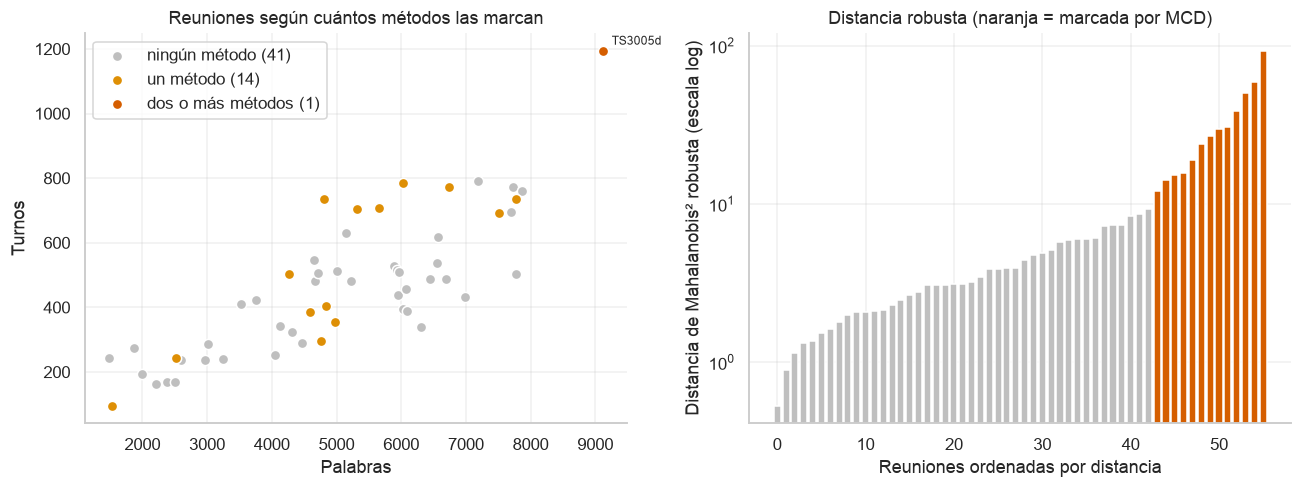

In [20]:
summ = eda.outlier_summary(MEETING, OUT_VARS)
scores = eda.multivariate_outliers(MEETING, OUT_VARS)[["lof_score", "mahalanobis_sq"]]
flag_cols = ["z_flag", "iqr_flag", "lof_flag", "mcd_flag", "n_methods"]

flagged = (
    MEETING[["meeting_id", *OUT_VARS]]
    .join(summ.set_index("row")[flag_cols])
    .join(scores.round(2))
    .loc[lambda d: d["n_methods"] > 0]
    .sort_values(["n_methods", "mahalanobis_sq"], ascending=False)
)
print(f"Reuniones marcadas por al menos un método: {len(flagged)} de {len(MEETING)}")
display(flagged)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
nivel = summ.set_index("row")["n_methods"].reindex(MEETING.index)
for valor, color, etiqueta in [
    (0, "0.75", "ningún método"),
    (1, PAL[1], "un método"),
    (2, PAL[3], "dos o más métodos"),
]:
    mask = (nivel == valor) if valor < 2 else (nivel >= 2)
    axes[0].scatter(
        MEETING.loc[mask, "n_words"],
        MEETING.loc[mask, "n_turns"],
        s=45,
        color=color,
        edgecolor="white",
        label=f"{etiqueta} ({int(mask.sum())})",
    )
for _, fila in flagged[flagged["n_methods"] >= 2].iterrows():
    axes[0].annotate(
        fila["meeting_id"],
        (fila["n_words"], fila["n_turns"]),
        textcoords="offset points",
        xytext=(6, 4),
        fontsize=8,
    )
axes[0].set_xlabel(LABEL["n_words"])
axes[0].set_ylabel(LABEL["n_turns"])
axes[0].set_title("Reuniones según cuántos métodos las marcan")
axes[0].legend()

orden = scores["mahalanobis_sq"].sort_values()
colores = [PAL[3] if summ.set_index("row").loc[i, "mcd_flag"] else "0.75" for i in orden.index]
axes[1].bar(range(len(orden)), orden.values, color=colores)
axes[1].set_yscale("log")
axes[1].set_xlabel("Reuniones ordenadas por distancia")
axes[1].set_ylabel("Distancia de Mahalanobis² robusta (escala log)")
axes[1].set_title("Distancia robusta (naranja = marcada por MCD)")
plt.tight_layout()
plt.show()

## 5.3 ¿Error de captura o fenómeno real?

Para distinguir se usa un chequeo que no depende de las variables que marcaron el caso: la
**duración registrada** de la reunión (archivo `meetings.xml`) debe coincidir con el **fin del
último turno transcrito**. Son dos fuentes distintas que miden lo mismo; una brecha grande
delataría un error de captura.

In [21]:
coh = eda.duration_coherence(MEETING, TURNS)
display(
    eda.describe_numeric(
        coh, ["duration_seconds", "transcript_end_seconds", "gap_seconds", "gap_share"]
    ).round(3)
)
print("Reuniones marcadas por algún método")
display(coh[coh["meeting_id"].isin(flagged["meeting_id"])].round(3).reset_index(drop=True))
print(
    f"Reuniones con una brecha de más de 10 % de la duración (en valor absoluto): "
    f"{int((coh['gap_share'].abs() > 0.10).sum())} de {len(coh)}"
)
print("Las cinco brechas absolutas más grandes del corpus")
display(
    coh.reindex(coh["gap_seconds"].abs().sort_values(ascending=False).index)
    .head(5)
    .round(3)
    .reset_index(drop=True)
)

,variable,transform,n,mean,median,mode,variance,std,min,q1,q3,iqr,max,skewness,excess_kurtosis,cv
0,duration_seconds,none,56,1917.385,2072.000,2101.000,300728.947,548.388,791.000,1508.161,2310.750,802.589,2911.000,-0.491,-0.645,0.286
1,transcript_end_seconds,none,56,1891.314,2070.080,766.934,295972.958,544.034,766.934,1496.840,2294.528,797.688,2911.360,-0.582,-0.590,0.288
2,gap_seconds,none,56,26.071,19.438,-235.254,5008.038,70.767,-235.254,3.023,30.173,27.150,300.140,0.993,9.497,2.714
3,gap_share,none,56,0.015,0.010,-0.122,0.001,0.034,-0.122,0.002,0.020,0.018,0.111,0.033,6.638,2.342


Reuniones marcadas por algún método


,meeting_id,duration_seconds,transcript_end_seconds,gap_seconds,gap_share
0,ES2015d,1931.000,1930.897,0.103,0.000
1,ES2016b,2412.000,2406.231,5.769,0.002
2,ES2016c,2308.000,2305.299,2.701,0.001
3,IS1003d,2093.000,2086.160,6.840,0.003
4,IS1004a,791.000,766.934,24.066,0.030
5,IS1006d,1830.000,1810.080,19.920,0.011
6,TS3003a,1505.644,1476.479,29.165,0.019
7,TS3003b,2210.305,2149.458,60.847,0.028
8,TS3003c,2566.840,2280.670,286.170,0.111
9,TS3003d,2645.000,2591.889,53.111,0.020


Reuniones con una brecha de más de 10 % de la duración (en valor absoluto): 4 de 56
Las cinco brechas absolutas más grandes del corpus


,meeting_id,duration_seconds,transcript_end_seconds,gap_seconds,gap_share
0,ES2002d,2701.00,2400.860,300.140,0.111
1,TS3003c,2566.84,2280.670,286.170,0.111
2,TS3011d,1921.00,2156.254,-235.254,-0.122
3,ES2002a,1242.00,1110.243,131.757,0.106
4,ES2008b,2101.00,2229.438,-128.438,-0.061


## 5.4 Decisiones y hablantes atípicos

También se revisan las decisiones con |z| > 3 y los hablantes con |z| > 3 en su participación.

In [22]:
dz = eda.zscore_outliers(DECISION, ["n_tokens", "n_evidence_acts"])
print(f"Decisiones con |z| > 3 en longitud o evidencia: {int(dz.any(axis=1).sum())}")
display(
    DECISION.loc[dz.any(axis=1), ["decision_id", "n_tokens", "n_evidence_acts"]]
    .join(dz.add_suffix("_z_flag"))
    .reset_index(drop=True)
)

sz = eda.zscore_outliers(SPEAKER, ["n_words", "n_turns", "talk_share", "n_decision_acts"])
print(f"Hablantes-reunión con |z| > 3 en alguna variable: {int(sz.any(axis=1).sum())}")
display(
    SPEAKER.loc[
        sz.any(axis=1),
        ["meeting_id", "speaker", "role", "n_words", "talk_share", "n_decision_acts"],
    ]
    .reset_index(drop=True)
    .round(3)
)

Decisiones con |z| > 3 en longitud o evidencia: 10


,decision_id,n_tokens,n_evidence_acts,n_tokens_z_flag,n_evidence_acts_z_flag
0,ES2014b.d04,18,17,True,True
1,IS1004d.d09,18,5,True,False
2,IS1006d.d02,22,6,True,False
3,IS1008b.d02,13,8,False,True
4,IS1008c.d02,19,9,True,True
5,IS1008c.d03,18,6,True,False
6,IS1009c.d01,19,2,True,False
7,IS1009d.d05,25,6,True,False
8,TS3005b.d05,23,8,True,True
9,TS3009b.d08,18,3,True,False


Hablantes-reunión con |z| > 3 en alguna variable: 5


,meeting_id,speaker,role,n_words,talk_share,n_decision_acts
0,IS1009a,A,PM,1188,0.598,3
1,ES2016b,A,PM,1971,0.396,18
2,TS3003a,A,PM,1999,0.794,4
3,TS3005b,A,PM,1185,0.158,18
4,TS3005d,B,UI,2664,0.292,4


## 5.5 El caso emblemático: el botón turbo

El único **error de origen** documentado en estos datos no es un número extremo, sino una frase.
En el notebook [00 (§3.4)](00-jss-corpus-y-auditoria.ipynb) se encontró que el resumen
abstractivo de IS1004 afirma que se elimina el botón turbo, algo que la transcripción contradice.
IS1004 es una serie de desarrollo, de modo que sus ids pueden citarse; aquí se muestran solo sus
características numéricas.

In [23]:
turbo = DECISION[DECISION["sentence_id"].isin(audit.TURBO_BUTTON_PAIR)]
display(
    turbo[
        ["decision_id", "sentence_id", "meeting_id", "n_tokens", "n_evidence_acts", "anchored"]
    ].reset_index(drop=True)
)
ids = turbo["decision_id"].tolist()
display(
    PAIR.loc[
        PAIR["earlier_decision_id"].isin(ids) & PAIR["later_decision_id"].isin(ids),
        [
            "pair_id",
            "meeting_distance",
            "n_tokens_earlier",
            "n_tokens_later",
            "shared_tokens",
            "overlap",
            "is_candidate",
        ],
    ].reset_index(drop=True)
)

,decision_id,sentence_id,meeting_id,n_tokens,n_evidence_acts,anchored
0,IS1004c.d02,IS1004c.elana.s.29,IS1004c,14,6,True
1,IS1004d.d12,IS1004d.elana.s.22,IS1004d,5,0,False


,pair_id,meeting_distance,n_tokens_earlier,n_tokens_later,shared_tokens,overlap,is_candidate
0,IS1004.p165,1,14,5,2,0.4,True


**Lectura.**

**Univariados (§5.1).** A nivel de reunión, el Z-score marca una sola reunión (TS3005d, por turnos y actos de diálogo) y el IQR agrega una más por decisiones con evidencia. En los conteos asimétricos el IQR marca mucho más que el Z-score: sobre los actos de evidencia, 42 decisiones (12,2 %) frente a 4. No se trata de 42 errores: la regla de Tukey supone una distribución aproximadamente simétrica y aquí marca la cola normal de un conteo (§4.2). En los pares ocurre lo mismo con los tokens de las decisiones (179 contra 64 en `n_tokens_earlier`).

**Multivariados (§5.2).**

- LOF marca siempre 3 reuniones (5 % de 56) **por construcción**: su número no es evidencia.
- MCD marca **13 de 56** con las cuatro variables adoptadas (23,2 %), 16 con seis variables y 5 con tres. Bajo normalidad multivariada se esperaría cerca de 2,5 %; que marque casi diez veces más indica que la distribución de tamaños **no es normal** (colas a la derecha y efectos de serie), no que haya trece errores. MCD se lee, aquí, como un generador de pistas.
- **15 reuniones** quedan marcadas por al menos un método. Solo **TS3005d** lo está por los cuatro (9.112 palabras, el máximo; 1.194 turnos, el máximo; 2.718 s; distancia robusta² de 93,0; el LOF más aislado, −1,77). LOF marca además a TS3005b (15 decisiones, el máximo del corpus, en 2.440 s) y a IS1004a (la reunión más corta: 791 s, 96 turnos, 1.537 palabras). Las otras 12 las marca solo MCD.
- Entre las 12 hay un patrón: las **cuatro** reuniones de TS3003 (a–d) y combinaciones de volumen y decisiones desajustadas, como IS1006d (734 turnos y 2 decisiones), TS3009d (773 turnos y 3) o ES2016b (12 decisiones en 354 turnos). El número de decisiones lo fijan los anotadores del resumen y se relaciona solo de forma moderada con el volumen de habla (ρ = 0,54, §7.1), de modo que el desajuste es esperable.

**¿Error de captura o fenómeno real? (§5.3).** La duración registrada y el fin del último turno transcrito coinciden: la brecha mediana es de 19,4 s (1,0 %). De las 15 reuniones marcadas, 14 tienen una brecha de 3,1 % o menos. **Una excepción:** TS3003c, la de mayor distancia robusta del grupo MCD (58,8), tiene una brecha de 286 s (11,1 %): el archivo declara 4,8 minutos de grabación sin habla transcrita. Puede ser silencio al final o una transcripción truncada; sin el audio no se puede resolver. Fuera de las marcadas, hay otras brechas grandes: ES2002d (300 s), TS3011d (la transcripción termina **235 s después** de la duración declarada) y ES2002a (132 s). La duración de `meetings.xml` es, por tanto, **menos fiable** que los conteos de palabras y turnos, que salen de la transcripción. Se usa solo de forma descriptiva.

**Decisiones y hablantes (§5.4).** Las 10 decisiones con |z| > 3 son frases largas (hasta 25 tokens, IS1009d.d05) o con muchos actos de evidencia (ES2014b.d04 llega a 17, el máximo). Son frases que resumen varios temas o que se discutieron extensamente: **fenómeno real**, dentro del dominio válido y con evidencia que resuelve (la regla `evidence_acts_resolve` pasó). Cuatro de los cinco hablantes extremos son PM: ES2016b y TS3005b aportan 18 actos de decisión cada uno, y el PM de TS3003a pronuncia el 79,4 % de las palabras de su reunión. Es plausible para un rol que dirige la reunión y es coherente con el 47,0 % de actos del PM de §10.5; no se verificó leyendo el contenido (ADR 0005).

**El botón turbo (§5.5).** La decisión posterior del caso (IS1004d.d12) tiene 5 tokens y **0 actos de evidencia**; la anterior (IS1004c.d02), 14 tokens y 6 actos. El par (IS1004.p165) está a distancia 1, comparte 2 tokens, tiene coeficiente 0,40 y es candidato. Su perfil numérico es corriente: ningún método de §5 lo señala. La **única** señal es la evidencia nula, que afecta a 26 de 343 decisiones. La lección es que la detección estadística de atípicos encuentra anomalías de **tamaño**, no errores **semánticos** como este. Un error de origen se descubre leyendo, y en las series de evaluación no se puede leer; por eso se mantiene la regla de revisar toda decisión con evidencia cero durante la adjudicación.

## 5.6 Bitácora de decisiones sobre los atípicos

Regla del proyecto: **nada se elimina ni se corrige a mano**. Cada caso se documenta con su
tratamiento y su razón, de modo que cualquiera pueda reproducir o discutir la decisión.

| # | Caso | Evidencia | Clasificación | Tratamiento |
|---|---|---|---|---|
| 1 | TS3005d (4 métodos) | Máximo de palabras y turnos; duración coherente con la transcripción (brecha 2,9 %) | Fenómeno real | Se conserva. Al modelar con tamaño de reunión, reportar con y sin ella |
| 2 | TS3005b (LOF, IQR) | 15 decisiones, el máximo; 18 actos del PM | Fenómeno real | Se conserva |
| 3 | IS1004a (LOF) | La reunión más corta (791 s); es la primera de su serie | Fenómeno real | Se conserva |
| 4 | 12 reuniones marcadas solo por MCD | Volumen y número de decisiones desajustados; 11 de las 12 con brechas de 2,8 % o menos (la restante es TS3003c, caso 5) | Fenómeno real (MCD sobremarca con datos no normales) | Se conservan; sin uso como criterio de exclusión |
| 5 | TS3003c: brecha de 286 s | 4,8 min de grabación sin habla transcrita | Ambiguo (silencio o transcripción truncada) | Se conserva; no se usa `duration_seconds` como variable explicativa |
| 6 | TS3011d, ES2002d, ES2002a: brechas de duración | Brechas de −235 s, 300 s y 132 s | Inconsistencia de metadatos | Se documenta; los conteos salen de la transcripción |
| 7 | 10 decisiones largas o con muchos actos | Hasta 25 tokens y 17 actos; dentro del dominio válido | Fenómeno real | Se conservan; al anotar, vigilar que una frase larga puede contener varias relaciones |
| 8 | 5 hablantes con participación extrema | 4 son PM; hasta 79,4 % del habla | Fenómeno real (no verificado por contenido) | Se conservan |
| 9 | 4 exactas y 8 casi duplicadas (§2.4) | Siempre en reuniones consecutivas | Fenómeno real (reafirmación) | Se conservan con marca |
| 10 | Botón turbo (IS1004c.d02 → IS1004d.d12) | Evidencia nula; error del resumen, no de captura | Error de origen | No se corrige el dato de AMI; el par es control de recall del filtro y la evidencia cero activa la revisión |
| 11 | Pares con valores extremos (30 a 179 según variable) | Colas naturales de conteos pequeños | Fenómeno real | No se revisan uno a uno (3.071 pares) |

**Resultado: 0 filas eliminadas y 0 valores modificados.** Los casos 5 y 6 son los únicos que pueden ser errores de captura de metadatos, y su efecto se contiene dejando de usar esa variable.

---

# 6. Análisis bivariado

Se examinan pares de variables: dos numéricas (diagramas de dispersión), dos categóricas (tablas
de contingencia y gráficos de mosaico) y una numérica contra una categórica (comparación de
grupos). Cada contraste se acompaña de su **tamaño de efecto**, porque con muestras grandes un valor
p minúsculo puede acompañar a una diferencia sin importancia práctica.

## 6.1 Dos variables numéricas (reuniones)

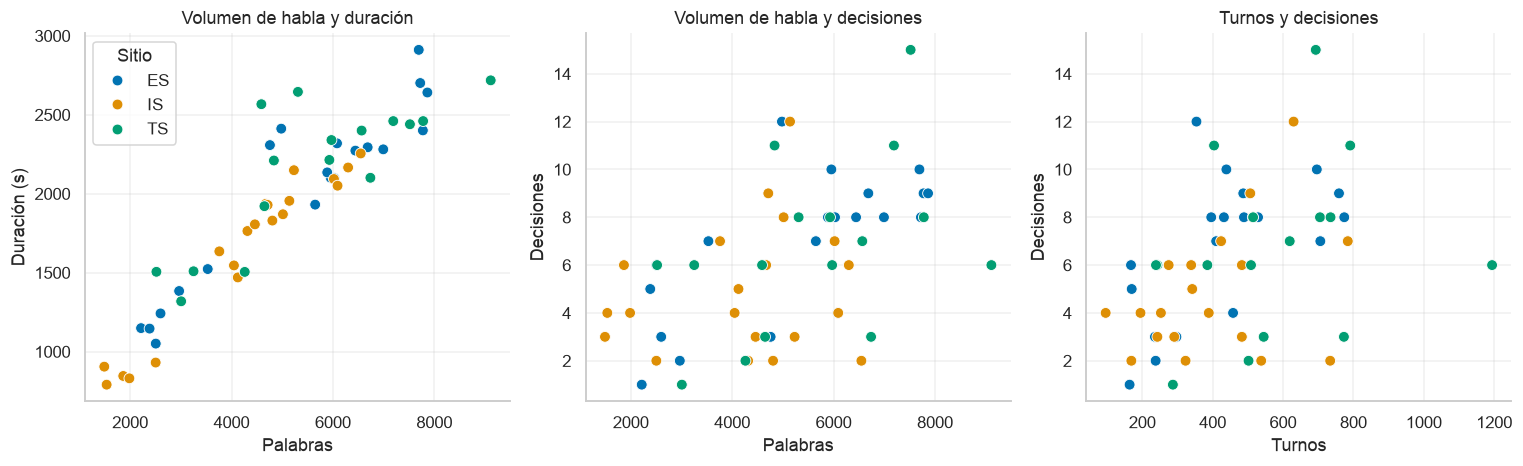

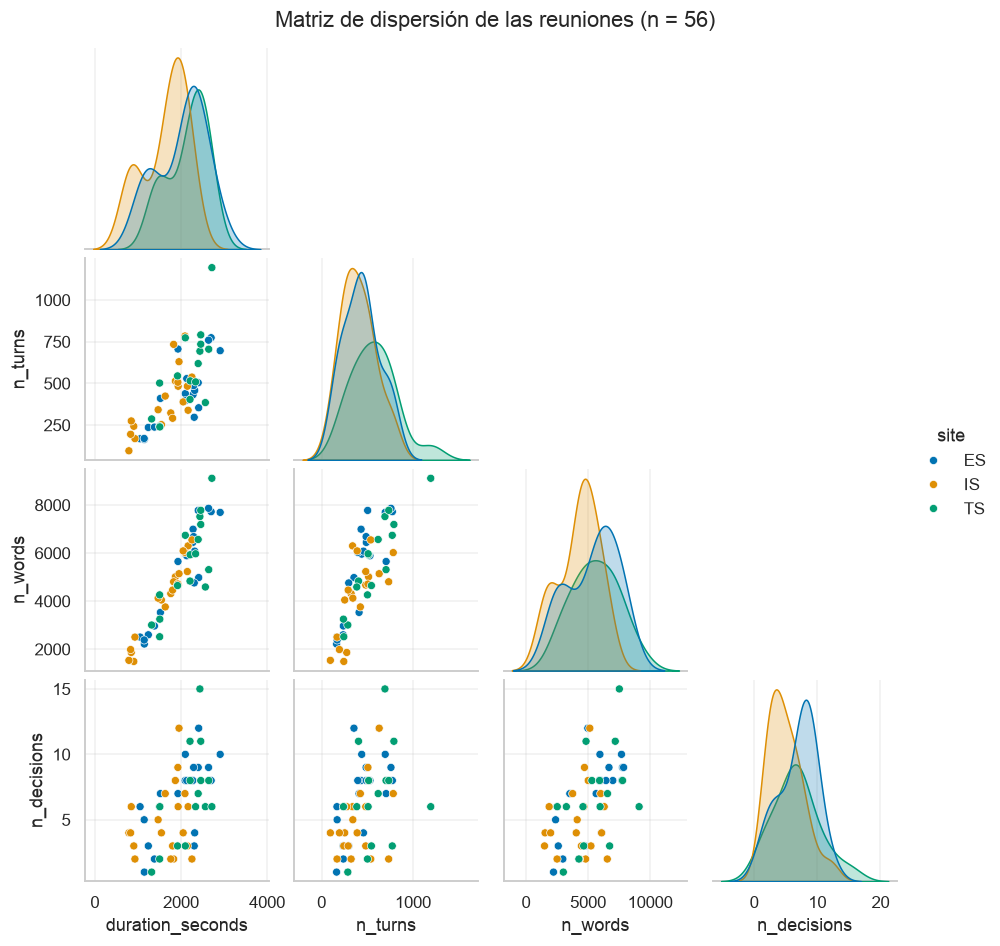

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, (x, y) in zip(
    axes,
    [("n_words", "duration_seconds"), ("n_words", "n_decisions"), ("n_turns", "n_decisions")],
    strict=False,
):
    sns.scatterplot(
        data=MEETING, x=x, y=y, hue="site", palette=SITE_COLOR, s=50, edgecolor="white", ax=ax
    )
    ax.set_xlabel(LABEL[x])
    ax.set_ylabel(LABEL[y])
axes[0].set_title("Volumen de habla y duración")
axes[1].set_title("Volumen de habla y decisiones")
axes[2].set_title("Turnos y decisiones")
for ax in axes[1:]:
    ax.legend().remove()
axes[0].legend(title="Sitio")
plt.tight_layout()
plt.show()

PAIRPLOT_VARS = ["duration_seconds", "n_turns", "n_words", "n_decisions"]
grid = sns.pairplot(
    MEETING,
    vars=PAIRPLOT_VARS,
    hue="site",
    palette=SITE_COLOR,
    corner=True,
    plot_kws={"s": 28, "edgecolor": "white"},
    diag_kind="kde",
    height=2.1,
)
grid.figure.suptitle("Matriz de dispersión de las reuniones (n = 56)", y=1.02)
plt.show()

**Lectura.** Los diagramas muestran dos tipos de relación:

- **Palabras y duración** forman una nube casi lineal (r de Pearson 0,92, §7.1): una reunión más larga contiene más palabras de forma bastante proporcional, en los tres sitios.
- **Decisiones frente a volumen** es una nube ancha: con 5.000 palabras hay reuniones de 2 a 12 decisiones (r de 0,51 con las palabras y de 0,41 con los turnos). El tamaño de la conversación **explica solo una parte** del número de decisiones.
- En el diagrama de duración, IS tiene más reuniones cortas (§6.3 lo cuantifica). TS3005d es el punto aislado arriba a la derecha (9.112 palabras, 1.194 turnos), el mismo que se vio como atípico en §5.

## 6.2 Dos variables categóricas: contingencia, mosaico y chi-cuadrado

Una **tabla de contingencia** cuenta cuántas observaciones caen en cada combinación. El
**gráfico de mosaico** dibuja esas cuentas como rectángulos: el ancho de cada columna es
proporcional a su total y la altura de cada rectángulo, a su proporción dentro de la columna.
La prueba **chi-cuadrado** contrasta si las dos variables son independientes, y la **V de
Cramér** (0 = independencia, 1 = asociación perfecta) mide la intensidad. Cuando una tabla
2×2 tiene frecuencias esperadas menores que 5 se usa la prueba exacta de Fisher.

In [25]:
def draw_mosaic(ax, table, title, colors, legend_title):
    """Draw a mosaic plot with matplotlib from the rectangles of eda.mosaic_rectangles."""
    rects = eda.mosaic_rectangles(table)
    for r in rects.itertuples():
        ax.add_patch(
            Rectangle(
                (r.x, r.y), r.width, r.height, facecolor=colors[r.row], edgecolor="white", lw=1.2
            )
        )
        if r.width * r.height > 0.015:
            ax.text(
                r.x + r.width / 2,
                r.y + r.height / 2,
                str(r.count),
                ha="center",
                va="center",
                fontsize=9,
                color="white" if r.height > 0.06 else "black",
            )
    for col, parte in rects.groupby("col", sort=False):
        ax.text(
            parte["x"].iloc[0] + parte["width"].iloc[0] / 2,
            -0.04,
            str(col),
            ha="center",
            va="top",
            fontsize=9,
        )
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.set_title(title, fontsize=10)
    for spine in ax.spines.values():
        spine.set_visible(False)
    handles = [Rectangle((0, 0), 1, 1, facecolor=colors[k]) for k in table.index]
    ax.legend(
        handles,
        [str(k) for k in table.index],
        title=legend_title,
        loc="center left",
        bbox_to_anchor=(1.0, 0.5),
        fontsize=8,
        title_fontsize=8,
        frameon=False,
    )


CONTINGENCY = {
    "Rol que respalda la decisión por sitio": (DECISION, "evidence_role", "site"),
    "Decisión con evidencia por sitio": (DECISION, "anchored", "site"),
    "Par candidato por distancia entre reuniones": (PAIR, "is_candidate", "meeting_distance"),
    "Par candidato por sitio": (PAIR, "is_candidate", "site"),
    "Condición de lengua por sitio": (SPEAKER_CTX, "native_status", "site"),
}
tablas, filas = {}, []
for nombre, (df, fila, col) in CONTINGENCY.items():
    tablas[nombre] = eda.contingency_table(df, fila, col)
    filas.append({"par de variables": nombre, **asdict(eda.chi2_independence(tablas[nombre]))})
chi_tabla = pd.DataFrame(filas).set_index("par de variables")
display(
    chi_tabla[
        ["test", "statistic", "dof", "p_value", "cramers_v", "min_expected", "n", "odds_ratio"]
    ].round(4)
)
for nombre, tabla in tablas.items():
    print(f"\n{nombre}")
    display(tabla)

,test,statistic,dof,p_value,cramers_v,min_expected,n,odds_ratio
par de variables,,,,,,,,
Rol que respalda la decisión por sitio,chi2,8.9765,8,0.3443,0.1190,7.5457,317,NaN
Decisión con evidencia por sitio,chi2,3.2483,2,0.1971,0.0973,7.5044,343,NaN
Par candidato por distancia entre reuniones,chi2,7.9159,2,0.0191,0.0508,10.2455,3071,NaN
Par candidato por sitio,chi2,0.8225,2,0.6628,0.0164,21.4497,3071,NaN
Condición de lengua por sitio,chi2,338.3333,4,0.0000,0.8690,18.2857,224,NaN



Rol que respalda la decisión por sitio


site,ES,IS,TS
evidence_role,,,
ID,24,19,13
ME,10,9,14
PM,68,44,41
UI,8,10,8
mixed,20,10,19



Decisión con evidencia por sitio


site,ES,IS,TS
anchored,,,
False,7,7,12
True,130,92,95


...

meeting_distance,1,2,3
is_candidate,,,
False,1609,1032,338
True,62,26,4



Par candidato por sitio


site,ES,IS,TS
is_candidate,,,
False,1313,694,972
True,44,22,26



Condición de lengua por sitio


site,ES,IS,TS
native_status,,,
native,76,20,0
non_native,4,60,0
unknown,0,0,64


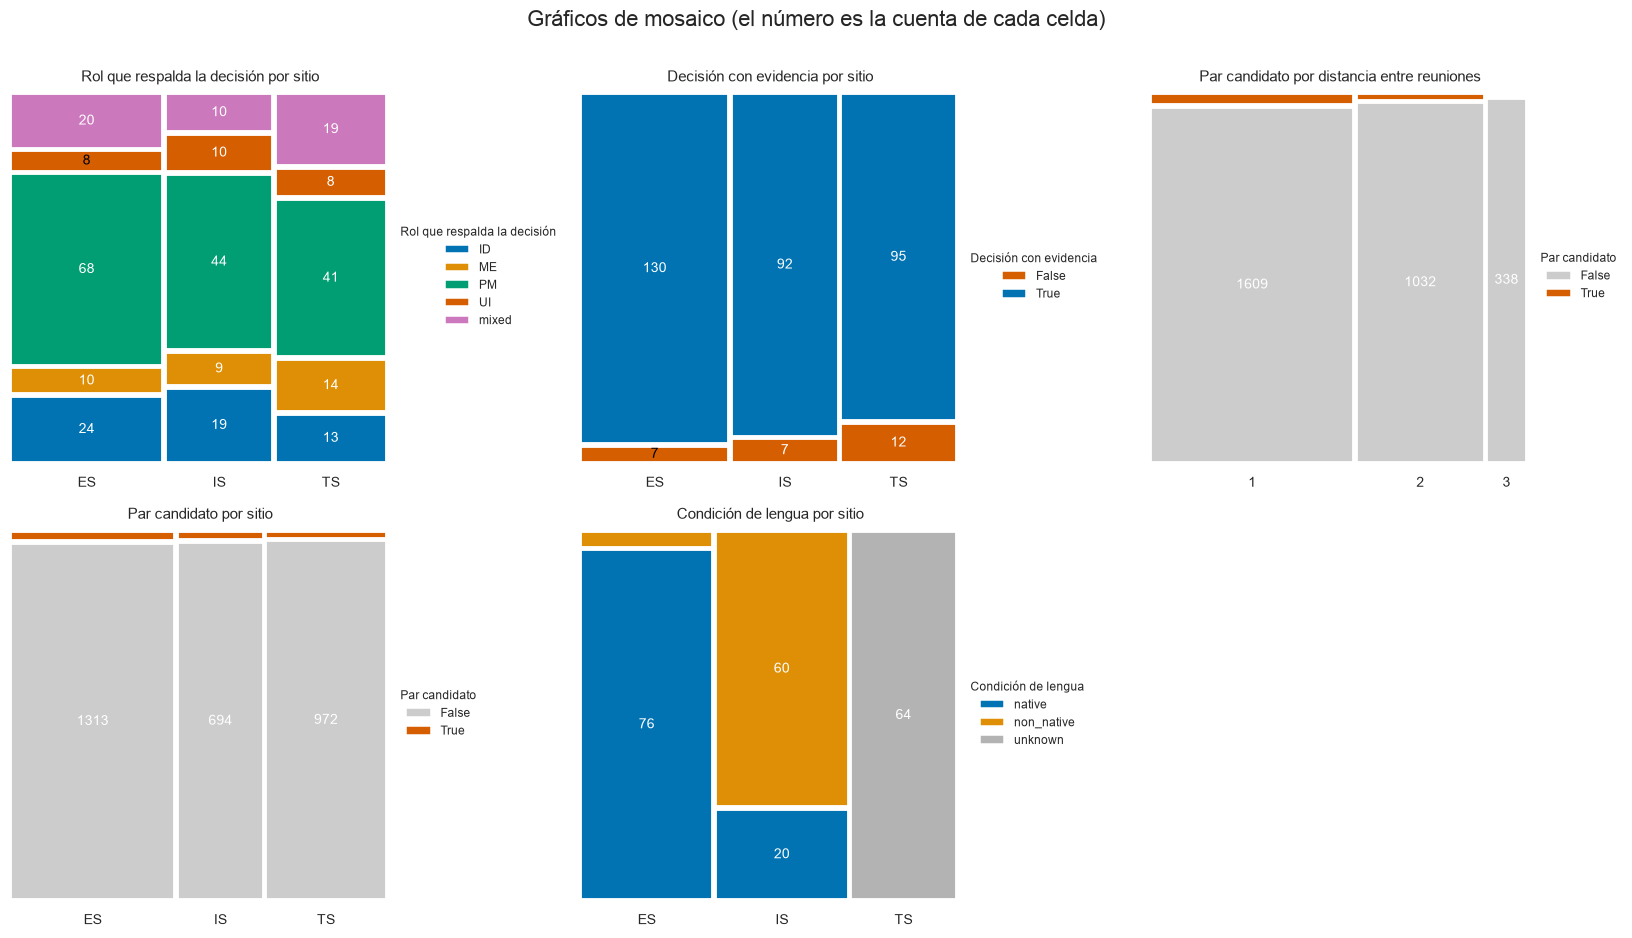

In [26]:
palettes = {
    "Rol que respalda la decisión por sitio": dict(
        zip(tablas["Rol que respalda la decisión por sitio"].index, PAL, strict=False)
    ),
    "Decisión con evidencia por sitio": {True: PAL[0], False: PAL[3]},
    "Par candidato por distancia entre reuniones": {True: PAL[3], False: "0.8"},
    "Par candidato por sitio": {True: PAL[3], False: "0.8"},
    "Condición de lengua por sitio": {"native": PAL[0], "non_native": PAL[1], "unknown": "0.7"},
}
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, (nombre, tabla) in zip(axes.flat, tablas.items(), strict=False):
    draw_mosaic(ax, tabla, nombre, palettes[nombre], nombre.split(" por ")[0])
axes.flat[-1].axis("off")
fig.suptitle("Gráficos de mosaico (el número es la cuenta de cada celda)", y=1.0)
plt.tight_layout()
plt.show()

**Lectura.** Todas las tablas cumplen la condición de frecuencias esperadas ≥ 5, por lo que se usó chi-cuadrado en todas.

| Par de variables | χ² (gl) | p | V de Cramér | Lectura |
|---|---|---|---|---|
| Rol que respalda × sitio | 8,98 (8) | 0,344 | 0,119 | Sin dependencia detectable; el PM es el rol más frecuente en los tres sitios (68, 44 y 41 decisiones) |
| Decisión con evidencia × sitio | 3,25 (2) | 0,197 | 0,097 | Sin dependencia; sin evidencia: 7 (ES), 7 (IS) y 12 (TS) |
| Candidato × distancia | 7,92 (2) | 0,019 | 0,051 | Significativa pero con efecto **muy pequeño** |
| Candidato × sitio | 0,82 (2) | 0,663 | 0,016 | Sin dependencia |
| Lengua × sitio | 338,3 (4) | < 0,001 | 0,869 | Asociación casi total (anidamiento) |

- **Lo que no depende del sitio:** quién respalda las decisiones, si tienen evidencia y si el par es candidato. Es evidencia a favor de HE3: la estructura de las decisiones no cambia con el sitio. Con 343 decisiones y 3.071 pares la prueba tiene potencia limitada para efectos pequeños, así que se trata de ausencia de evidencia de diferencia, no de prueba de igualdad.
- **Candidato y distancia:** de 1.671 pares a distancia 1, 62 son candidatos; de 1.058 a distancia 2, 26; de 342 a distancia 3, 4. La dependencia es real pero pequeña (V ≈ 0,05), y se desarrolla en §10.2.
- **Lengua y sitio:** ES tiene 76 hablantes-reunión nativos y 4 no nativos; IS, 20 y 60; TS, 64 desconocidos. V = 0,87 es la cifra que respalda D7 y D8: no se puede separar el efecto de la lengua del efecto del sitio.

## 6.3 Una variable numérica según una categórica: Kruskal-Wallis

La prueba de **Kruskal-Wallis** compara la distribución de una variable numérica entre
dos o más grupos sin suponer normalidad (usa rangos). Su tamaño de efecto, **ε² (épsilon
cuadrado)**, va de 0 (ningún corrimiento de rangos) a 1 (separación completa); como referencia
convencional, alrededor de 0,01 es pequeño, 0,06 mediano y 0,14 grande. Cuando la fórmula da un
valor ligeramente negativo (posible con pocas observaciones), se lee como cero.

In [27]:
KRUSKAL_CASES = [
    (MEETING, "duration_seconds", "site"),
    (MEETING, "n_words", "site"),
    (MEETING, "n_turns", "site"),
    (MEETING, "n_decisions", "site"),
    (MEETING, "n_decisions", "position"),
    (MEETING, "n_words", "position"),
    (DECISION, "n_tokens", "site"),
    (DECISION, "n_tokens", "position"),
    (SERIES_T, "candidate_rate", "site"),
    (PAIR, "overlap", "site"),
    (PAIR, "overlap", "meeting_distance"),
    (SPEAKER, "talk_share", "role"),
    (SPEAKER, "n_decision_acts", "role"),
]
nivel_de = {
    id(MEETING): "reunión",
    id(DECISION): "decisión",
    id(SERIES_T): "serie",
    id(PAIR): "par",
    id(SPEAKER): "hablante-reunión",
}
kr = pd.DataFrame(
    [
        {
            "nivel": nivel_de[id(df)],
            "variable": v,
            "grupos": g,
            **asdict(eda.kruskal_by_group(df, v, g)),
        }
        for df, v, g in KRUSKAL_CASES
    ]
)
display(kr.round(4))

,nivel,variable,grupos,statistic,p_value,epsilon_squared,n,n_groups
0,reunión,duration_seconds,site,10.5646,0.0051,0.1616,56,3
1,reunión,n_words,site,5.6079,0.0606,0.0681,56,3
2,reunión,n_turns,site,5.1227,0.0772,0.0589,56,3
3,reunión,n_decisions,site,5.0829,0.0788,0.0582,56,3
4,reunión,n_decisions,position,13.8033,0.0032,0.2078,56,4
5,reunión,n_words,position,30.2669,0.0000,0.5244,56,4
6,decisión,n_tokens,site,16.9239,0.0002,0.0439,343,3
7,decisión,n_tokens,position,1.7707,0.6213,-0.0036,343,4
8,serie,candidate_rate,site,0.2257,0.8933,-0.1613,14,3
9,par,overlap,site,72.4149,0.0000,0.0230,3071,3


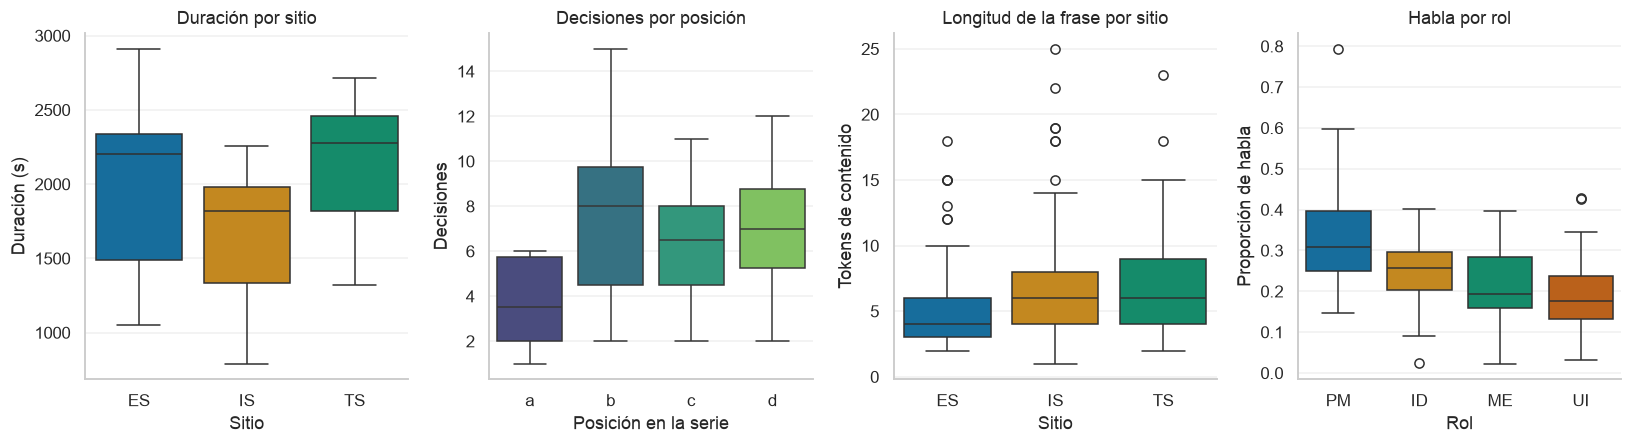

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
sns.boxplot(
    data=MEETING,
    x="site",
    y="duration_seconds",
    order=["ES", "IS", "TS"],
    palette=SITE_COLOR,
    hue="site",
    legend=False,
    ax=axes[0],
)
axes[0].set_xlabel("Sitio")
axes[0].set_ylabel(LABEL["duration_seconds"])
axes[0].set_title("Duración por sitio")
sns.boxplot(
    data=MEETING,
    x="position",
    y="n_decisions",
    order=list("abcd"),
    palette=POS_COLOR,
    hue="position",
    legend=False,
    ax=axes[1],
)
axes[1].set_xlabel("Posición en la serie")
axes[1].set_ylabel(LABEL["n_decisions"])
axes[1].set_title("Decisiones por posición")
sns.boxplot(
    data=DECISION,
    x="site",
    y="n_tokens",
    order=["ES", "IS", "TS"],
    palette=SITE_COLOR,
    hue="site",
    legend=False,
    ax=axes[2],
)
axes[2].set_xlabel("Sitio")
axes[2].set_ylabel(LABEL["n_tokens"])
axes[2].set_title("Longitud de la frase por sitio")
sns.boxplot(
    data=SPEAKER,
    x="role",
    y="talk_share",
    order=["PM", "ID", "ME", "UI"],
    palette=ROLE_COLOR,
    hue="role",
    legend=False,
    ax=axes[3],
)
axes[3].set_xlabel("Rol")
axes[3].set_ylabel(LABEL["talk_share"])
axes[3].set_title("Habla por rol")
plt.tight_layout()
plt.show()

**Lectura.** El tamaño de efecto (ε²) permite separar lo estadísticamente significativo de lo prácticamente relevante:

- **Por sitio, en reuniones:** la **duración** difiere de forma apreciable (H = 10,56, p = 0,005, ε² = 0,16, grande); los diagramas indican que IS es la más corta. Palabras (ε² = 0,068), turnos (0,059) y decisiones (0,058) muestran efectos **medianos** pero no significativos a 0,05 (p entre 0,061 y 0,079), con solo 20, 20 y 16 reuniones por sitio. Se lee como una diferencia de volumen posible, sin potencia suficiente para afirmarla.
- **Por posición, en reuniones:** el efecto es mayor que el del sitio. Las palabras casi se separan por completo (ε² = 0,52, p < 0,0001) y las decisiones tienen un efecto grande (ε² = 0,21, p = 0,003). La **posición en la serie** pesa más que el sitio, y se estudia en §9.
- **Longitud de la frase de decisión:** por sitio, p = 0,0002 pero ε² = 0,044 (pequeño): una diferencia significativa por el tamaño de la muestra, de poca magnitud (el diagrama muestra frases más cortas en ES, mediana de 4 frente a 6 en IS y TS). Por posición, ε² ≈ 0 (−0,004, p = 0,62): la longitud de las frases no cambia a lo largo de la serie.
- **Tasa de candidatos por serie y sitio:** p = 0,89 y ε² negativo (−0,16), que se lee como cero; con 14 series (5, 5 y 4) hay muy poca potencia, de modo que no se puede afirmar ni descartar una diferencia.
- **Solapamiento de los pares:** por sitio H = 72,4 con p ≈ 2e-16, pero ε² = 0,023; por distancia, ε² = 0,0055. Con 3.071 pares casi cualquier diferencia es significativa; el tamaño de efecto dice que son **mínimas**.
- **Por rol, en hablantes:** la proporción de habla (ε² = 0,22) y los actos de decisión (ε² = 0,22) difieren con efecto grande: el rol importa. El diagrama muestra que el PM tiene más de ambos.

**Dos advertencias sobre los valores p.** (1) Los cuatro hablantes de una reunión, y los cuatro participantes de una serie, **no son independientes** entre sí. (2) Los 3.071 pares **comparten decisiones** (cada decisión aparece en muchos pares). Ambos hechos vuelven optimistas los p de los niveles de hablante y de par; el tamaño de efecto es la cifra más prudente.

---

# 7. Dependencias y correlaciones

## 7.1 Tres coeficientes, tres preguntas distintas

| Coeficiente | Qué mide | Sensible a |
|---|---|---|
| **Pearson** (r) | relación **lineal** | valores extremos; supone linealidad |
| **Spearman** (ρ) | relación **monótona**, sobre los rangos | poco a los extremos; los empates lo debilitan |
| **Kendall** (τ) | concordancia de pares de observaciones | empates; es más conservador (valores menores) |

Si Spearman supera a Pearson, la relación es monótona pero no lineal o hay extremos que
distorsionan a Pearson. Los conteos con muchos valores repetidos (decisiones por reunión) se
leen mejor con Spearman o Kendall.

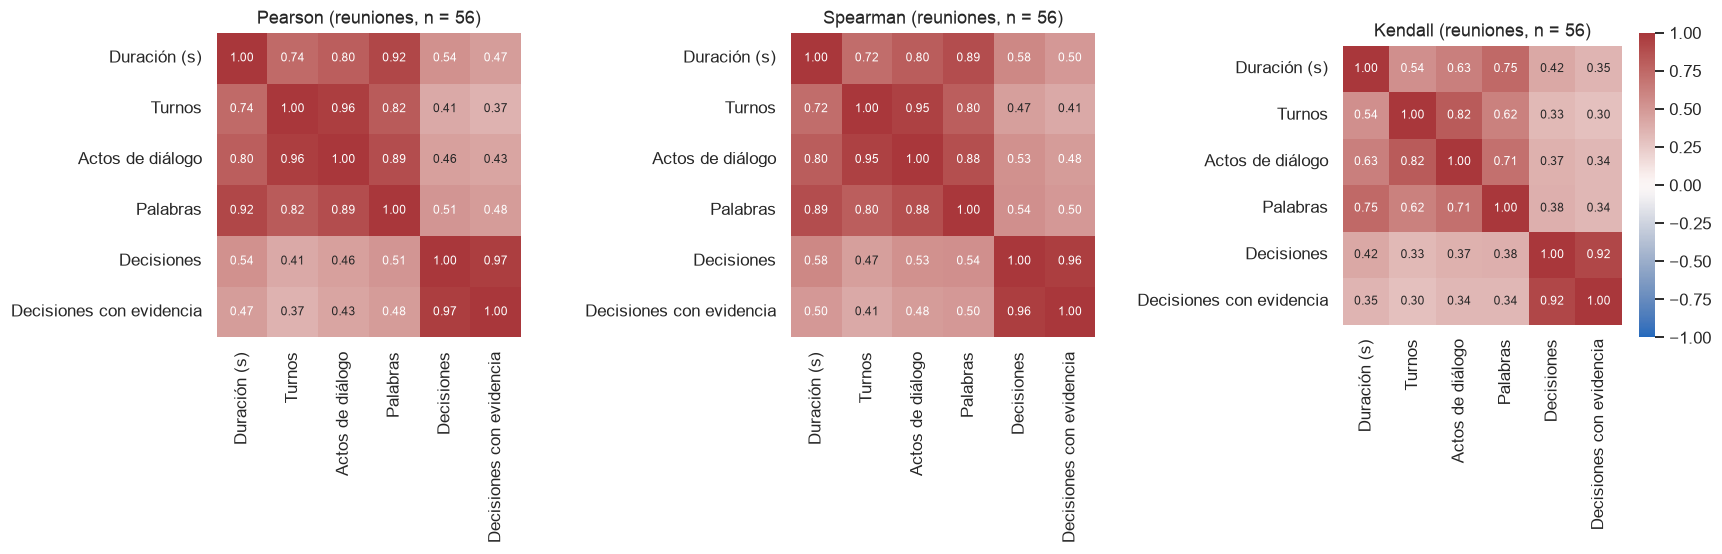

method                                 kendall  pearson  spearman
x                y                                               
duration_seconds n_anchored_decisions    0.354    0.470     0.496
                 n_decisions             0.416    0.537     0.579
                 n_dialogue_acts         0.626    0.802     0.805
                 n_turns                 0.542    0.742     0.722
                 n_words                 0.749    0.915     0.886
n_decisions      n_anchored_decisions    0.916    0.965     0.964
n_dialogue_acts  n_anchored_decisions    0.338    0.435     0.480
                 n_decisions             0.370    0.459     0.532
                 n_words                 0.710    0.886     0.876
n_turns          n_anchored_decisions    0.296    0.366     0.414
                 n_decisions             0.330    0.408     0.468
                 n_dialogue_acts         0.817    0.964     0.951
                 n_words                 0.619    0.819     0.804
n_words          n_anchored_decisions    0.342    0.478     0.497
                 n_decisions             0.381    0.510     0.544

In [29]:
CORR_VARS = [
    "duration_seconds",
    "n_turns",
    "n_dialogue_acts",
    "n_words",
    "n_decisions",
    "n_anchored_decisions",
]
ct = eda.correlation_table(MEETING, CORR_VARS)


def corr_matrix(table, method, variables):
    """Reshape the long correlation table into a square matrix for a heatmap."""
    m = pd.DataFrame(1.0, index=variables, columns=variables)
    for r in table[table["method"] == method].itertuples():
        m.loc[r.x, r.y] = m.loc[r.y, r.x] = r.r
    return m


fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, method, titulo in zip(
    axes, ["pearson", "spearman", "kendall"], ["Pearson", "Spearman", "Kendall"], strict=False
):
    m = corr_matrix(ct, method, CORR_VARS)
    sns.heatmap(
        m.rename(index=LABEL, columns=LABEL),
        annot=True,
        fmt=".2f",
        vmin=-1,
        vmax=1,
        cmap="vlag",
        square=True,
        cbar=(method == "kendall"),
        annot_kws={"fontsize": 8},
        ax=ax,
    )
    ax.set_title(f"{titulo} (reuniones, n = 56)")
    ax.grid(False)
plt.tight_layout()
plt.show()

display(ct.pivot_table(index=["x", "y"], columns="method", values="r").round(3))

## 7.2 Correlaciones en los otros niveles

In [30]:
OTHER = {
    "decisión": (DECISION, ["n_tokens", "n_chars", "n_evidence_acts"]),
    "hablante-reunión": (SPEAKER, ["n_turns", "n_words", "talk_share", "n_decision_acts"]),
}
PAIR_F = eda.add_pair_features(PAIR)
OTHER["par"] = (PAIR_F, ["shorter_tokens", "shared_tokens", "overlap", "meeting_distance"])
for nivel, (df, cols) in OTHER.items():
    print(f"\nNivel {nivel}")
    display(
        eda.correlation_table(df, cols)
        .pivot_table(index=["x", "y"], columns="method", values="r")
        .round(3)
    )


Nivel decisión


method                    kendall  pearson  spearman
x        y                                          
n_chars  n_evidence_acts    0.239    0.503     0.316
n_tokens n_chars            0.848    0.969     0.950
         n_evidence_acts    0.250    0.481     0.315


Nivel hablante-reunión


method                      kendall  pearson  spearman
x          y                                          
n_turns    n_decision_acts    0.316    0.350     0.443
           n_words            0.581    0.754     0.773
           talk_share         0.315    0.340     0.460
n_words    n_decision_acts    0.366    0.430     0.507
           talk_share         0.569    0.657     0.759
talk_share n_decision_acts    0.295    0.301     0.417


Nivel par


method                           kendall  pearson  spearman
x              y                                           
overlap        meeting_distance   -0.055   -0.075    -0.062
shared_tokens  meeting_distance   -0.060   -0.080    -0.063
               overlap             0.890    0.868     0.961
shorter_tokens meeting_distance   -0.010   -0.039    -0.012
               overlap            -0.147   -0.181    -0.151
               shared_tokens       0.012    0.109     0.014

## 7.3 Multicolinealidad: el factor de inflación de la varianza (VIF)

El **VIF** de una variable es 1 / (1 − R²), donde R² es lo que explican de ella las demás
variables. Un VIF mayor que 5 (criterio estricto) o 10 (criterio laxo) indica colinealidad: la
variable casi no aporta información propia y cualquier modelo lineal sería inestable.

In [31]:
vif_full = eda.variance_inflation_factors(MEETING, CORR_VARS)
vif_reduced = eda.variance_inflation_factors(MEETING, OUT_VARS)
display(
    vif_full.merge(
        vif_reduced, on="variable", how="outer", suffixes=(" (6 variables)", " (4 variables)")
    ).round(2)
)

,variable,vif (6 variables),r_squared (6 variables),vif (4 variables),r_squared (4 variables)
0,duration_seconds,7.39,0.86,6.44,0.84
1,n_anchored_decisions,18.80,0.95,NaN,NaN
2,n_decisions,19.82,0.95,1.41,0.29
3,n_dialogue_acts,25.53,0.96,NaN,NaN
4,n_turns,16.98,0.94,3.05,0.67
5,n_words,10.87,0.91,8.47,0.88


## 7.4 Confusores y estratificación

Un **confusor** es una tercera variable que genera o distorsiona una asociación aparente. En estos
datos hay tres candidatos evidentes:

- **El sitio y la lengua van anidados** (D7): no se puede separar el efecto de uno del otro.
- **La longitud de la reunión** determina casi todos los conteos (turnos, actos, decisiones).
- **La posición en la serie** (a–d) cambia a la vez la longitud y el número de decisiones (§9).

Una forma sencilla de comprobar si un confusor explica una asociación es **estratificar**: repetir la
correlación dentro de cada nivel del confusor.

In [32]:
estratos = []
for k in (1, 2, 3, 4):
    r = eda.correlation_table(
        MEETING[MEETING["position_index"] == k], ["n_words", "n_decisions"], ["spearman"]
    )
    estratos.append(
        {"estrato": f"posición {'abcd'[k - 1]}", **r.iloc[0][["r", "p", "n"]].to_dict()}
    )
for s in ("ES", "IS", "TS"):
    r = eda.correlation_table(
        MEETING[MEETING["site"] == s], ["n_words", "n_decisions"], ["spearman"]
    )
    estratos.append({"estrato": f"sitio {s}", **r.iloc[0][["r", "p", "n"]].to_dict()})
r = eda.correlation_table(MEETING, ["n_words", "n_decisions"], ["spearman"])
estratos.append({"estrato": "todas las reuniones", **r.iloc[0][["r", "p", "n"]].to_dict()})
display(pd.DataFrame(estratos).round(4))

print("Autoría de decisiones y habla: correlación de Spearman entre hablantes-reunión")
display(
    eda.correlation_table(
        SPEAKER, ["n_words", "talk_share", "n_decision_acts"], ["spearman"]
    ).round(4)
)

,estrato,r,p,n
0,posición a,-0.1747,0.5502,14
1,posición b,0.2343,0.4202,14
2,posición c,0.5856,0.0278,14
3,posición d,0.2525,0.3838,14
4,sitio ES,0.6867,0.0008,20
5,sitio IS,0.1315,0.5805,20
6,sitio TS,0.5098,0.0436,16
7,todas las reuniones,0.5441,0.0000,56


Autoría de decisiones y habla: correlación de Spearman entre hablantes-reunión


,x,y,method,r,p,n
0,n_words,talk_share,spearman,0.7588,0.0,224
1,n_words,n_decision_acts,spearman,0.5067,0.0,224
2,talk_share,n_decision_acts,spearman,0.4171,0.0,224


**Lectura.**

- **Las variables de tamaño se mueven juntas.** Palabras con duración: r = 0,915 (ρ = 0,886; τ = 0,749). Turnos con actos de diálogo: r = 0,964 (ρ = 0,951; τ = 0,817). Palabras con actos: r = 0,886. El número de decisiones y el de decisiones con evidencia: r = 0,965, es decir, casi la misma variable. En cambio, las decisiones con el tamaño tienen relaciones **moderadas**: con palabras r = 0,510 (ρ = 0,544; τ = 0,381); con turnos, r = 0,408 (ρ = 0,468; τ = 0,330).
- **Diferencias entre los métodos.** (a) Kendall siempre da magnitudes menores (su escala es distinta; τ ≈ ⅔ ρ es habitual). (b) En las relaciones de las decisiones Spearman supera a Pearson (decisiones con turnos: 0,468 frente a 0,408; con actos de diálogo: 0,532 frente a 0,459): la relación es **monótona pero no lineal**, y un valor extremo (los 1.194 turnos de TS3005d) puede deprimirla en Pearson. (c) En una relación casi lineal (palabras con duración) Pearson es el más alto. (d) En el nivel de decisiones, caracteres con actos de evidencia: Pearson 0,503, Spearman 0,316 y Kendall 0,239. La cifra de Pearson está **inflada por unas pocas decisiones extremas** (§5.4); la de Spearman describe mejor a la decisión típica.
- **Pares.** El solapamiento se relaciona de forma débilmente negativa con la longitud de la decisión más corta (r = −0,18; ρ = −0,15): cuanto más corta, algo mayor el coeficiente, que es el mecanismo de §10.3. Con los tokens compartidos la relación es alta por construcción (r = 0,87; ρ = 0,96). Con la distancia, ρ ≈ −0,06: el solapamiento baja muy levemente al alejarse.
- **Hablantes.** Palabras con proporción de habla, r = 0,75 (por construcción); palabras con actos de decisión, ρ = 0,507 y proporción de habla con actos de decisión, ρ = 0,417.

**Multicolinealidad (VIF).** Con las seis variables todas superan 5: duración 7,39; turnos 16,98; actos de diálogo 25,53; palabras 10,87; decisiones 19,82 y decisiones con evidencia 18,80. Con las cuatro adoptadas: duración 6,44; palabras 8,47; turnos 3,05; decisiones 1,41. Duración y palabras siguen siendo colineales (r = 0,92). **Recomendación:** en cualquier modelo, usar una sola de ellas, y descartar los actos de diálogo y las decisiones con evidencia, que no añaden información.

**Confusores.**

- **Posición.** La correlación entre palabras y decisiones es ρ = 0,544 en las 56 reuniones, pero **dentro de cada posición** cambia: −0,175 en a (p = 0,55), 0,234 en b (p = 0,42), 0,586 en c (p = 0,028) y 0,252 en d (p = 0,38), con n = 14 en cada estrato. Parte de la asociación global la produce la posición (las reuniones a son cortas y tienen pocas decisiones). La pérdida de significancia dentro de cada estrato se debe también a su tamaño; no se puede decir que la relación desaparezca.
- **Sitio.** Dentro de ES, ρ = 0,687 (p = 0,0008); dentro de TS, 0,510 (p = 0,044); dentro de IS, 0,132 (p = 0,58). La relación entre volumen y decisiones **no es homogénea entre sitios**.
- **Sitio y lengua** van anidados (V = 0,87, §6.2): cualquier efecto de uno es indistinguible del otro.
- **Rol y habla.** El PM habla más (ε² = 0,22) y respalda más decisiones; entre hablantes, quien habla más aporta más actos (ρ = 0,507). Con estos datos no se puede separar que "el PM decide más" de que "el PM habla más".

**Correlación no implica causalidad.** Todo lo anterior describe asociaciones. Que una reunión con más palabras tenga más decisiones no significa que hablar más produzca decisiones; ambas variables dependen de la posición en la serie, del sitio y de cómo escribieron el resumen los anotadores.

---

# 8. Análisis multivariado

Aquí se busca **estructura conjunta**: ejes que resuman muchas variables (análisis de componentes
principales) y grupos naturales (agrupamiento). La pregunta de fondo es honesta: ¿esta estructura
añade algo que sitio y posición no digan ya?

## 8.1 Componentes principales (PCA) de las reuniones

El **PCA** (*principal component analysis*) gira las variables estandarizadas hacia nuevos ejes
ordenados por la varianza que explican. Una **carga** (*loading*) es la correlación entre una
variable y un componente. El **criterio de Kaiser** conserva los componentes con valor propio
mayor que 1 (es decir, que explican más que una variable original).

,varianza explicada,acumulada
PC1,0.752,0.752
PC2,0.165,0.917
PC3,0.065,0.982
PC4,0.018,1.000


Componentes con valor propio > 1 (Kaiser): 1


,PC1,PC2,PC3,PC4
duration_seconds,0.938,-0.091,-0.290,-0.165
n_words,0.955,-0.164,-0.132,0.208
n_turns,0.873,-0.288,0.389,-0.054
n_decisions,0.672,0.736,0.087,0.005


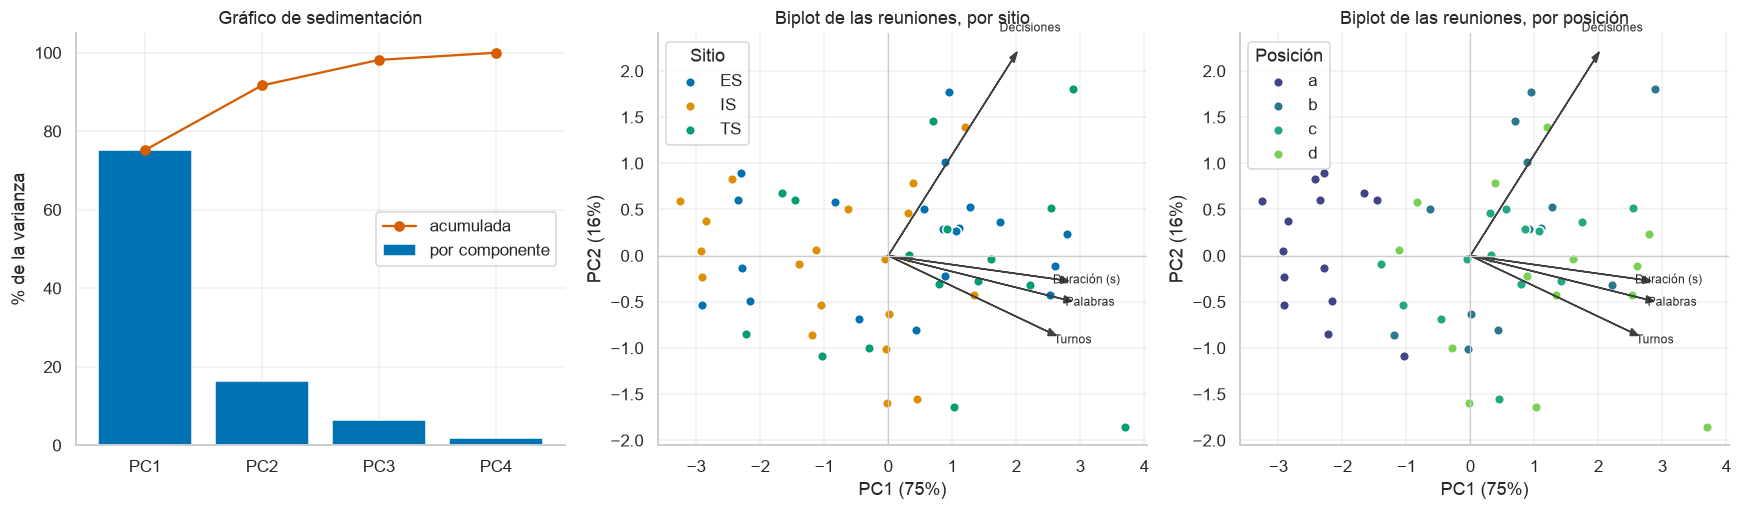

In [33]:
pca = eda.pca_standardized(MEETING, OUT_VARS)
display(
    pd.DataFrame(
        {"varianza explicada": pca.explained_variance_ratio, "acumulada": pca.cumulative}
    ).round(3)
)
print(f"Componentes con valor propio > 1 (Kaiser): {pca.n_kaiser}")
display(pca.loadings.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ax = axes[0]
comp = pca.explained_variance_ratio
ax.bar(range(1, len(comp) + 1), comp.values * 100, color=PAL[0], label="por componente")
ax.plot(
    range(1, len(comp) + 1),
    pca.cumulative.values * 100,
    color=PAL[3],
    marker="o",
    label="acumulada",
)
ax.set_xticks(range(1, len(comp) + 1))
ax.set_xticklabels(comp.index)
ax.set_ylabel("% de la varianza")
ax.set_title("Gráfico de sedimentación")
ax.legend()

scores = pca.scores
for ax, (var, colores, titulo) in zip(
    axes[1:],
    [("site", SITE_COLOR, "por sitio"), ("position", POS_COLOR, "por posición")],
    strict=False,
):
    grupos = MEETING.loc[scores.index, var]
    for g, color in colores.items():
        m = grupos == g
        ax.scatter(
            scores.loc[m, "PC1"],
            scores.loc[m, "PC2"],
            color=color,
            s=40,
            edgecolor="white",
            label=g,
        )
    for variable, fila in pca.loadings.iterrows():
        ax.arrow(
            0,
            0,
            fila["PC1"] * 3,
            fila["PC2"] * 3,
            color="0.25",
            head_width=0.08,
            length_includes_head=True,
        )
        ax.text(fila["PC1"] * 3.3, fila["PC2"] * 3.3, LABEL[variable], fontsize=8, ha="center")
    ax.axhline(0, color="0.8", lw=0.8)
    ax.axvline(0, color="0.8", lw=0.8)
    ax.set_xlabel(f"PC1 ({comp['PC1']:.0%})")
    ax.set_ylabel(f"PC2 ({comp['PC2']:.0%})")
    ax.set_title(f"Biplot de las reuniones, {titulo}")
    ax.legend(title=var.replace("site", "Sitio").replace("position", "Posición"))
plt.tight_layout()
plt.show()

## 8.2 Agrupamiento: ¿hay grupos naturales?

Se prueban **k-medias** (*k-means*, que busca k centros) y **Ward** (aglomerativo jerárquico),
para k de 2 a 6, sobre las variables estandarizadas. Cada configuración se evalúa con el
**coeficiente de silueta** (de −1 a 1): mide cuánto más cerca está cada punto de su grupo que
del grupo vecino. Convencionalmente, por encima de 0,5 la estructura es razonable; entre 0,25 y 0,5,
débil; por debajo de 0,25, inexistente (Kaufman y Rousseeuw, 1990). Se hace a nivel de reunión
(n = 56) y de serie (n = 14).

,nivel,algoritmo,mejor k,silueta máxima,lectura,¿estructura razonable?
0,reunión,kmeans,2,0.449,"estructura débil, posiblemente artificial",False
1,reunión,ward,2,0.422,"estructura débil, posiblemente artificial",False
2,serie,kmeans,2,0.485,"estructura débil, posiblemente artificial",False
3,serie,ward,2,0.485,"estructura débil, posiblemente artificial",False


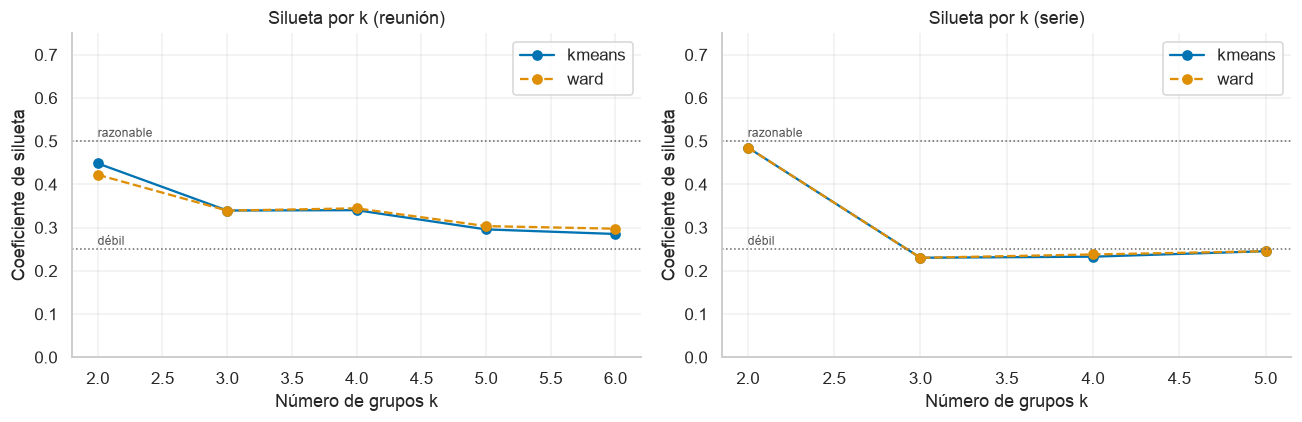

In [34]:
SERIES_CLUSTER_VARS = [
    "n_decisions",
    "candidate_rate",
    "anchoring_rate",
    "median_decision_tokens",
    "total_words",
    "total_duration_seconds",
]
scans = {}
for nivel, df, cols, ks in [
    ("reunión", MEETING, OUT_VARS, range(2, 7)),
    ("serie", SERIES_T, SERIES_CLUSTER_VARS, range(2, 6)),
]:
    for alg in ("kmeans", "ward"):
        scans[(nivel, alg)] = eda.cluster_scan(df, cols, algorithm=alg, k_range=ks)

resumen = pd.DataFrame(
    [
        {
            "nivel": n,
            "algoritmo": a,
            "mejor k": r.best_k,
            "silueta máxima": round(r.best_silhouette, 3),
            "lectura": r.interpretation,
            "¿estructura razonable?": r.meaningful,
        }
        for (n, a), r in scans.items()
    ]
)
display(resumen)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, nivel in zip(axes, ("reunión", "serie"), strict=False):
    for (n, alg), color, ls in [((nivel, "kmeans"), PAL[0], "-"), ((nivel, "ward"), PAL[1], "--")]:
        t = scans[(n, alg)].table
        ax.plot(t["k"], t["silhouette"], color=color, ls=ls, marker="o", label=alg)
    ax.axhline(0.5, color="0.4", ls=":", lw=1)
    ax.text(2, 0.51, "razonable", fontsize=8, color="0.3")
    ax.axhline(0.25, color="0.4", ls=":", lw=1)
    ax.text(2, 0.26, "débil", fontsize=8, color="0.3")
    ax.set_ylim(0, 0.75)
    ax.set_xlabel("Número de grupos k")
    ax.set_ylabel("Coeficiente de silueta")
    ax.set_title(f"Silueta por k ({nivel})")
    ax.legend()
plt.tight_layout()
plt.show()

Para saber qué separa el mejor agrupamiento de reuniones, se cruzan sus grupos con la
posición en la serie y con el sitio.

In [35]:
km = scans[("reunión", "kmeans")]
etiquetado = MEETING.assign(grupo=km.labels)
for var in ("position", "site"):
    t = eda.contingency_table(etiquetado, "grupo", var)
    print(f"Grupo por {var}")
    display(t)
    print(eda.chi2_independence(t))

km_s = scans[("serie", "kmeans")]
print("\nAgrupamiento de series (k-medias)")
display(
    SERIES_T.assign(grupo=km_s.labels)[["series_id", "site", "grupo"]]
    .sort_values(["grupo", "series_id"])
    .reset_index(drop=True)
)
pca_s = eda.pca_standardized(SERIES_T, SERIES_CLUSTER_VARS)
print(
    "PCA de las series: varianza explicada por componente =",
    pca_s.explained_variance_ratio.round(3).to_dict(),
    f"· Kaiser = {pca_s.n_kaiser}",
)

Grupo por position


position,a,b,c,d
grupo,,,,
0,0,12,12,12
1,14,2,2,2


Chi2Result(test='chi2', statistic=33.6, dof=3, p_value=2.406327507491829e-07, cramers_v=0.7745966692414834, min_expected=5.0, n=56, odds_ratio=nan)
Grupo por site


site,ES,IS,TS
grupo,,,
0,14,10,12
1,6,10,4


Chi2Result(test='chi2', statistic=2.862222222222222, dof=2, p_value=0.23904317110812198, cramers_v=0.2260776661041756, min_expected=5.714285714285714, n=56, odds_ratio=nan)

Agrupamiento de series (k-medias)


,series_id,site,grupo
0,ES2002,ES,0
1,ES2008,ES,0
2,ES2014,ES,0
3,ES2015,ES,0
4,ES2016,ES,0
5,IS1003,IS,0
6,IS1004,IS,0
7,IS1006,IS,0
8,IS1009,IS,0
9,TS3003,TS,0


PCA de las series: varianza explicada por componente = {'PC1': 0.504, 'PC2': 0.219, 'PC3': 0.157, 'PC4': 0.072, 'PC5': 0.025, 'PC6': 0.022} · Kaiser = 2


**Lectura.**

- **PCA.** El primer componente explica **75,2 %** de la varianza y el segundo **16,5 %** (91,7 % acumulado). El criterio de Kaiser retiene uno. PC1 recoge el **tamaño de la reunión** (cargas de 0,955 en palabras, 0,938 en duración, 0,873 en turnos y 0,672 en decisiones). PC2 opone las decisiones (carga 0,736) a los turnos (−0,288): mide **decisiones por encima o por debajo de lo que el tamaño predice**.
- **Biplot.** Por sitio no hay separación: los tres colores se solapan (IS se desplaza algo hacia las reuniones pequeñas). Por posición, las reuniones **a** (oscuras) ocupan el lado izquierdo de PC1 y las b–d se mezclan a la derecha: PC1 recupera, en esencia, la diferencia entre la primera reunión y el resto.
- **Agrupamiento de reuniones.** La mejor silueta es 0,449 (k-medias, k = 2) y 0,422 (Ward, k = 2): estructura **débil**, por debajo del umbral de 0,5. El grupo 1 (20 reuniones) contiene las 14 reuniones a y 6 de b–d (dos de cada posición); el grupo 0 (36) tiene solo b–d (12 de cada una). La asociación con la posición es fuerte (V = 0,77, p < 0,001); con el sitio, débil y no significativa (V = 0,23, p = 0,24). **Los grupos reproducen la posición**, que ya se conocía.
- **Agrupamiento de series.** Silueta 0,485 con k = 2 en ambos algoritmos, justo bajo el umbral. El grupo menor tiene **una sola serie** (IS1008, con las menos decisiones, 13, las frases más largas, mediana de 12 tokens, y la tasa de candidatos más alta, 13,3 %); es un valor atípico, no un grupo. El PCA de las series (n = 14, seis variables) reparte la varianza en 50,4 %, 21,9 % y 15,7 % en los tres primeros componentes: con tan pocas series es inestable.

**Conclusión sobre el valor de la estructura multivariada.** **Añade poco.** Las reuniones forman un **continuo de tamaño** con un salto entre la primera reunión de la serie y las demás (HE6 se sostiene), y no hay grupos naturales adicionales. Tampoco los hay entre series, salvo una serie atípica. Las variables que ya se usan como estratos, **sitio** (el factor de balance) y **posición**, capturan lo que el análisis multivariado encuentra. No se justifican estratos de muestreo nuevos basados en agrupamientos. La ausencia de estructura es un resultado, no un fracaso del análisis: era una pregunta legítima y la respuesta es que no hay estructura adicional que explotar.

---

# 9. Análisis temporal: de la reunión a a la d

El eje temporal de este corpus no es un calendario: es la **posición dentro de la serie** (a, b,
c, d), porque las cuatro reuniones de una serie ocurren en ese orden. Interesa saber si algo
cambia con la posición, porque una decisión solo puede ser revisada en una reunión posterior a
aquella en que nació. Se calcula la media y la mediana por posición, y la **tendencia monótona**
con la τ de Kendall entre la posición y la variable (con n = 4 por serie, Kendall es exacto y
conservador). Una tendencia significativa es *creciente*, *decreciente* o *sin tendencia*.

variable,n_decisions,n_turns,duration_seconds,n_words
position_index,,,,
1,3.6,230.4,1151.0,2506.7
2,7.6,462.5,2178.3,5889.7
3,6.4,471.3,2171.0,5710.6
4,6.9,682.8,2169.2,5933.7


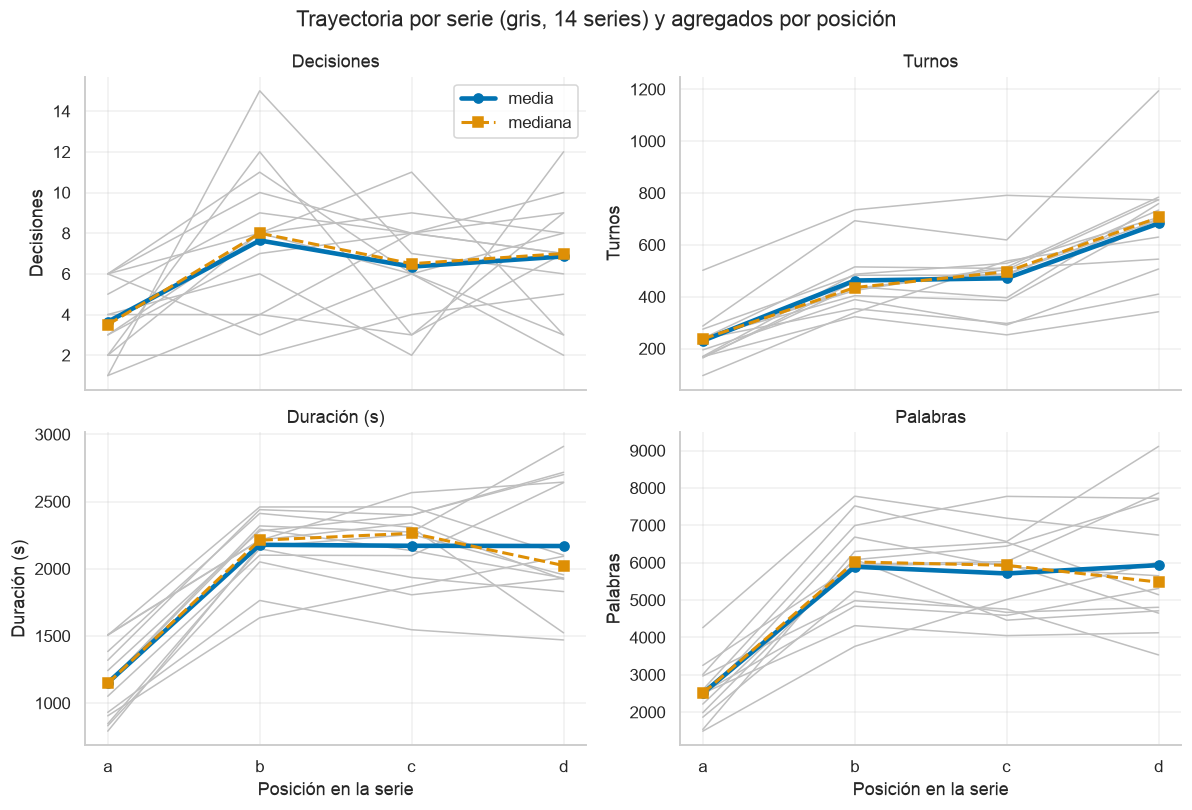

In [36]:
TEMPORAL_VARS = ["n_decisions", "n_turns", "duration_seconds", "n_words"]
agg = eda.position_aggregates(MEETING, TEMPORAL_VARS)
display(
    agg.pivot(index="position_index", columns="variable", values="mean")[TEMPORAL_VARS].round(1)
)

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
for ax, var in zip(axes.flat, TEMPORAL_VARS, strict=False):
    ancho = MEETING.pivot(index="position_index", columns="series_id", values=var)
    ax.plot(ancho.index, ancho.values, color="0.75", lw=1)
    pooled = agg[agg["variable"] == var]
    ax.plot(pooled["position_index"], pooled["mean"], color=PAL[0], lw=3, marker="o", label="media")
    ax.plot(
        pooled["position_index"],
        pooled["median"],
        color=PAL[1],
        lw=2,
        ls="--",
        marker="s",
        label="mediana",
    )
    ax.set_xticks([1, 2, 3, 4])
    ax.set_xticklabels(list("abcd"))
    ax.set_ylabel(LABEL[var])
    ax.set_title(LABEL[var])
for ax in axes[1]:
    ax.set_xlabel("Posición en la serie")
axes[0, 0].legend()
fig.suptitle("Trayectoria por serie (gris, 14 series) y agregados por posición")
plt.tight_layout()
plt.show()

In [37]:
rows = []
for var in TEMPORAL_VARS:
    tr = eda.monotonic_trend(MEETING, var, group="series_id")
    pooled, per = tr[tr["group"] == "ALL"].iloc[0], tr[tr["group"] != "ALL"]
    b_d = eda.monotonic_trend(MEETING[MEETING["position_index"] >= 2], var).iloc[0]
    rows.append(
        {
            "variable": var,
            "τ (a-d, agrupado)": pooled["statistic"],
            "p (a-d)": pooled["p_value"],
            "series con tendencia creciente": int((per["direction"] == "creciente").sum()),
            "series con tendencia significativa": int(per["significant"].sum()),
            "τ (solo b-d)": b_d["statistic"],
            "p (b-d)": b_d["p_value"],
        }
    )
display(pd.DataFrame(rows).round(4))

print("Decisiones por posición de la reunión (14 series)")
display(audit.decisions_by_meeting_position(series=SERIES))

,variable,"τ (a-d, agrupado)",p (a-d),series con tendencia creciente,series con tendencia significativa,τ (solo b-d),p (b-d)
0,n_decisions,0.2594,0.0142,10,0,-0.0694,0.5845
1,n_turns,0.6120,0.0000,14,0,0.3923,0.0013
2,duration_seconds,0.4119,0.0001,10,0,-0.0394,0.7467
3,n_words,0.4176,0.0000,11,0,-0.0253,0.8355


Decisiones por posición de la reunión (14 series)


,meeting_letter,n_series,total_decisions,mean_decisions
0,a,14,51,3.642857
1,b,14,107,7.642857
2,c,14,89,6.357143
3,d,14,96,6.857143


**Lectura.**

- **Medias por posición (a, b, c, d).** Decisiones: 3,6, 7,6, 6,4 y 6,9. Turnos: 230, 463, 471 y 683. Duración: 1.151, 2.178, 2.171 y 2.169 s. Palabras: 2.507, 5.890, 5.711 y 5.934.
- **Tendencia agrupada (Kendall, n = 56):** creciente y significativa en las cuatro variables: decisiones τ = 0,259 (p = 0,014), turnos τ = 0,612 (p < 0,0001), duración τ = 0,412 (p = 0,0001) y palabras τ = 0,418 (p < 0,0001).
- **Por serie.** La tendencia es creciente en 10 de 14 series para las decisiones, 14 de 14 para los turnos, 10 de 14 para la duración y 11 de 14 para las palabras, pero **ninguna serie por sí sola es significativa**. No es sorpresa: con cuatro puntos, ni siquiera un orden perfecto (τ = 1) alcanza p < 0,05 (el p exacto mínimo es 0,083). Por eso interesa el agregado.
- **Hay un quiebre, no una pendiente.** El crecimiento ocurre entre a y b. Desde b hasta d las medias son planas, y la tendencia en b–d no es distinta de cero para decisiones (τ = −0,069, p = 0,58), duración (−0,039, p = 0,75) y palabras (−0,025, p = 0,84). **La reunión a dura la mitad y tiene la mitad de decisiones**; las tres restantes se parecen. La excepción son los turnos, que siguen creciendo en b–d (τ = 0,392, p = 0,0013) mientras las palabras se estabilizan: lo que sugiere turnos más cortos en las reuniones finales.
- **Decisiones totales por posición:** 51 en a, 107 en b, 89 en c y 96 en d (la reunión a aporta 14,9 % de las 343).

**Relevancia para E3.** (1) Las decisiones tardías son más numerosas, así que la mayor parte de las evoluciones posibles ocurren entre b, c y d; la reunión a aporta pocas decisiones de origen. (2) La proporción de decisiones sin evidencia sube justo con la posición (0 %, 4,7 %, 11,2 %, 11,5 %, §3.2), de modo que las decisiones tardías, que son las que cierran las relaciones, son también las más difíciles de anclar. (3) Un banco de preguntas de evolución no debe suponer densidad uniforme de decisiones a lo largo de la serie. Esta sección **no** interpreta un cambio temporal en sentido calendario: el eje es la posición en la serie, con solo cuatro puntos por serie, lo que impide estudiar estacionalidad o autocorrelación.

---

# 10. Análisis dirigido por preguntas

Las secciones anteriores describieron los datos. Esta responde, una por una, las preguntas de §0
con la evidencia que corresponde. Cada subsección cierra con su respuesta y sus límites.

## 10.1 P1 — ¿Caben las reuniones en la ventana de contexto?

La ventana por defecto del espacio de trabajo de OpenKOS es de **12.288 tokens**. El proyecto no
dispone de un tokenizador del modelo, así que el tamaño de cada reunión se **estima** como
1,3 tokens por palabra (regla práctica para vocabularios de subpalabras en inglés), con
caracteres / 4 como contraste. Es una estimación, no una medición, y es **optimista**: cuenta
solo el habla, sin las etiquetas de rol ni los saltos de línea que añade la transcripción
renderizada, y no incluye las instrucciones del sistema ni la respuesta.

Ventana: 12.288 tokens ≈ 9.452 palabras (1,3 tokens por palabra)
Reuniones que caben (estimado): 56 de 56
Reuniones con más de 80 % de la ventana: 6
Reuniones con más de 90 % de la ventana: 1
Series completas (palabras): mínimo 14.990, máximo 26.204


,meeting_id,n_words,approx_tokens,approx_tokens_chars,context_ratio
0,TS3005d,9112,11846,11089,0.964
1,ES2008d,7863,10222,9997,0.832
2,TS3009b,7779,10113,9570,0.823
3,ES2002c,7774,10107,9804,0.823
4,ES2002d,7722,10039,9816,0.817
5,ES2014d,7693,10001,9779,0.814


,meeting_id,n_words,approx_tokens,context_ratio
0,ES2015a,2384,3100,0.252
1,ES2015b,6685,8691,0.707
2,ES2015c,5888,7655,0.623
3,ES2015d,5650,7345,0.598


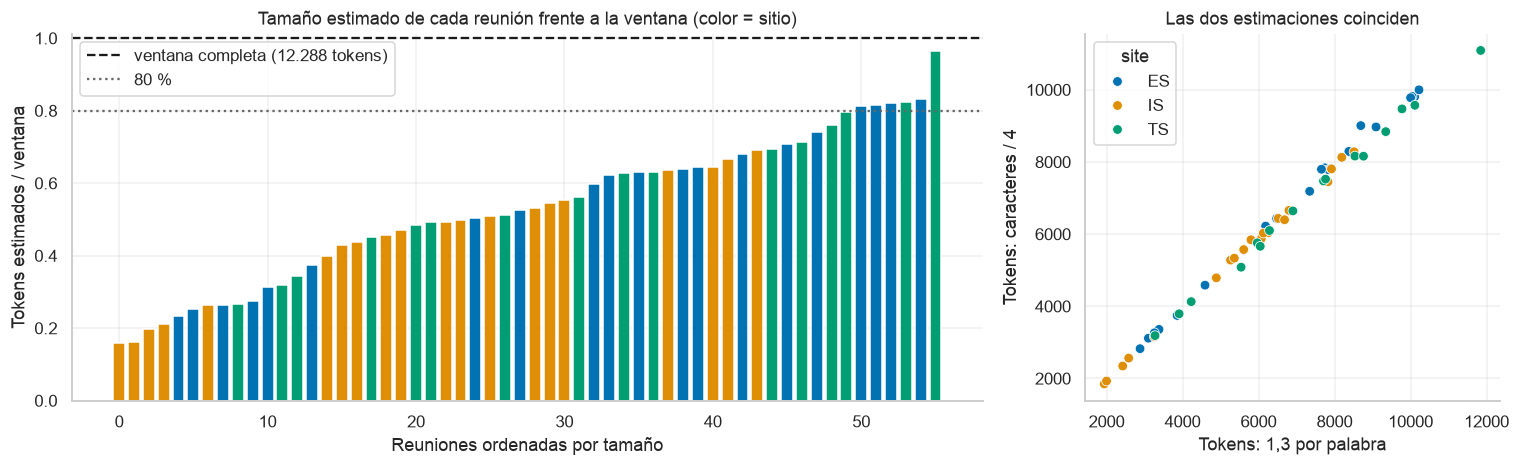

Longitud de los turnos (palabras), todas las reuniones


,n_turns,mean,std,min,q1,median,q3,p90,p99,max,share_single_word
0,25857,10.85,17.71,1.0,1.0,4.0,12.0,29.0,88.0,402.0,0.31


In [38]:
window_words = eda.DEFAULT_CONTEXT_TOKENS / TOKENS_PER_WORD
print(
    f"Ventana: {es(eda.DEFAULT_CONTEXT_TOKENS)} tokens ≈ {es(window_words)} palabras "
    f"({es(TOKENS_PER_WORD, 1)} tokens por palabra)"
)
print(f"Reuniones que caben (estimado): {int(MEETING['fits_context'].sum())} de {len(MEETING)}")
print(f"Reuniones con más de 80 % de la ventana: {int((MEETING['context_ratio'] > 0.8).sum())}")
print(f"Reuniones con más de 90 % de la ventana: {int((MEETING['context_ratio'] > 0.9).sum())}")
print(
    f"Series completas (palabras): mínimo {es(SERIES_T['total_words'].min())}, "
    f"máximo {es(SERIES_T['total_words'].max())}"
)

display(
    MEETING.loc[
        MEETING["context_ratio"] > 0.8,
        ["meeting_id", "n_words", "approx_tokens", "approx_tokens_chars", "context_ratio"],
    ]
    .sort_values("context_ratio", ascending=False)
    .round(3)
    .reset_index(drop=True)
)
display(
    MEETING.loc[
        MEETING["meeting_id"].str.startswith("ES2015"),
        ["meeting_id", "n_words", "approx_tokens", "context_ratio"],
    ]
    .round(3)
    .reset_index(drop=True)
)

orden = MEETING.sort_values("context_ratio")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].bar(range(len(orden)), orden["context_ratio"], color=[SITE_COLOR[s] for s in orden["site"]])
window_label = f"ventana completa ({es(eda.DEFAULT_CONTEXT_TOKENS)} tokens)"
axes[0].axhline(1.0, color="k", ls="--", label=window_label)
axes[0].axhline(0.8, color="0.4", ls=":", label="80 %")
axes[0].set_xlabel("Reuniones ordenadas por tamaño")
axes[0].set_ylabel("Tokens estimados / ventana")
axes[0].set_title("Tamaño estimado de cada reunión frente a la ventana (color = sitio)")
axes[0].legend(loc="upper left")
sns.scatterplot(
    data=MEETING,
    x="approx_tokens",
    y="approx_tokens_chars",
    hue="site",
    palette=SITE_COLOR,
    s=40,
    edgecolor="white",
    ax=axes[1],
)
axes[1].set_xlabel(f"Tokens: {es(TOKENS_PER_WORD, 1)} por palabra")
axes[1].set_ylabel("Tokens: caracteres / 4")
axes[1].set_title("Las dos estimaciones coinciden")
plt.tight_layout()
plt.show()

print("Longitud de los turnos (palabras), todas las reuniones")
display(eda.turn_length_distribution(TURNS).round(2))

**Respuesta a P1.** Según la estimación, **las 56 reuniones caben** en la ventana de 12.288 tokens (≈ 9.452 palabras). La mediana ocupa el 52,9 % de la ventana y la más grande, **TS3005d, el 96,4 %** (11.846 tokens estimados). Seis reuniones superan el 80 % (TS3005d, ES2008d, TS3009b, ES2002c, ES2002d y ES2014d) y solo una el 90 %. La estimación por caracteres da valores algo menores (11.089 en TS3005d, 9.570 en TS3009b); las dos estimaciones se mueven juntas (dispersión de la figura derecha).

**Los límites de la respuesta.**

- **Es una estimación, no una medición,** y es **optimista**: no cuenta las etiquetas de rol ni los saltos de línea de la transcripción, ni las instrucciones del sistema ni el espacio para la respuesta.
- **Caber en la estimación no equivale a leerse completa.** En el piloto con ES2015d, OpenKOS leyó un **extracto** y no la reunión entera, porque los prompts añaden carga a la ventana. ES2015d tiene 7.345 tokens estimados (59,8 % de la ventana), y aun así no se leyó completa. Por eso "56 de 56" debe leerse como **cota superior optimista**.
- **Ninguna serie completa cabe.** Las series tienen entre 14.990 y 26.204 palabras, de 1,6 a 2,8 veces las 9.452 que caben. Cada condición debe procesar la serie en partes (consistente con D15).

**Implicancia para C1 (chunking).** Los turnos son muy cortos: mediana de 4 palabras, **31,5 % de una sola palabra** (asentimientos como "yeah"), percentil 90 de 29 y percentil 99 de 88 palabras (máximo 402). Fragmentar por turno produciría fragmentos casi vacíos; el fragmento debe agrupar turnos. **Implicancia para C2:** con un margen de seguridad del 20 %, 6 de 56 reuniones deberían partirse o leerse por extracto.

## 10.2 P6 — ¿A qué distancia quedan los pares candidatos?

La **distancia** de un par es cuántas reuniones separan a sus dos decisiones: 1 si son consecutivas
(a→b), hasta 3 (a→d). El filtro de bloqueo selecciona candidatos con coeficiente de
solapamiento ≥ 0,30 y al menos 2 tokens compartidos.

,distancia,n,n_true (filtro),rate (filtro),n_true (solo coeficiente),rate (solo coeficiente)
0,1,1671,62,0.0371,421,0.2519
1,2,1058,26,0.0246,233,0.2202
2,3,342,4,0.0117,58,0.1696


Contingencia candidato por distancia:


meeting_distance,1,2,3
is_candidate,,,
False,1609,1032,338
True,62,26,4


{'test': 'chi2', 'statistic': 7.915925562008805, 'p_value': 0.019101989615490658, 'cramers_v': 0.050770441797777566}
[{'statistic': 18.9514, 'p_value': 0.0001, 'epsilon_squared': 0.0055, 'n': 3071}]


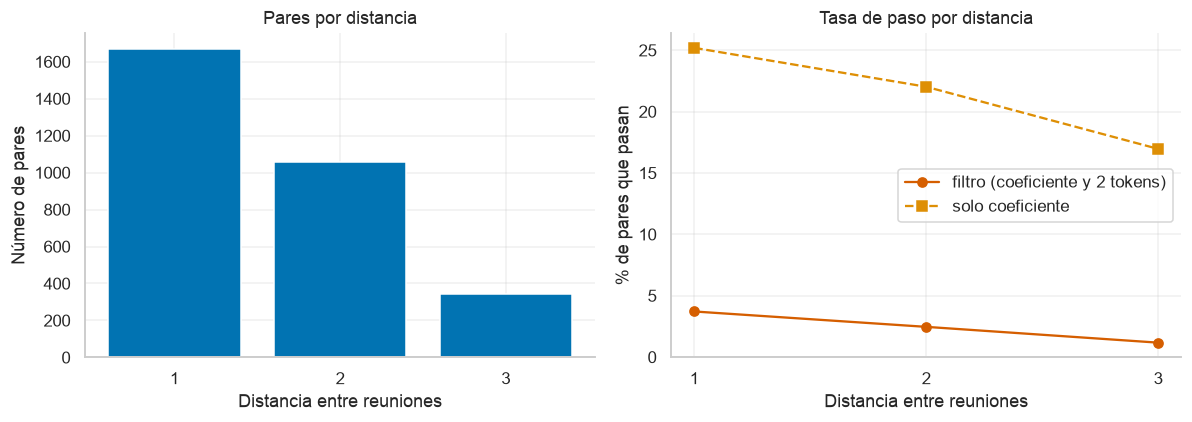

In [39]:
bins = [0, 1, 2, 3]
dist_cand = eda.rate_by_bin(PAIR, "meeting_distance", "is_candidate", bins, labels=["1", "2", "3"])
dist_solo = eda.rate_by_bin(
    PAIR_F, "meeting_distance", "passes_overlap", bins, labels=["1", "2", "3"]
)
dist = dist_cand.merge(dist_solo, on=["bin", "n"], suffixes=(" (filtro)", " (solo coeficiente)"))
display(dist.rename(columns={"bin": "distancia"}).round(4))
print("Contingencia candidato por distancia:")
display(tablas["Par candidato por distancia entre reuniones"])
print(
    chi_tabla.loc[
        "Par candidato por distancia entre reuniones", ["test", "statistic", "p_value", "cramers_v"]
    ].to_dict()
)
print(
    kr.loc[
        (kr["variable"] == "overlap") & (kr["grupos"] == "meeting_distance"),
        ["statistic", "p_value", "epsilon_squared", "n"],
    ]
    .round(4)
    .to_dict("records")
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(dist["bin"], dist["n"], color=PAL[0])
axes[0].set_xlabel("Distancia entre reuniones")
axes[0].set_ylabel("Número de pares")
axes[0].set_title("Pares por distancia")
axes[1].plot(
    dist["bin"],
    dist["rate (filtro)"] * 100,
    marker="o",
    color=PAL[3],
    label="filtro (coeficiente y 2 tokens)",
)
axes[1].plot(
    dist["bin"],
    dist["rate (solo coeficiente)"] * 100,
    marker="s",
    ls="--",
    color=PAL[1],
    label="solo coeficiente",
)
axes[1].set_xlabel("Distancia entre reuniones")
axes[1].set_ylabel("% de pares que pasan")
axes[1].set_title("Tasa de paso por distancia")
axes[1].legend()
plt.tight_layout()
plt.show()

**Respuesta a P6.** Los pares se reparten así: 1.671 a distancia 1 (54,4 %), 1.058 a distancia 2 (34,5 %) y 342 a distancia 3 (11,1 %); el reparto es estructural (hay más combinaciones de reuniones cercanas). La tasa de candidatos **baja con la distancia**: 3,7 % (62 de 1.671), 2,5 % (26 de 1.058) y 1,2 % (4 de 342). Con el coeficiente solo (sin el mínimo de tokens) la tendencia es la misma: 25,2 %, 22,0 % y 17,0 %.

- **Es una dependencia real pero pequeña:** chi-cuadrado p = 0,019 y V de Cramér = 0,051; en solapamiento por distancia ε² = 0,0055 (despreciable).
- **Consecuencia para E3:** de los 92 candidatos, 62 (67,4 %) son entre reuniones consecutivas, 26 (28,3 %) a distancia 2 y 4 (4,3 %) a distancia 3. Las **relaciones de largo alcance (a con d) son raras** entre los candidatos.
- **Dos explicaciones no excluyentes:** (1) una decisión suele revisarse o reafirmarse pronto, y (2) el filtro es **léxico**: con el paso del tiempo el vocabulario cambia y una relación real puede perder solapamiento. Este EDA no distingue entre ambas; la medición de lo que el filtro pierde (notebook 00 §4.1) es la que puede hacerlo.

## 10.3 P2 — ¿La tasa del filtro depende de la longitud de las frases?

En el notebook [00 (§4.1)](00-jss-corpus-y-auditoria.ipynb) se explica por qué el coeficiente de
solapamiento solo no basta: se define como compartidos / tamaño del conjunto menor, de modo que una
frase corta que comparte uno o dos tokens obtiene un coeficiente alto aunque el parecido sea
casual. La hipótesis HE2 es que ese mecanismo ("promiscuidad de las frases cortas") se ve en los
datos. Se mide la proporción de pares que pasa cada regla según el tamaño de la **decisión más
corta** del par, en tokens de contenido.

,tokens de la decisión más corta,n,n_true coef.,rate coef.,n_true filtro,rate filtro
0,1,18,0,0.0000,0,0.0000
1,2,303,111,0.3663,1,0.0033
2,3,1270,535,0.4213,25,0.0197
3,4,484,17,0.0351,17,0.0351
4,5-6,546,36,0.0659,36,0.0659
5,7-10,369,12,0.0325,12,0.0325
6,11+,81,1,0.0123,1,0.0123


Pares que pasan solo el coeficiente (≥ 0,30): 712
Pares que pasan solo los 2 tokens compartidos: 144
Pares que pasan ambas reglas (candidatos): 92  [is_candidate = 92]
Pares que pasan el coeficiente pero no los 2 tokens: 620


,x,y,method,r,p,n
0,shorter_tokens,overlap,spearman,-0.1509,0.0000,3071
1,shorter_tokens,shared_tokens,spearman,0.0142,0.4316,3071
2,overlap,shared_tokens,spearman,0.9609,0.0000,3071


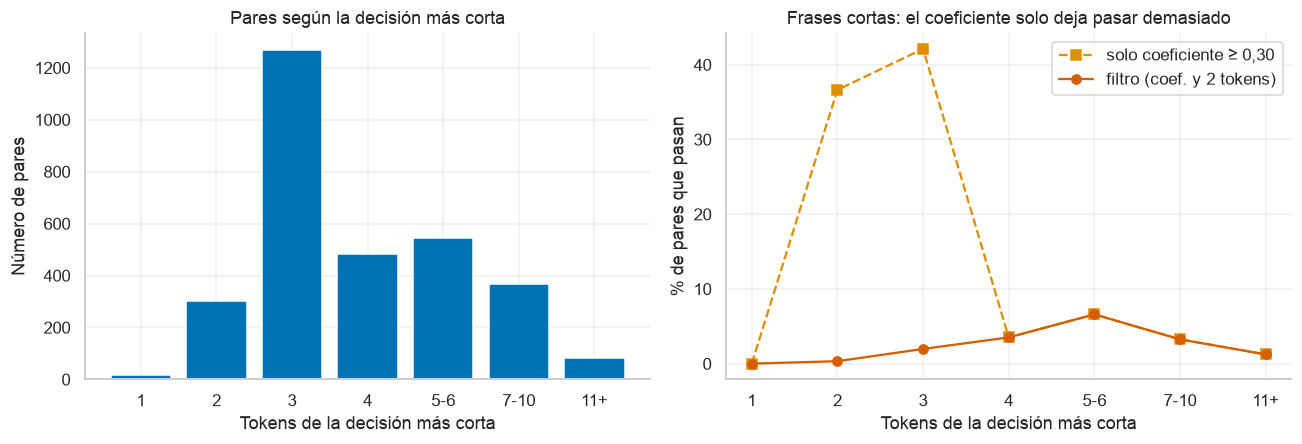

In [40]:
solo = eda.rate_by_bin(
    PAIR_F, "shorter_tokens", "passes_overlap", eda.LEN_BINS, labels=eda.LEN_LABELS
)
filtro = eda.rate_by_bin(
    PAIR_F, "shorter_tokens", "is_candidate", eda.LEN_BINS, labels=eda.LEN_LABELS
)
largo = solo.merge(filtro, on=["bin", "n"], suffixes=(" coef.", " filtro"))
display(largo.rename(columns={"bin": "tokens de la decisión más corta"}).round(4))

print(f"Pares que pasan solo el coeficiente (≥ 0,30): {int(PAIR_F['passes_overlap'].sum())}")
print(f"Pares que pasan solo los 2 tokens compartidos: {int(PAIR_F['passes_shared'].sum())}")
both_rules = int((PAIR_F["passes_overlap"] & PAIR_F["passes_shared"]).sum())
print(
    f"Pares que pasan ambas reglas (candidatos): {both_rules}"
    f"  [is_candidate = {int(PAIR_F['is_candidate'].sum())}]"
)
print(
    f"Pares que pasan el coeficiente pero no los 2 tokens: "
    f"{int((PAIR_F['passes_overlap'] & ~PAIR_F['passes_shared']).sum())}"
)
display(
    eda.correlation_table(
        PAIR_F, ["shorter_tokens", "overlap", "shared_tokens"], ["spearman"]
    ).round(4)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(largo["bin"], largo["n"], color=PAL[0])
axes[0].set_xlabel("Tokens de la decisión más corta")
axes[0].set_ylabel("Número de pares")
axes[0].set_title("Pares según la decisión más corta")
axes[1].plot(
    largo["bin"],
    largo["rate coef."] * 100,
    marker="s",
    ls="--",
    color=PAL[1],
    label="solo coeficiente ≥ 0,30",
)
axes[1].plot(
    largo["bin"],
    largo["rate filtro"] * 100,
    marker="o",
    color=PAL[3],
    label="filtro (coef. y 2 tokens)",
)
axes[1].set_xlabel("Tokens de la decisión más corta")
axes[1].set_ylabel("% de pares que pasan")
axes[1].set_title("Frases cortas: el coeficiente solo deja pasar demasiado")
axes[1].legend()
plt.tight_layout()
plt.show()

**Respuesta a P2: sí, la tasa depende de la longitud de las frases, y HE2 se confirma.**

- **El coeficiente solo deja pasar 712 pares (23,2 %); el filtro completo, 92.** Los 620 de diferencia (87,1 % de los 712) pasan el coeficiente pero comparten menos de 2 tokens. Solo 144 pares comparten al menos 2 tokens; 92 cumplen ambas reglas.
- **La promiscuidad está en las frases cortas.** Cuando la decisión más corta del par tiene **2 o 3 tokens** (1.573 pares), el coeficiente deja pasar el 36,6 % (111 de 303) y el 42,1 % (535 de 1.270) respectivamente, mientras que el filtro completo deja pasar solo 0,3 % (1) y 2,0 % (25). Son 646 de los 712 pares (90,7 %) que pasan el coeficiente. Para 4 tokens o más ambas reglas **coinciden** (con 4 tokens, un coeficiente de 0,30 ya exige 2 compartidos) y las tasas son idénticas: 3,5 % con 4 tokens, 6,6 % con 5–6, 3,3 % con 7–10 y 1,2 % con 11 o más.
- **Mecanismo.** El coeficiente divide por el tamaño del conjunto menor, así que una frase corta que comparte uno o dos tokens, quizá por azar, alcanza 0,30 con facilidad. Los tokens compartidos, en cambio, **no dependen de la longitud** (ρ = 0,014 con la decisión más corta, p = 0,43); por eso la regla absoluta es un filtro neutral frente a ella. El solapamiento sí baja con la longitud (ρ = −0,151).
- **El filtro no elimina la dependencia, la desplaza.** Con el filtro la tasa sube con la longitud hasta 5–6 tokens (6,6 %) y luego baja (1,2 % con 11 o más). Las frases de 3 tokens o menos, que forman la mayoría de los pares, casi nunca son candidatas.

**Consecuencia.** Si una relación real une dos frases telegráficas de 2 o 3 tokens, el filtro probablemente la descarta: es el sesgo que el notebook 00 (§4.1) anticipó, aquí con la cuantificación. La exposición es relevante para el recall del filtro, que se mide contra la adjudicación de desarrollo; esa medición, no el EDA, determina cuántas relaciones se pierden.

## 10.4 P9 — Sensibilidad del filtro a su punto de operación

Se repite el recorrido del notebook 00 (§4.1): cuántos candidatos quedan en cada celda de la
malla (umbral del coeficiente × mínimo de tokens compartidos) y si el único par revertido
verificado a mano (el del botón turbo) sobrevive.

,threshold,min_overlap_tokens,n_candidates,pct_of_total_pairs,turbo_button_survives
0,0.3,1,712,23.18,True
1,0.3,2,92,3.00,True
2,0.3,3,29,0.94,False
3,0.4,1,184,5.99,True
4,0.4,2,74,2.41,True
5,0.4,3,24,0.78,False
6,0.5,1,163,5.31,False
7,0.5,2,53,1.73,False
8,0.5,3,19,0.62,False


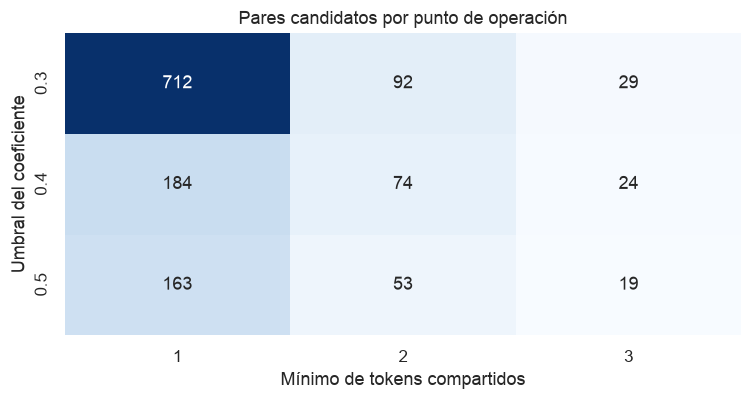

In [41]:
grid = audit.blocker_sensitivity(
    series=SERIES, thresholds=(0.30, 0.40, 0.50), min_overlaps=(1, 2, 3)
)
display(grid.round(2))

fig, ax = plt.subplots(figsize=(7, 3.8))
tabla_grid = grid.pivot(index="threshold", columns="min_overlap_tokens", values="n_candidates")
sns.heatmap(tabla_grid, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_xlabel("Mínimo de tokens compartidos")
ax.set_ylabel("Umbral del coeficiente")
ax.set_title("Pares candidatos por punto de operación")
ax.grid(False)
plt.tight_layout()
plt.show()

**Respuesta a P9.** El filtro es **muy sensible al mínimo de tokens compartidos y poco al umbral del coeficiente**.

- Con umbral 0,30, pasar de exigir 1 token compartido a exigir 2 reduce los candidatos de **712 a 92** (−87 %); exigir 3 los baja a 29. Con mínimo 2, subir el umbral de 0,30 a 0,40 y a 0,50 da 92, 74 y 53 candidatos.
- **El par del botón turbo es el control de recall y sobrevive en 4 de las 9 celdas:** las de umbral 0,30 o 0,40 con mínimo 1 o 2. Lo pierde con mínimo 3 (comparte exactamente 2 tokens) o con umbral 0,50 (su coeficiente es 0,40). El punto de operación adoptado (0,30 y 2) conserva el par, pero **con el menor margen posible**: cualquier endurecimiento adicional lo pierde.
- Es una **sola** observación de control, de modo que la sensibilidad en el recall solo está medida en un punto. Esto refuerza que el recall real se mide con la adjudicación de desarrollo (notebook 01) y no con esta malla.

## 10.5 P3, P4, P5, P7 — Respuestas con evidencia y explicaciones alternativas

Las demás preguntas se contestaron en sus secciones; aquí se recogen, junto con dos análisis
adicionales sobre P7 (quién respalda las decisiones) y las explicaciones alternativas de lo
encontrado.

,role,site,count,share
14,PM,ALL,322,0.470073
12,ID,ALL,156,0.227737
13,ME,ALL,105,0.153285
15,UI,ALL,102,0.148905


,nivel,variable,grupos,statistic,p_value,epsilon_squared,n,n_groups
11,hablante-reunión,talk_share,role,52.2969,0.0,0.2241,224,4
12,hablante-reunión,n_decision_acts,role,51.7895,0.0,0.2218,224,4


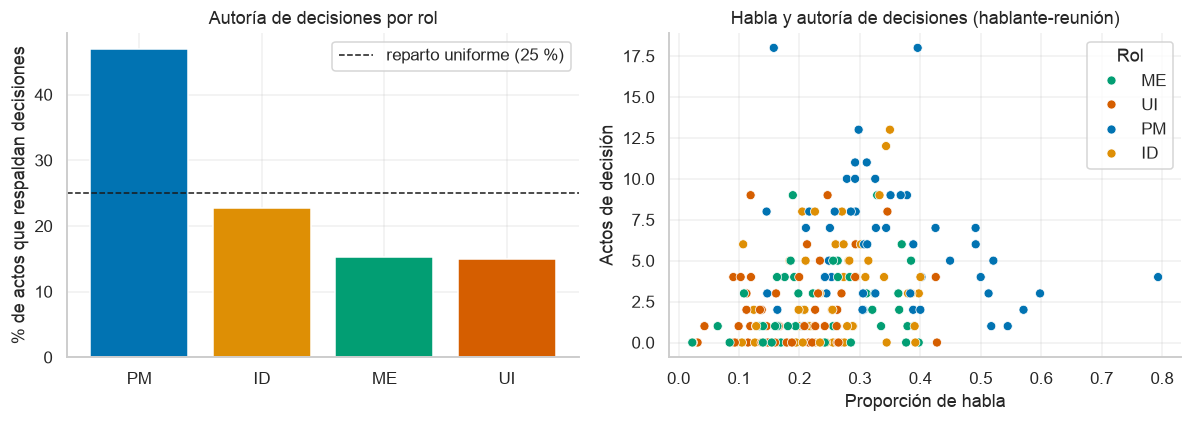

In [42]:
roles = audit.role_authorship(series=SERIES)
display(roles[roles["site"] == "ALL"].sort_values("share", ascending=False))
display(kr[kr["grupos"] == "role"].round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
total = roles[roles["site"] == "ALL"].sort_values("share", ascending=False)
axes[0].bar(total["role"], total["share"] * 100, color=[ROLE_COLOR[r] for r in total["role"]])
axes[0].axhline(25, color="k", ls="--", lw=1, label="reparto uniforme (25 %)")
axes[0].set_ylabel("% de actos que respaldan decisiones")
axes[0].set_title("Autoría de decisiones por rol")
axes[0].legend()
sns.scatterplot(
    data=SPEAKER,
    x="talk_share",
    y="n_decision_acts",
    hue="role",
    palette=ROLE_COLOR,
    s=35,
    edgecolor="white",
    ax=axes[1],
)
axes[1].set_xlabel(LABEL["talk_share"])
axes[1].set_ylabel(LABEL["n_decision_acts"])
axes[1].set_title("Habla y autoría de decisiones (hablante-reunión)")
axes[1].legend(title="Rol")
plt.tight_layout()
plt.show()

**P7: ¿quién respalda las decisiones?** El PM concentra **322 de 685 actos de evidencia (47,0 %)**, frente a 156 del ID (22,8 %), 105 del ME (15,3 %) y 102 del UI (14,9 %); un reparto parejo daría 25 %. Esa autoría **no depende del sitio** (§6.2, V = 0,119, p = 0,34), pero **está mezclada con el volumen de habla**: el PM habla más (ε² = 0,224) y quienes más hablan aportan más actos (ρ = 0,507). Con estos datos no se puede separar "el PM decide más" de "el PM habla más". Un análisis que normalice los actos de decisión por palabras dichas, no incluido aquí, sería el siguiente paso.

**Respuestas a las preguntas de §0.**

| | Pregunta | Respuesta con evidencia |
|---|---|---|
| P1 | ¿Caben las reuniones? | Sí según la estimación (56 de 56); la mayor ocupa 96,4 %; 6 superan 80 %; el piloto con ES2015d (59,8 %) leyó un extracto (§10.1) |
| P2 | ¿La tasa depende de la longitud? | Sí: el coeficiente solo deja pasar 42,1 % de los pares con una decisión de 3 tokens, el filtro 2,0 % (§10.3) |
| P3 | ¿Hay diferencias por sitio? | De volumen, sí en duración (ε² = 0,16) y de forma no significativa en palabras, turnos y decisiones (ε² 0,06 a 0,07); no en la estructura de las decisiones (rol, evidencia, candidato; p ≥ 0,20). Excepción menor: la longitud de las frases (ε² = 0,044) |
| P4 | ¿Cambia la actividad a→d? | Sí, con un quiebre a→b: la reunión a tiene la mitad de decisiones (3,6 frente a 7,6) y de duración; de b a d es plano (§9) |
| P5 | ¿Qué falta y por qué? | Tres variables; hora de inicio y lengua son estructurales por sitio; la evidencia nula (26) depende de la posición y es la que importa (§3) |
| P6 | ¿Qué distancia tienen los candidatos? | 67,4 % a distancia 1; la tasa baja de 3,7 % a 1,2 % (§10.2) |
| P7 | ¿Quién respalda las decisiones? | El PM, 47,0 %; mezclado con su volumen de habla (§10.5) |
| P8 | ¿Hay estructura multivariada? | No: un continuo de tamaño; los grupos reproducen la posición (§8) |
| P9 | ¿Qué tan sensible es el filtro? | Muy sensible al mínimo de tokens (712 a 92), poco al umbral (§10.4) |

**Explicaciones alternativas** a los hallazgos principales:

- **Dependencia de la tasa con la longitud (P2).** Además del mecanismo del coeficiente, podría influir el **estilo de redacción de cada serie**: IS1008 tiene la mediana de frase más larga (12 tokens) y la tasa de candidatos más alta (13,3 %), compatible con que las frases largas compartan más tokens. Con 14 series no se puede separar el efecto de la longitud del efecto de la serie.
- **Quiebre temporal (P4).** Que la primera reunión sea la mitad de larga puede deberse al diseño del escenario (una reunión inicial más breve) y no a un cambio en la actividad de decisión; los datos no distinguen entre ambas lecturas.
- **Diferencias por sitio (P3).** La duración puede reflejar el protocolo de grabación de cada sitio. El sitio, además, está **anidado** con la lengua y con los anotadores del resumen, que se desconocen: el efecto del "sitio" es una mezcla.
- **Autoría del PM (P7).** Podría reflejar el diseño del escenario, donde el PM dirige la reunión, y no una propiedad del equipo.

---

# 11. Síntesis e implicancias para el modelado

## 11.1 Hallazgos

| # | Hallazgo | Evidencia / cifra | Sección | Implicancia |
|---|---|---|---|---|
| 1 | Los datos son íntegros en llaves y reglas, salvo duplicados | 15 de 17 reglas; 4 exactas y 8 casi duplicadas, todas en reuniones consecutivas | §2 | Son reafirmaciones reales (relevantes para E3); se conservan con marca |
| 2 | Faltan datos solo en tres variables, y de forma estructural | `start` 32/56; lengua 64/224 (todo TS); evidencia 26/343; capa DDS en 6 de 14 series | §3 | No se imputa (D3); documentar como limitación |
| 3 | La evidencia nula crece con la posición y es señal de posible error | 0 % (a), 4,7 % (b), 11,2 % (c), 11,5 % (d); el botón turbo tiene evidencia 0 | §3, §5.5 | Revisar siempre las 26 decisiones sin evidencia al adjudicar |
| 4 | Las reuniones son un continuo de tamaño; las decisiones son frases telegráficas | Reunión: 5.010 palabras de media; decisión: mediana de 5 tokens y moda de 3 | §4 | Una sola dimensión de tamaño; cuidado con pruebas que suponen simetría |
| 5 | Los atípicos son fenómenos reales, salvo metadatos de duración | 15 reuniones marcadas, 0 excluidas; brechas de duración de hasta 300 s | §5 | Usar palabras y turnos, no `duration_seconds`, como medida de tamaño |
| 6 | Sitio y lengua están anidados | V = 0,87; todos los hablantes de TS tienen lengua desconocida | §3, §6 | El sitio es el factor de balance (D7, D8); la lengua es limitación |
| 7 | La estructura de las decisiones no depende del sitio | Rol que respalda, evidencia y candidato: p ≥ 0,20 | §6 | Se sostiene balancear por sitio sin estratificar más |
| 8 | Las tasas de candidatos y de decisiones se concentran en reuniones cercanas y tardías | 67,4 % de los candidatos a distancia 1; decisiones 51, 107, 89 y 96 por posición | §9, §10.2 | El banco de preguntas de evolución se apoya en b, c y d |
| 9 | El tamaño pesa más que el sitio | Posición: ε² = 0,52 en palabras; sitio: ε² = 0,07 | §6.3 | Incluir posición como covariable |
| 10 | Variables de tamaño fuertemente colineales | VIF de 7 a 26; palabras con duración r = 0,92 | §7 | Usar una sola medida de tamaño |
| 11 | La estructura multivariada no añade valor | Silueta máxima de 0,45; los grupos reproducen la posición | §8 | Sitio y posición bastan como estratos |
| 12 | Las reuniones caben en la ventana (estimado), con poco margen en las mayores | 56/56; máximo 96,4 %; 6 sobre 80 %; el piloto de ES2015d leyó un extracto | §10.1 | Reservar margen para prompts; planear partir las reuniones mayores |
| 13 | El filtro depende de la longitud de las frases | Pares con decisión de 3 tokens: 42,1 % pasan el coeficiente, 2,0 % el filtro | §10.3 | El filtro puede descartar relaciones entre frases de 2 o 3 tokens; medir recall |
| 14 | El filtro es sensible al mínimo de tokens | 712 a 92 candidatos; el par de control sobrevive con margen mínimo | §10.4 | Mantener el punto de operación (D9) y no endurecerlo |
| 15 | La autoría del PM se mezcla con su volumen de habla | PM 47,0 % de los actos; ρ(palabras, actos) = 0,507 | §10.5 | No leer el 47,0 % como efecto del rol sin normalizar por habla |

## 11.2 Decisiones de limpieza

**Bitácora de decisiones de limpieza.** La política es de **no eliminar ni corregir datos**; solo se marcan y se documentan.

| Decisión | Motivo | Dónde se registra |
|---|---|---|
| No imputar ningún faltante | Las etiquetas son humanas (D3); imputar evidencia fabricaría proveniencia | §3.4 |
| No eliminar duplicados; mantener `exact_duplicate` y `near_duplicate` | Son reafirmaciones reales; relevantes para E3 | §2.4 |
| No eliminar ninguno de los 15 atípicos multivariados ni los 10 de decisión | Son fenómenos reales; el chequeo de coherencia no mostró error de captura | §5.6 |
| No usar `duration_seconds` como variable explicativa | Brechas de hasta 300 s con la transcripción en 4 reuniones | §5.3 |
| Tratar la evidencia cero como señal de revisión durante la adjudicación | El error conocido (botón turbo) tiene evidencia cero | §3.3, §5.5 |
| Reportar resultados por reunión con y sin TS3005d | Es el único atípico por los cuatro métodos | §5.6 |
| Usar una sola medida de tamaño de reunión en cualquier modelo | VIF de 7 a 26 entre las seis variables | §7.3 |

**Resultado neto sobre los datos: 0 filas eliminadas, 0 valores corregidos, 0 valores imputados.**

## 11.3 Implicancias para el diseño

**C1: fragmentación (chunking).** Los turnos son telegráficos (mediana de 4 palabras; 31,5 % de una palabra), así que el fragmento no puede ser el turno: debe agrupar turnos. Una serie completa es de 1,6 a 2,8 veces la ventana, de modo que C1 necesita recuperar fragmentos y no puede leer la serie.

**C2: ventana de contexto y extracción.** Con la estimación actual, 56 reuniones caben pero 6 ocupan más del 80 % y una el 96,4 %. Como la estimación es optimista y el piloto de ES2015d (59,8 %) leyó un extracto, **conviene planificar la extracción por segmentos o con margen reservado**, en vez de dar por hecho que la reunión entra completa. La ventana efectiva debe medirse con el tokenizador real, y el efecto de la longitud de la reunión sobre el error de extracción debe verse en OE2.

**El filtro de bloqueo.** El mínimo de tokens compartidos es el parámetro dominante; se mantiene el punto de operación de D9. El filtro es neutral frente a la longitud en su regla absoluta, pero deja casi sin candidatos a las frases de 2 o 3 tokens. Debe reportarse como **limitación**, y el recall debe medirse con la adjudicación de desarrollo.

**El banco de preguntas y sus estratos.**

- **E3 (evolución)** se apoyará sobre todo en pares de reuniones consecutivas (67,4 % de los candidatos) y en las reuniones b, c y d.
- **El sitio no cambia la tasa de candidatos** (p = 0,66), de modo que muestrear por sitio es razonable. Los candidatos se reparten 44 en ES, 22 en IS y 26 en TS.
- **Las series difieren mucho** (de 1 a 14 candidatos por serie, con IS1008 en 13,3 %): conviene **limitar cuántas preguntas sale de cada serie**, para que ninguna domine el estrato.
- Incluir los **casos de reafirmación** (duplicados) como un subtipo de E3.
- Las decisiones sin evidencia (26, concentradas en reuniones tardías) deben revisarse antes de que alimenten preguntas.

**Modelado estadístico posterior.** Usar posición y sitio como covariables; elegir una sola medida de tamaño; preferir Spearman o Kendall para los conteos; y reportar los tamaños de efecto, no solo los valores p.

## 11.4 Limitaciones, hipótesis emergentes y qué se repetirá

**Limitaciones.**

- **Muestra no aleatoria.** Son 14 series elegidas por criterios; el corpus tiene un único dominio y habla actuada. No se extrapola a otros corpus.
- **Tamaño de reunión estimado.** Los tokens son una estimación (1,3 por palabra), optimista; no hay tokenizador del modelo.
- **Las decisiones son frases de resumen.** Pueden contener errores de origen, como el botón turbo, que ninguna estadística detecta.
- **Potencia baja.** Con 14 series o 56 reuniones, muchos efectos medianos no alcanzan significancia; los p de los niveles de hablante y de par son optimistas por falta de independencia.
- **Clasificaciones estructurales.** Al no poder leer las series de evaluación (ADR 0005), la distinción entre error y fenómeno se apoya en la estructura y en el chequeo de coherencia; el contenido se verificará, donde sea admisible, al adjudicar.
- **Metadatos de duración imprecisos** en algunas reuniones; se evita usarlos.
- **Sin etiquetas de relación al momento de este EDA (2026-09).** Desde entonces ES2015 tiene etiquetas adjudicadas (notebook 04); para el resto de las series OE1 sigue pendiente. Este EDA describe los candidatos, no cuántos son relaciones reales.
- **Sin prueba formal de MCAR** (por ejemplo, la de Little): se usó el tamizaje por covariables, que descarta MCAR pero no lo prueba cuando no encuentra asociación.
- **Eje temporal** de solo cuatro posiciones: no se estudian estacionalidad ni autocorrelación.

**Hipótesis emergentes** (para contrastar con el experimento, no confirmadas por el EDA):

1. **HN1.** Las decisiones tardías (c y d) quedan sin evidencia con más frecuencia porque son reafirmaciones o síntesis sin un acto único; la tasa sube de 0 % a 11,5 %.
2. **HN2.** El filtro pierde sobre todo relaciones entre frases cortas; el recall será menor en ellas.
3. **HN3.** Las reuniones que ocupan más del 80 % de la ventana tendrán más errores de extracción en C2.
4. **HN4.** La concentración de autoría en el PM se reduce al normalizar por habla.

**Qué se repetirá tras ejecutar OpenKOS (iteración post-modelado).**

- Medir el tamaño real de las reuniones con el tokenizador del modelo y comparar con la ventana efectiva.
- Distribución de los errores de extracción por posición, sitio, longitud de la reunión y tamaño de la frase.
- Recall y precisión reales del filtro, con la adjudicación; comprobar HN2.
- Repetir el EDA sobre las etiquetas humanas de OE1 (acuerdo, kappa, tasa de relaciones por estrato).
- Revisar los atípicos a la luz de las fallas de extracción y contrastar HN1 a HN4.

## 11.5 Checklist del EDA para el preinforme

| Ítem del checklist | Estado | Dónde | Observación |
|---|---|---|---|
| Objetivo y preguntas del análisis definidos | ✅ | §0 | 4 objetivos, 9 preguntas, 6 hipótesis exploratorias |
| Proveniencia, licencia y muestreo descritos | ✅ | §1, §12 | CC BY 4.0; muestra elegida con criterios del ADR 0004 |
| Revisión general: dimensiones, tipos, diccionario | ✅ | §2.1, §2.2 | 77 variables documentadas |
| Reglas de consistencia y llaves; duplicados | ✅ | §2.3, §2.4 | 15 de 17; duplicados clasificados |
| Valores faltantes: cuántos, dónde, mecanismo | ✅ | §3 | MCAR/MAR/MNAR; no se imputa |
| Análisis univariado (posición, dispersión, forma) | ✅ | §4 | media, mediana, moda, varianza, IQR, CV, asimetría, curtosis |
| Valores atípicos (Z, IQR, LOF, MCD) y su tratamiento | ✅ | §5 | bitácora; 0 exclusiones |
| Análisis bivariado (dispersión, contingencia, mosaico, pruebas con tamaño de efecto) | ✅ | §6 | Kruskal-Wallis con ε²; χ² con V de Cramér |
| Dependencias: Pearson, Spearman, Kendall, VIF, confusores | ✅ | §7 | estratificación por posición y sitio |
| Análisis multivariado (PCA, agrupamiento) y su valor | ✅ | §8 | conclusión honesta: estructura débil |
| Análisis temporal | ✅ | §9 | eje: posición en la serie |
| Visualización clara, rotulada y apta para daltonismo | ✅ | todo el notebook | paleta "colorblind"; ejes en español |
| Preguntas respondidas con evidencia | ✅ | §10 | tabla P1 a P9 |
| Síntesis, decisiones de limpieza, limitaciones | ✅ | §11 | |
| Buenas prácticas: ética y reproducibilidad | ✅ | §12 | verificación automática del ADR 0005 |
| Imputación de faltantes | No aplica | §3.4 | Se decidió no imputar (D3) |
| Prueba de Little para MCAR | No aplica | §11.4 | No implementada; se usó el tamizaje por covariables |
| Series de tiempo con calendario, estacionalidad y autocorrelación | No aplica | §9 | Cuatro puntos por serie; el eje es la posición |
| Modelos predictivos | No aplica | | No es el propósito de este EDA |

---

# 12. Ética y reproducibilidad

## 12.1 Verificaciones automáticas

La regla del ADR 0005 (solo agregados, nada de contenido) y la integridad de las transcripciones
congeladas se comprueban aquí en lugar de afirmarse.

In [43]:
FORBIDDEN = {"content", "text", "earlier_text", "later_text"}
auditadas = {**LEVELS, "turnos": TURNS, "evidencia": EVIDENCE, "actos": ACT_IDS}
for nombre, tabla in auditadas.items():
    assert FORBIDDEN.isdisjoint(tabla.columns), f"{nombre}: columna de texto"
    candidatas = tabla.select_dtypes(exclude=["number", "bool", "datetime"]).columns
    texto = [c for c in candidatas if tabla[c].astype(str).str.len().max() > 60]
    assert not texto, f"{nombre}: columnas con cadenas largas {texto}"
print(f"Sin columnas de texto en las {len(auditadas)} tablas analizadas: OK")

manifest = pd.read_csv(
    PROJECT_ROOT / "reports" / "tables" / "transcripts_manifest.csv",
    usecols=["meeting_id", "sha256_md", "sha256_jsonl", "renderer_revision"],
)
print(
    f"Manifiesto congelado: {len(manifest)} reuniones con SHA-256 por artefacto "
    f"(revisión del renderizador: {', '.join(sorted(manifest['renderer_revision'].unique()))})"
)
print(
    "Las 56 reuniones del EDA están en el manifiesto:",
    bool(MEETING["meeting_id"].isin(manifest["meeting_id"]).all()),
)
print("Longitud de los hash (hex):", manifest["sha256_md"].str.len().unique().tolist())

paquetes = ["pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "seaborn"]
print("Python", platform.python_version(), "· versiones:", {p: version(p) for p in paquetes})

Sin columnas de texto en las 8 tablas analizadas: OK
Manifiesto congelado: 171 reuniones con SHA-256 por artefacto (revisión del renderizador: 7d479d2c692a)
Las 56 reuniones del EDA están en el manifiesto: True
Longitud de los hash (hex): [64]
Python 3.13.13 · versiones: {'pandas': '3.0.6', 'numpy': '2.5.3', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}


## 12.2 Ética

- **Datos de personas.** Los participantes de AMI aparecen solo mediante identificadores seudónimos públicos del corpus; este notebook no muestra ninguno ni nombre alguno, y el nivel hablante-reunión no contiene texto.
- **Licencia.** AMI se distribuye con CC BY 4.0: se reutiliza con atribución a Carletta et al. (2006). El corpus no se redistribuye con el repositorio (está en `.gitignore`); se descarga con un comando.
- **ADR 0005 respetado.** Solo se analizan estadísticas agregadas y conteos. Las series de evaluación aparecen únicamente por sus identificadores y cifras. La celda de §12.1 verifica que ninguna tabla analizada tenga columnas de texto (`content`, `text`, `earlier_text`, `later_text`) ni cadenas largas, y la regla se cumple.
- **Clasificaciones sin leer.** Donde habría sido necesario leer contenido de evaluación (duplicados, atípicos), el análisis se limitó a lo estructural y se declaró como limitación (§11.4).

## 12.3 Principios FAIR

| Principio | Cómo se aplica |
|---|---|
| **Localizable** (*Findable*) | Identificadores estables de serie, reunión y decisión; manifiesto congelado con SHA-256 por reunión; documentación versionada en el repositorio |
| **Accesible** (*Accessible*) | Corpus público con descarga reproducible (`uv run afg corpus download`); el repositorio está disponible para el equipo y los revisores |
| **Interoperable** (*Interoperable*) | Formatos abiertos (XML de AMI, JSONL, CSV); diccionario de datos con tipos, unidades y dominios |
| **Reutilizable** (*Reusable*) | Licencia explícita, proveniencia documentada (§1), versiones fijadas y funciones con test que regeneran cada cifra |

## 12.4 Reproducibilidad

- **Datos congelados.** El manifiesto lista 171 reuniones con el hash SHA-256 de sus dos artefactos y la revisión del renderizador; las 56 reuniones de este EDA están incluidas.
- **Versiones fijadas.** El archivo `uv.lock` fija todas las dependencias; las versiones usadas se imprimen en §12.1.
- **Semilla fija.** Toda aleatoriedad usa la semilla 0 (`k-medias` y MCD reciben la semilla; LOF y Ward son deterministas).
- **Ejecución de punta a punta:**

```bash
uv run afg corpus download
uv run afg corpus transcripts
uv run --group notebooks jupyter nbconvert --to notebook --execute --inplace \
  --ExecutePreprocessor.timeout=1800 notebooks/03-jss-eda.ipynb
```

- **Revisión por pares.** Todo cambio llega a `main` mediante una pull request con revisión (`CONTRIBUTING.md` §2). Los notebooks se versionan con sus resultados, para que un revisor pueda leerlos sin ejecutar nada.
- **Lo que este notebook no resuelve.** Sus conclusiones valen para estas 14 series y para el estado actual de las anotaciones de AMI; deberán revisarse con las etiquetas de OE1 y con la salida de OpenKOS (§11.4).